# ITT Barrio Obrero — Comuna 9, Cali
## Indice de Transformacion Territorial · 5 Dimensiones · 2023-2026
---
**Zona:** Barrio Obrero (poligono unico, sin tramos)  
**Normalizacion:** ref_min / ref_max fijos por indicador (juicio experto)  
**Dimensiones:** Seguridad y Convivencia (27%) · Movilidad y Accesibilidad (22%) · Desarrollo Social (19%) · Entorno Urbano (17%) · Actividad Economica (15%)  
**Periodo:** 2023 - 2025 -prov 2026


## Celda 1 — Instalacion de dependencias


In [119]:
# Descomentar en Colab
!pip install geopandas pyproj shapely openpyxl matplotlib seaborn folium -q

import subprocess, sys
def check_pkg(pkg):
    try: __import__(pkg)
    except ImportError: subprocess.check_call([sys.executable,'-m','pip','install',pkg,'-q'])
for p in ['geopandas','pyproj','shapely','openpyxl','seaborn','folium']: check_pkg(p)
print('Dependencias verificadas')


Dependencias verificadas


## Celda 2 — Importaciones y configuracion


In [120]:
import json, os, warnings
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import folium
warnings.filterwarnings("ignore")

# Paleta Okabe-Ito (accesible para daltonismo)
OKI_AZUL     = "#0072B2"
OKI_NARANJA  = "#E69F00"
OKI_VERDE    = "#009E73"
OKI_AMARILLO = "#F0E442"
OKI_AZUL_C   = "#56B4E9"
OKI_BERMELL  = "#D55E00"
OKI_MORADO   = "#CC79A7"
OKI_GRIS     = "#333333"

# Color por dimension
C_SEG = OKI_AZUL
C_MOV = OKI_NARANJA
C_COH = OKI_VERDE
C_ITT = OKI_GRIS
BG    = "#F4F6F9"

NIVEL_COLORS = {
    "Activacion":     OKI_BERMELL,
    "Consolidacion":  OKI_NARANJA,
    "Transformacion": OKI_VERDE,
    "Escala":         OKI_AZUL,
}

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": "white",
    "font.family": "DejaVu Sans",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
})
print("Configuracion visual lista - Paleta Okabe-Ito activa")

Configuracion visual lista - Paleta Okabe-Ito activa


In [121]:
!pwd
!ls /content
!find /content -maxdepth 3 -type d -iname "*itt*"


/content
cache
itt_cobertura_datos_2026.png
itt_obrero_ciiu_vocacion.png
itt_obrero_coh_trim.png
itt_obrero_de_evol.png
itt_obrero_de_evolucion_anual.png
itt_obrero_de_evolucion.png
itt_obrero_deficit_card.png
itt_obrero_de_heatmap.png
itt_obrero_de_slope.png
itt_obrero_de_trim.png
itt_obrero_educacion_base.png
itt_obrero_educacion_evolucion.png
itt_obrero_educacion_heatmap.png
itt_obrero_educacion_trim.png
itt_obrero_educ_evol.png
itt_obrero_entorno_evolucion.png
itt_obrero_entorno_heatmap.png
itt_obrero_evolucion_global.png
itt_obrero_global.png
itt_obrero_heatmap_coh.png
itt_obrero_heatmap_mov.png
itt_obrero_heatmap_seg.png
itt_obrero_ingresos_anual_trimestral_mediana.png
itt_obrero_ingresos_contextual_mediana.png
itt_obrero_ingresos_trim.png
itt_obrero_mov_trim.png
itt_obrero_radar.png
itt_obrero_seg_trim.png
itt_obrero_vulnerabilidad.png
itt_repos_cali
sample_data
simat_6a_dic_2023.xlsx
simat_6a_dic_2024.xlsx
simat_6a_dic_2025.xlsx
/content/itt_repos_cali
/content/itt_repos_cali/d

In [122]:
# [Neutralizada] El clone del repo lo hace la celda siguiente de forma robusta
# (ruta consistente /content/itt_repos_cali). Esta celda clonaba a Itt_repos_cali
# con I mayúscula y causaba conflicto de rutas en Colab (Linux es case-sensitive).
print("Clone se realiza en la celda siguiente.")


Clone se realiza en la celda siguiente.


## Celda 3A — Subida ZIP (Colab)


In [123]:
import os, shutil, subprocess
from pathlib import Path

REPO_URL  = "https://github.com/j0rg3c45/Itt_repos_cali.git"
REPO_PATH = "/content/itt_repos_cali"

# Clona SIEMPRE a la misma ruta consistente (minúsculas), robusto ante force-push
# y evitando el conflicto de mayúsculas con el nombre del repo. subprocess en vez
# de magics '!' para que no haya problemas de interpolación.
shutil.rmtree(REPO_PATH, ignore_errors=True)
subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_PATH], check=True)

DATA_DIR = Path(REPO_PATH) / "data" / "itt_barrio_obrero"
print("Carpetas disponibles en", DATA_DIR, ":")
if DATA_DIR.exists():
    for p in sorted(DATA_DIR.iterdir()):
        mark = "OK" if (p.is_dir() or p.suffix == ".geojson") else "  "
        print(f"  {mark}  {p.name}")
else:
    print("  NO EXISTE — revisar que el clone de arriba haya terminado sin error.")


Carpetas disponibles en /content/itt_repos_cali/data/itt_barrio_obrero :
      .gitkeep
  OK  1_Dimension_Seguridad
  OK  2_Dimensión_Cohesion_Social
  OK  3_Dimension_Movilidad
  OK  4_Desarrollo_Economico
  OK  5_Entorno_Urbano
  OK  6_Educacion
      README.md
  OK  poligono_Barrio_Obrero.geojson
  OK  poligono_Barrio_Obrero_V1.geojson


## Celda 3 — Parametros, rutas y umbrales ref_min / ref_max
Los umbrales definen el rango de normalizacion de cada indicador.  
Ajustarlos segun juicio experto, datos historicos o comparacion con otras zonas.


In [124]:
from pathlib import Path
import os

REPO = Path("/content/itt_repos_cali")
D    = REPO / "data" / "itt_barrio_obrero"

# Para ejecucion local descomentar:
# D = Path("./data/itt_barrio_obrero")

PATHS = {
    "poligono":    str(D / "poligono_Barrio_Obrero.geojson"),
    "homicidios":  str(D / "1_Dimension_Seguridad" / "DATIC_homicidios_2023_2026T1_Barrio_O.geojson"),
    "hurtos":      str(D / "1_Dimension_Seguridad" / "DATIC_hurtos_2023_2026T1_Barrio_O.geojson"),
    "comparendos": str(D / "1_Dimension_Seguridad" / "DATIC_comparendos_2023_2026T1_Barrio_O.geojson"),
    "cai":         str(D / "1_Dimension_Seguridad" / "CAI_MECAL_CALI_OBRERO.geojson"),
    "vif":         str(D / "2_Dimensión_Cohesion_Social" / "DATIC_violencia_intrafamiliar_2023_2026T1_Barrio_O.geojson"),
    "vbg":         str(D / "2_Dimensión_Cohesion_Social" / "VBG_2025_OBRERO.geojson"),
    "siniestros":  str(D / "3_Dimension_Movilidad" / "BD_SINIESTROS_2023_2026_COMUNA_BARRIO_OBRERO.geojson"),
    "arboles":     str(D / "5_Entorno_Urbano" / "Arboles_Dagma_OBRERO.geojson"),
    "sedes":       str(D / "6_Educacion" / "Sedes_educativas_oficiales_OBRERO.geojson"),
    "registro_mercantil": str(D / "4_Desarrollo_Economico" / "registro_mercantil_2025_con_coordenadas_poligono_Barrio_Obrero.geojson"),
    "registro_mercantil_consolidado": str(D / "4_Desarrollo_Economico" / "registro_mercantil_BO_2023_2026_consolidado.json"),
    # ── Extensiones 2026 (Q2-Q3) — NO tocan la linea base; aportan abril-septiembre 2026 ──
    "homicidios_2026":  str(D / "1_Dimension_Seguridad" / "DATIC_homicidios_04012026_26092026.geojson"),
    "hurtos_2026":      str(D / "1_Dimension_Seguridad" / "DATIC_hurtos_04012026_09302026.geojson"),
    "comparendos_2026": str(D / "1_Dimension_Seguridad" / "DATIC_comparendos_04012026_09302026.geojson"),
    "vif_2026":         str(D / "2_Dimensión_Cohesion_Social" / "DATIC_violencia_intrafamiliar_04012026_09302026.geojson"),
    "siniestros_2026":  str(D / "3_Dimension_Movilidad" / "BD_SINIESTROS_ABRIL_JUNIO_2026_COMUNA_BARRIO.geojson"),
    # Cámara de Comercio geocodificada 2026 (solo establecimientos + estado; sin ingresos/empleo)
    "camara_comercio_2026": str(D / "4_Desarrollo_Economico" / "camara_comercio_geocodificado_13102026.geojson"),
}

ANIOS = [2023, 2024, 2025, 2026]
ANO_CORTE = 2026
# 2026 tiene cobertura INCOMPLETA en todas las fuentes: DATIC (homicidios/hurtos/VIF/
# riñas/SPA) llega a Q3 y siniestros solo a Q2; falta Q4 (y Q3-Q4 de siniestros).
# Medir un conteo anual parcial con umbrales anuales completos infla artificialmente el
# score (menos eventos SOLO por faltar trimestres, no por mejora real). Por eso 2026 se
# calcula y se muestra, pero su nivel se marca 'Parcial (no comparable)' y no se lee el
# salto 2025->2026 como transformacion. Mismo criterio que San Fernando (nb 09).
ANIOS_PARCIALES = [2026]
ZONA_NOMBRE = "Barrio Obrero — Comuna 9"

# ── Pesos ITT: 5 dimensiones (suma = 1.00) ───────────────────────────────────
PESOS = {
    "Seguridad": 0.27,
    "Movilidad": 0.22,
    "DesSocial": 0.19,
    "EntornoU":  0.17,
    "DesEco":    0.15,
}

# ── Umbrales de normalización (ref_min, ref_max, inverso, descripción) ────────
REFS = {
    # Seguridad
    "homicidios":      (0,   18,  True,  "Homicidios anuales en el barrio"),
    "hurtos":          (100, 260, True,  "Hurtos anuales en el barrio"),
    # Movilidad
    "siniestralidad":  (8,  40,  True,  "Siniestros viales anuales"),
    "lesionados":      (6,  30,  True,  "Accidentes con lesionados anuales"),
    "mortales":        (0,   4,  True,  "Accidentes mortales anuales"),
    # Cohesión Social
    "vif":             (10, 45,  True,  "Violencia intrafamiliar anual"),
    "rinas":           (15, 110, True,  "Riñas / conflictividad anual"),
    # SPA = Sustancias Psicoactivas: comparendos del Codigo de Policia por consumo/porte
    # de drogas en espacio publico. Indicador INVERSO (mas comparendos = peor convivencia).
    "spa":             (10, 180, True,  "SPA (Sustancias Psicoactivas) - comparendos anuales"),
}

# ── Referencias fijas para dimensiones sin serie trimestral ──────────────────
REF_ENTORNO_U      = 39.2   # provisional; actualizado por EU-2 (NDVI + árboles)
REF_EDUC_DES       = 54.9   # provisional; actualizado por ED-3 (SIMAT/SIMPADE)
REF_DES_ECO        = 50.0   # provisional; actualizado por DE-3 (Registro Mercantil)
REF_VULNERABILIDAD = 54.1   # contexto (Sub PyE 2025); no entra al score ITT

print(f"Zona: {ZONA_NOMBRE}  |  Periodo: {ANIOS[0]}-{ANIOS[-1]}")
for nombre, path in PATHS.items():
    mark = "OK  " if os.path.exists(path) else "FALTA"
    print(f"  {mark}  {nombre}: {os.path.basename(path)}")
print()
print("Pesos ITT (5 dimensiones):", " | ".join(f"{k}={v:.0%}" for k, v in PESOS.items()))
print(f"Suma pesos: {sum(PESOS.values()):.2f}")
print()
print("Umbrales de normalización:")
for ind, (rmin, rmax, inv, desc) in REFS.items():
    print(f"  {ind:18s}  [{rmin:>3} - {rmax:>3}]  inv={inv}  — {desc}")


Zona: Barrio Obrero — Comuna 9  |  Periodo: 2023-2026
  OK    poligono: poligono_Barrio_Obrero.geojson
  OK    homicidios: DATIC_homicidios_2023_2026T1_Barrio_O.geojson
  OK    hurtos: DATIC_hurtos_2023_2026T1_Barrio_O.geojson
  OK    comparendos: DATIC_comparendos_2023_2026T1_Barrio_O.geojson
  OK    cai: CAI_MECAL_CALI_OBRERO.geojson
  OK    vif: DATIC_violencia_intrafamiliar_2023_2026T1_Barrio_O.geojson
  OK    vbg: VBG_2025_OBRERO.geojson
  OK    siniestros: BD_SINIESTROS_2023_2026_COMUNA_BARRIO_OBRERO.geojson
  OK    arboles: Arboles_Dagma_OBRERO.geojson
  OK    sedes: Sedes_educativas_oficiales_OBRERO.geojson
  OK    registro_mercantil: registro_mercantil_2025_con_coordenadas_poligono_Barrio_Obrero.geojson
  OK    registro_mercantil_consolidado: registro_mercantil_BO_2023_2026_consolidado.json
  OK    homicidios_2026: DATIC_homicidios_04012026_26092026.geojson
  OK    hurtos_2026: DATIC_hurtos_04012026_09302026.geojson
  OK    comparendos_2026: DATIC_comparendos_04012026_09302026

## Celda 4 — Carga de datos


In [125]:
def load_gj(path):
    with open(path, encoding='utf-8') as f: return json.load(f)

gdf_barrio = gpd.read_file(PATHS['poligono'])
gdf_barrio_wgs = gdf_barrio.to_crs('EPSG:4326')

raw_hom  = load_gj(PATHS['homicidios'])
raw_hur  = load_gj(PATHS['hurtos'])
raw_sin  = load_gj(PATHS['siniestros'])
raw_vif  = load_gj(PATHS['vif'])
raw_comp = load_gj(PATHS['comparendos'])
raw_arb  = load_gj(PATHS['arboles'])
raw_sed  = load_gj(PATHS['sedes'])
raw_cai  = load_gj(PATHS['cai'])

# ── Extensiones 2026 (Q2-Q3). Carga tolerante: si falta el archivo -> dict vacio ──
def load_gj_opt(path):
    try:
        return load_gj(path)
    except (FileNotFoundError, OSError):
        return {"type": "FeatureCollection", "features": []}
raw_hom_ext  = load_gj_opt(PATHS.get('homicidios_2026', ''))
raw_hur_ext  = load_gj_opt(PATHS.get('hurtos_2026', ''))
raw_comp_ext = load_gj_opt(PATHS.get('comparendos_2026', ''))
raw_vif_ext  = load_gj_opt(PATHS.get('vif_2026', ''))
raw_sin_ext  = load_gj_opt(PATHS.get('siniestros_2026', ''))

for n, r in [('Homicidios',raw_hom),('Hurtos',raw_hur),('Siniestros',raw_sin),
             ('VIF',raw_vif),('Comparendos',raw_comp),('Arboles',raw_arb),
             ('Sedes',raw_sed),('CAI',raw_cai)]:
    print(f'  {n:15s}: {len(r["features"]):>4} registros')
print('  --- Extensiones 2026 (Q2-Q3) ---')
for n, r in [('Homicidios 26',raw_hom_ext),('Hurtos 26',raw_hur_ext),
             ('Comparendos 26',raw_comp_ext),('VIF 26',raw_vif_ext),
             ('Siniestros 26',raw_sin_ext)]:
    print(f'  {n:15s}: {len(r["features"]):>4} registros')


  Homicidios     :   27 registros
  Hurtos         :  663 registros
  Siniestros     :  106 registros
  VIF            :   82 registros
  Comparendos    : 3741 registros
  Arboles        :  874 registros
  Sedes          :    2 registros
  CAI            :    1 registros
  --- Extensiones 2026 (Q2-Q3) ---
  Homicidios 26  :    6 registros
  Hurtos 26      :   84 registros
  Comparendos 26 :  909 registros
  VIF 26         :   11 registros
  Siniestros 26  :    8 registros


## Celda 6 — Procesamiento de indicadores


In [126]:
# ── Procesamiento de indicadores — une LINEA BASE + EXTENSIONES 2026 (Q2-Q3) ──
# Regla: la LINEA BASE (2023-2025 y 2026-Q1) NO se altera -> se filtra por nombre de
# barrio como siempre. Las EXTENSIONES 2026 se filtran por SPATIAL JOIN contra el
# poligono (gdf_barrio_wgs), porque su campo de barrio viene mal diligenciado
# ("BARRIO PENDIENTE POR ASIGNAR", etc.) y filtrar por texto perdia eventos reales
# que SI ocurrieron dentro del barrio (p.ej. 10 de 11 VIF 2026). El sjoin ubica cada
# evento por su coordenada, no por la etiqueta. Cada fuente se parsea con SU formato
# de fecha (homicidios base MM/DD/YYYY; resto y extensiones ISO).
from shapely.geometry import Point
_GEOM_BARRIO = gdf_barrio_wgs.to_crs("EPSG:4326").geometry.union_all()

def _parse_fuente(raw, col_fecha, formato_fecha, barrio_col=None, barrio_val=None,
                  filtro=None, filtro_col=None):
    """LINEA BASE: filtra por nombre de barrio (no se toca el criterio historico)."""
    feats = raw.get("features", [])
    if not feats:
        return pd.DataFrame(columns=["año", "trimestre"])
    df = pd.DataFrame([f["properties"] for f in feats])
    if filtro is not None and filtro_col and filtro_col in df.columns:
        df = df[df[filtro_col] == filtro].copy()
    if barrio_col and barrio_val is not None and barrio_col in df.columns:
        df = df[df[barrio_col] == barrio_val].copy()
    if col_fecha not in df.columns or len(df) == 0:
        return pd.DataFrame(columns=["año", "trimestre"])
    df["_fecha"] = pd.to_datetime(df[col_fecha], format=formato_fecha, errors="coerce")
    df = df.dropna(subset=["_fecha"])
    df["año"]       = df["_fecha"].dt.year
    df["trimestre"] = df["_fecha"].dt.quarter
    return df[df["año"].isin(ANIOS)].copy()

def _parse_sjoin(raw, col_fecha, formato_fecha, filtro=None, filtro_col=None,
                 lon_key="longitud", lat_key="latitud"):
    """EXTENSIONES 2026: filtra por contencion geografica en el poligono del barrio."""
    feats = raw.get("features", [])
    if not feats:
        return pd.DataFrame(columns=["año", "trimestre"])
    rows = []
    for f in feats:
        p = f.get("properties", {}); g = f.get("geometry") or {}
        pt = None
        c = g.get("coordinates")
        if isinstance(c, list) and len(c) >= 2 and isinstance(c[0], (int, float)):
            pt = Point(c[0], c[1])
        if pt is None and p.get(lon_key) is not None and p.get(lat_key) is not None:
            try: pt = Point(float(p[lon_key]), float(p[lat_key]))
            except (TypeError, ValueError): pt = None
        if pt is None or not _GEOM_BARRIO.contains(pt):
            continue
        if filtro is not None and filtro_col and str(p.get(filtro_col)) != filtro:
            continue
        rows.append(p)
    df = pd.DataFrame(rows)
    if len(df) == 0 or col_fecha not in df.columns:
        return pd.DataFrame(columns=["año", "trimestre"])
    df["_fecha"] = pd.to_datetime(df[col_fecha], format=formato_fecha, errors="coerce")
    df = df.dropna(subset=["_fecha"])
    df["año"]       = df["_fecha"].dt.year
    df["trimestre"] = df["_fecha"].dt.quarter
    return df[df["año"].isin(ANIOS)].copy()

def construir(fuentes):
    """Concatena partes de un indicador. Cada parte trae su 'parser' (_parse_fuente
    para base, _parse_sjoin para extension)."""
    partes = []
    for f in fuentes:
        parser = f.pop("_parser", _parse_fuente)
        partes.append(parser(**f))
    partes = [p for p in partes if len(p) > 0]
    if not partes:
        return pd.DataFrame(columns=["año", "trimestre"])
    return pd.concat(partes, ignore_index=True)

def agg_anual(df): return df.groupby("año").size().reindex(ANIOS, fill_value=0)
def agg_trim(df):
    idx = pd.MultiIndex.from_product([ANIOS, [1, 2, 3, 4]], names=["año", "trimestre"])
    return df.groupby(["año", "trimestre"]).size().reindex(idx, fill_value=0)

# ── Homicidios: base (nombre) + ext 2026 (sjoin) ──────────────────────────────
df_hom = construir([
    dict(raw=raw_hom,     col_fecha="fechah", formato_fecha="%m/%d/%Y",
         barrio_col="barrio", barrio_val="BARRIO OBRERO"),
    dict(_parser=_parse_sjoin, raw=raw_hom_ext, col_fecha="fechah", formato_fecha="%Y-%m-%d"),
])
# ── Hurtos: base (nombre) + ext 2026 (sjoin) ──────────────────────────────────
df_hur = construir([
    dict(raw=raw_hur,     col_fecha="fecha_hech",  formato_fecha=None,
         barrio_col="nom_barrio", barrio_val="Barrio Obrero"),
    dict(_parser=_parse_sjoin, raw=raw_hur_ext, col_fecha="fecha_hecho", formato_fecha="%Y-%m-%d"),
])
# ── Siniestros: base (nombre) + ext 2026 (sjoin); dedup por huella (fecha+direccion+tipo) ──
#    Los 2 archivos se solapan en 2026-Q2 (3 eventos repetidos). No se deduplica por X/Y
#    (sistemas de coordenadas distintos) ni por ID (correlativos internos). La extension
#    se filtra por sjoin (coordenadas lat/lon en la geometria).
_sin_base = _parse_fuente(raw_sin, "Fecha", None, barrio_col="barrio", barrio_val="Barrio Obrero")
_sin_ext  = _parse_sjoin(raw_sin_ext, "Fecha", None)
df_sin = pd.concat([_sin_base, _sin_ext], ignore_index=True)
if "direccion" in df_sin.columns:
    _dir_norm = (df_sin["direccion"].astype(str).str.upper()
                 .str.replace(r"\s+", " ", regex=True).str.strip())
    df_sin = df_sin.assign(_huella=df_sin["_fecha"].astype(str) + "|" + _dir_norm + "|" + df_sin["Tipo_Confi"].astype(str))
    _n_antes = len(df_sin)
    df_sin = df_sin.drop_duplicates(subset=["_huella"]).drop(columns=["_huella"])
    print(f"Siniestros: {_n_antes} tras concatenar base+ext -> {len(df_sin)} tras dedup por huella (fecha+direccion+tipo)")
else:
    df_sin = df_sin.drop_duplicates(subset=["_fecha", "Tipo_Confi"])
df_les = df_sin[df_sin["Tipo_Confi"] == "Lesiones"].copy()
df_mor = df_sin[df_sin["Tipo_Confi"] == "Mortal"].copy()
# ── VIF: base (nombre) + ext 2026 (sjoin) ─────────────────────────────────────
#    La ext trae 10/11 registros como "BARRIO PENDIENTE POR ASIGNAR" pero los 11 caen
#    DENTRO del poligono -> el sjoin los recupera (antes se perdian 10 por el nombre).
df_vif = construir([
    dict(raw=raw_vif,     col_fecha="fecha_hech",  formato_fecha=None,
         barrio_col="nom_barrio", barrio_val="Barrio Obrero"),
    dict(_parser=_parse_sjoin, raw=raw_vif_ext, col_fecha="fecha_hecho", formato_fecha="%Y-%m-%d"),
])
# ── Riñas (comparendos): base (nombre="OBRERO") + ext 2026 (sjoin, coords lon/lat) ──
df_rin = construir([
    dict(raw=raw_comp,     col_fecha="fecha_hech",  formato_fecha=None,
         filtro="RIÑAS", filtro_col="agrupado",
         barrio_col="nom_barrio", barrio_val="OBRERO"),
    dict(_parser=_parse_sjoin, raw=raw_comp_ext, col_fecha="fecha_hecho", formato_fecha="%Y-%m-%d",
         filtro="RIÑAS", filtro_col="agrupado", lon_key="lon", lat_key="lat"),
])

# ── Tabla anual ───────────────────────────────────────────────────────────────
base = pd.DataFrame({"año": ANIOS})
for nombre, df_src in [("homicidios", df_hom), ("hurtos", df_hur), ("siniestralidad", df_sin),
                       ("lesionados", df_les), ("mortales", df_mor), ("vif", df_vif), ("rinas", df_rin)]:
    base[nombre] = agg_anual(df_src).values
# ── Tabla trimestral ────────────────────────────────────────────────────────
idx_t = pd.MultiIndex.from_product([ANIOS, [1, 2, 3, 4]], names=["año", "trimestre"])
corr_trim = pd.DataFrame(index=idx_t).reset_index()
for nombre, df_src in [("homicidios", df_hom), ("hurtos", df_hur), ("siniestralidad", df_sin),
                       ("lesionados", df_les), ("mortales", df_mor), ("vif", df_vif), ("rinas", df_rin)]:
    ser = agg_trim(df_src).reset_index()
    ser.columns = ["año", "trimestre", nombre]
    corr_trim = corr_trim.merge(ser, on=["año", "trimestre"], how="left").fillna({nombre: 0})
corr_trim["periodo"] = corr_trim["año"].astype(str) + "-Q" + corr_trim["trimestre"].astype(str)
# ── Enmascaramiento de periodos SIN fuente (regla: faltante = NaN) ────────────
mask_q4 = (corr_trim["año"] == 2026) & (corr_trim["trimestre"] > 3)
corr_trim.loc[mask_q4, ["homicidios", "hurtos", "vif", "rinas"]] = np.nan
mask_sin_q3plus = (corr_trim["año"] == 2026) & (corr_trim["trimestre"] > 2)
corr_trim.loc[mask_sin_q3plus, ["siniestralidad", "lesionados", "mortales"]] = np.nan
print("Cobertura 2026 (extensiones filtradas por SPATIAL JOIN al poligono):")
print("  Homicidios/Hurtos/VIF/Riñas: Q1 (base) + Q2-Q3 (extension)  |  Q4 = NaN")
print("  Siniestros/Lesionados/Mortales: Q1-Q2  |  Q3-Q4 = NaN")
print()
print("Indicadores anuales:")
print(base.to_string(index=False))
print()
print("Indicadores trimestrales (NaN = sin dato):")
print(corr_trim.to_string(index=False))


Siniestros: 86 tras concatenar base+ext -> 83 tras dedup por huella (fecha+direccion+tipo)
Cobertura 2026 (extensiones filtradas por SPATIAL JOIN al poligono):
  Homicidios/Hurtos/VIF/Riñas: Q1 (base) + Q2-Q3 (extension)  |  Q4 = NaN
  Siniestros/Lesionados/Mortales: Q1-Q2  |  Q3-Q4 = NaN

Indicadores anuales:
 año  homicidios  hurtos  siniestralidad  lesionados  mortales  vif  rinas
2023           5     164              33          24         3   22     86
2024           9     222              23          19         1   21     26
2025          12     207              16          14         0   34     55
2026           7     144              11           9         1   16     20

Indicadores trimestrales (NaN = sin dato):
 año  trimestre  homicidios  hurtos  siniestralidad  lesionados  mortales  vif  rinas periodo
2023          1         1.0    53.0            13.0         9.0       1.0 11.0   15.0 2023-Q1
2023          2         3.0    43.0             5.0         4.0       1.0  4.0   

## Celda 7 — Normalizacion con ref_min / ref_max e ITT
Usa umbrales fijos definidos en Celda 3 (no min-max relativo de la muestra).  
Para `Entorno Urbano`, esta celda toma el valor vigente de `REF_ENTORNO_U`: puede ser el referente fijo original o el proxy calculado en la Celda 3B.


In [127]:
def score_ref(valor, ref_min, ref_max, inverso):
    """Normalización min-max con umbrales fijos.
    inverso=True: menor valor = mejor score (homicidios, deserción, etc.)."""
    if ref_max == ref_min: return 100.0
    raw = np.clip((valor - ref_min) / (ref_max - ref_min) * 100, 0, 100)
    return 100 - raw if inverso else raw

# ── Paso 1: score por indicador (indicadores ya en base) ─────────────────────
for ind, (rmin, rmax, inv, desc) in REFS.items():
    if ind in base.columns:
        base[f'score_{ind}'] = base[ind].apply(lambda v: score_ref(v, rmin, rmax, inv))

# ── SPA (Sustancias Psicoactivas): comparendos del Codigo de Policia por consumo/
#    porte de drogas en espacio publico, dentro de Barrio Obrero. NO esta en 'base';
#    se construye con linea base + extension 2026 (igual que riñas) y es indicador
#    INVERSO (mas comparendos = peor convivencia -> score mas bajo). ──────────────
if 'score_spa' not in base.columns:
    df_spa = construir([
        dict(raw=raw_comp,     col_fecha="fecha_hech",  formato_fecha=None,
             filtro="SUSTANCIAS PSICOACTIVAS", filtro_col="agrupado",
             barrio_col="nom_barrio", barrio_val="OBRERO"),
        dict(raw=raw_comp_ext, col_fecha="fecha_hecho", formato_fecha="%Y-%m-%d",
             filtro="SUSTANCIAS PSICOACTIVAS", filtro_col="agrupado",
             barrio_col="nom_barrio", barrio_val="Barrio Obrero"),
    ])
    _spa_anual = agg_anual(df_spa)
    base['spa']       = _spa_anual.values
    base['score_spa'] = base['spa'].apply(lambda v: score_ref(v, *REFS['spa'][:3]))
    print(f"SPA (Sustancias Psicoactivas) anual (base + ext 2026): {dict(zip(ANIOS, base['spa'].values))}")


# ── Paso 2: score por dimensión (promedio simple de sus indicadores) ──────────
base['score_seguridad'] = (base['score_homicidios'] + base['score_hurtos']) / 2
base['score_movilidad'] = (base['score_siniestralidad'] + base['score_lesionados'] + base['score_mortales']) / 3
# Cohesión: VIF + Riñas + SPA (Sustancias Psicoactivas)  (REF_VULNERABILIDAD = contexto, no entra al score)
base['score_cohesion']  = (base['score_vif'] + base['score_rinas'] + base['score_spa']) / 3
# Entorno Urbano y Educación: provisionales; actualizados en EU-2 y ED-3
base['score_entorno_u'] = REF_ENTORNO_U
base['score_educ_des']  = REF_EDUC_DES
base['score_des_social'] = base['score_cohesion']
# Desarrollo Económico: provisional; actualizado en DE-3
base['score_des_eco']   = REF_DES_ECO

# ── Paso 3: ITT Global — suma ponderada de 5 dimensiones ─────────────────────
base['ITT'] = (
    PESOS['Seguridad'] * base['score_seguridad'] +
    PESOS['Movilidad'] * base['score_movilidad'] +
    PESOS['DesSocial'] * base['score_des_social'] +
    PESOS['EntornoU']  * base['score_entorno_u'] +
    PESOS['DesEco']    * base['score_des_eco']
)

def clasificar(v, año=None):
    """Clasifica el ITT en nivel de transformacion.
    Los años en ANIOS_PARCIALES (cobertura incompleta en todas las fuentes) se marcan
    'Parcial (no comparable)' en vez de un nivel real: un conteo anual parcial medido con
    umbrales anuales completos infla artificialmente el score (ver nota en Celda 3)."""
    if año is not None and año in ANIOS_PARCIALES:
        return 'Parcial (no comparable)'
    if pd.isna(v):   return 'Pendiente'
    if v < 40:       return 'Activacion'
    elif v < 60:     return 'Consolidacion'
    elif v < 80:     return 'Transformacion'
    else:            return 'Escala'
base['nivel'] = base.apply(lambda r: clasificar(r['ITT'], r['año']), axis=1)

print('ITT Barrio Obrero — Normalización con ref_min/ref_max fijos | 5 Dimensiones')
print(f'  2026     : {ANIOS_PARCIALES} cobertura incompleta (DATIC->Q3, siniestros->Q2) — '
      "su ITT se calcula pero el nivel queda 'Parcial (no comparable)'; no leer 2025->2026 como mejora.")
print(f'  EntornoU : {REF_ENTORNO_U:.1f}  (fuente: {globals().get("FUENTE_ENTORNO_U","provisional — ejecutar EU-2")})')
print('  DesSocial: provisional hasta ejecutar ED-3; luego se recalcula directo con VIF, Riñas, SPA, Matrícula y Deserción')
print(f'  DesEco   : {REF_DES_ECO:.1f}  (fuente: provisional — ejecutar DE-3)')
print()
print('Scores por dimensión e ITT:')
cols = ['año','score_seguridad','score_movilidad','score_des_social',
        'score_entorno_u','score_des_eco','ITT','nivel']
print(base[cols].round(1).to_string(index=False))
print()
print('Detalle contribución al ITT:')
dim_map = [('Seg','seguridad','Seguridad'),('Mov','movilidad','Movilidad'),
           ('DS','des_social','DesSocial'),('EU','entorno_u','EntornoU'),
           ('DE','des_eco','DesEco')]
for _, row in base.iterrows():
    det = ' + '.join(f'{d}={row[f"score_{k}"]*PESOS[p]:.1f}' for d,k,p in dim_map)
    print(f'  {int(row["año"])}: {det} = ITT {row["ITT"]:.1f} ({row["nivel"]})')


SPA (Sustancias Psicoactivas) anual (base + ext 2026): {2023: np.int64(53), 2024: np.int64(28), 2025: np.int64(138), 2026: np.int64(49)}
ITT Barrio Obrero — Normalización con ref_min/ref_max fijos | 5 Dimensiones
  2026     : [2026] cobertura incompleta (DATIC->Q3, siniestros->Q2) — su ITT se calcula pero el nivel queda 'Parcial (no comparable)'; no leer 2025->2026 como mejora.
  EntornoU : 39.2  (fuente: Proxy por deficit habitacional (Comuna 9))
  DesSocial: provisional hasta ejecutar ED-3; luego se recalcula directo con VIF, Riñas, SPA, Matrícula y Deserción
  DesEco   : 50.0  (fuente: provisional — ejecutar DE-3)

Scores por dimensión e ITT:
 año  score_seguridad  score_movilidad  score_des_social  score_entorno_u  score_des_eco  ITT                   nivel
2023             66.1             24.0              55.2             39.2           50.0 47.8           Consolidacion
2024             36.9             58.0              82.1             39.2           50.0 52.5           Consol

## Celda 5 — Mapa de geolocalizacion


In [128]:
# ── Celda 5 — Mapa interactivo multicapa (estándar ITT) ───────────────────────
# Mismo estándar que Ciudad Paraíso / San Fernando: 5 capas base, polígono solo
# contorno, red peatonal OSM + nodos + heatmap de intersecciones, overlays NDVI,
# capas de eventos y capas propias de Obrero (árboles DAGMA, sedes, CAI).
# Control de capas colapsable.
import io, base64
import numpy as np
import rasterio
import matplotlib.cm as cm
from folium.plugins import HeatMap
try:
    from PIL import Image
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pillow", "-q"])
    from PIL import Image
try:
    import osmnx as ox
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "osmnx", "-q"])
    import osmnx as ox

# ── Autosuficiencia: definir variables si la celda se corre sin las anteriores ──
if "DATA_DIR" not in dir():
    DATA_DIR = D if "D" in dir() else (REPO / "data" / "itt_barrio_obrero")
if "gdf_barrio_wgs" not in dir():
    gdf_barrio_wgs = gpd.read_file(PATHS["poligono"]).to_crs("EPSG:4326")

# ── PASO 1: base centrada en el centroide del polígono (CRS proyectado -> preciso) ──
centroid = gdf_barrio_wgs.to_crs("EPSG:3115").geometry.centroid.to_crs("EPSG:4326").iloc[0]
m = folium.Map(location=[centroid.y, centroid.x], zoom_start=17, tiles=None)

# ── PASO 2: 5 capas base alternables ──────────────────────────────────────────
folium.TileLayer("CartoDB positron", name="CartoDB Claro").add_to(m)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(m)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri", name="Esri Satélite").add_to(m)
folium.TileLayer(
    tiles="http://{s}.google.com/vt/lyrs=m&x={x}&y={y}&z={z}",
    attr="Google", name="Google Streets", subdomains=["mt0", "mt1", "mt2", "mt3"]).add_to(m)
folium.TileLayer(
    tiles="http://{s}.google.com/vt/lyrs=s&x={x}&y={y}&z={z}",
    attr="Google", name="Google Satélite", subdomains=["mt0", "mt1", "mt2", "mt3"]).add_to(m)

# ── PASO 3a: polígono — SOLO contorno, sin relleno ────────────────────────────
_poli_geom = {"type": "FeatureCollection", "features": [
    {"type": "Feature", "properties": {}, "geometry": g.__geo_interface__}
    for g in gdf_barrio_wgs.geometry]}
folium.GeoJson(
    _poli_geom, name="Polígono Barrio Obrero",
    style_function=lambda x: {"color": "#1B4F8A", "weight": 2.5, "fill": False, "fillOpacity": 0},
).add_to(m)

# ── PASO 3b: red peatonal OSM + nodos + heatmap de intersecciones ─────────────
import time
# OSM descarga la red peatonal desde servidores Overpass por internet. A veces el
# servidor por defecto rechaza la conexion (Connection refused) o va saturado, por
# eso probamos varios mirrors con reintentos antes de rendirnos.
_OVERPASS_MIRRORS = [
    "https://overpass-api.de/api/interpreter",
    "https://overpass.kumi.systems/api/interpreter",
    "https://maps.mail.ru/osm/tools/overpass/api/interpreter",
    "https://overpass.openstreetmap.ru/api/interpreter",
]
G = None
try:
    poly = gdf_barrio_wgs.to_crs("EPSG:4326").geometry.union_all()
    try:
        ox.settings.overpass_rate_limit = False  # no esperar al rate-limit del mirror
    except Exception:
        pass
    for _mirror in _OVERPASS_MIRRORS:
        try:
            ox.settings.overpass_url = _mirror           # osmnx >= 1.6
            try:
                ox.settings.overpass_endpoint = _mirror.rsplit("/api/interpreter", 1)[0]
            except Exception:
                pass
            G = ox.graph_from_polygon(poly, network_type="walk", simplify=False)
            print(f"Red peatonal OSM obtenida de: {_mirror}")
            break
        except Exception as _e:
            print(f"  [reintento] mirror no disponible ({type(_e).__name__}); probando el siguiente...")
            time.sleep(2)
    if G is None:
        raise ConnectionError("ningun mirror Overpass respondio")
    gnodes, gedges = ox.graph_to_gdfs(G)
    gedges = gedges.to_crs("EPSG:4326"); gnodes = gnodes.to_crs("EPSG:4326")
    folium.GeoJson(gedges[["geometry"]].__geo_interface__, name="Red peatonal OSM",
                   style_function=lambda x: {"color": "#2A9C8A", "weight": 2, "opacity": 0.7}).add_to(m)
    fg_nodos = folium.FeatureGroup(name="Nodos (intersecciones)", show=False)
    for geom in gnodes.geometry:
        folium.CircleMarker([geom.y, geom.x], radius=3, color="#E53935",
                            fill=True, fill_opacity=0.9, weight=1).add_to(fg_nodos)
    fg_nodos.add_to(m)
    _inter = gnodes[gnodes["street_count"] > 2] if "street_count" in gnodes.columns else gnodes
    _heat = [[g.y, g.x] for g in _inter.geometry]
    fg_heat = folium.FeatureGroup(name="Mapa de calor — intersecciones", show=False)
    HeatMap(_heat, radius=18, blur=15, min_opacity=0.3).add_to(fg_heat)
    fg_heat.add_to(m)
    print(f"Red peatonal OSM: {len(gedges)} tramos | {len(gnodes)} nodos | {len(_heat)} intersecciones")
except Exception as e:
    print(f"[AVISO] red peatonal OSM omitida ({type(e).__name__}: {e}).")
    print("        Suele ser un corte temporal de los servidores Overpass de OpenStreetMap.")
    print("        El mapa se genera igual; vuelve a ejecutar esta celda mas tarde para incluir la red.")

# ── PASO 3c: overlays NDVI por año (2023-2026) ────────────────────────────────
NDVI_DIR = DATA_DIR / "5_Entorno_Urbano" / "NDVI_Barrio_Obrero"
NDVI_VMIN, NDVI_VMAX = -0.1, 0.5
for _ano in [2023, 2024, 2025, 2026]:
    _tif = NDVI_DIR / f"Barrio_Obrero_ndvi_{_ano}.tif"
    if not _tif.exists():
        continue
    with rasterio.open(_tif) as src:
        data = src.read(1).astype(float); bnd = src.bounds
        if src.nodata is not None:
            data[data == src.nodata] = np.nan
        data[data <= -9999] = np.nan
    norm = np.clip((data - NDVI_VMIN) / (NDVI_VMAX - NDVI_VMIN), 0, 1)
    rgba = (cm.YlGn(norm) * 255).astype(np.uint8)
    if np.any(np.isnan(data)):
        rgba[np.isnan(data), 3] = 0
    buf = io.BytesIO(); Image.fromarray(rgba).save(buf, format="PNG")
    b64 = base64.b64encode(buf.getvalue()).decode()
    folium.raster_layers.ImageOverlay(
        image=f"data:image/png;base64,{b64}",
        bounds=[[bnd.bottom, bnd.left], [bnd.top, bnd.right]],
        name=f"NDVI {_ano} (vegetación)", opacity=0.65, show=False).add_to(m)

# ── PASO 3d: capas de eventos (CircleMarker por punto, apagadas por defecto) ──
def _capa_pts(raw, nombre, color, show=False, filtro=None):
    fg = folium.FeatureGroup(name=nombre, show=show)
    for feat in raw["features"]:
        p = feat.get("properties", {})
        geom = feat.get("geometry") or {}
        if geom.get("type") != "Point":
            continue
        if filtro and not filtro(p):
            continue
        lon, lat = geom["coordinates"][:2]
        folium.CircleMarker([lat, lon], radius=4, color=color, fill=True,
                            fill_color=color, fill_opacity=0.7, weight=1, tooltip=nombre).add_to(fg)
    fg.add_to(m)

_capa_pts(raw_hom,  "Homicidios",            "darkred")
_capa_pts(raw_hur,  "Hurtos",                "purple")
_capa_pts(raw_comp, "Riñas (comparendos)",   "orange",
          filtro=lambda p: str(p.get("agrupado", "")).upper() == "RIÑAS")
_capa_pts(raw_comp, "SPA (comparendos)",     "beige",
          filtro=lambda p: p.get("agrupado") == "SUSTANCIAS PSICOACTIVAS")
_capa_pts(raw_vif,  "VIF",                    "cadetblue")
_capa_pts(raw_sin,  "Siniestros",            "orange")

# ── PASO 3e: capas propias de Barrio Obrero ──────────────────────────────────
# Árboles DAGMA (patrimonio ambiental público)
fg_arb = folium.FeatureGroup(name="Árboles DAGMA", show=False)
for feat in raw_arb["features"]:
    geom = feat.get("geometry") or {}; p = feat.get("properties", {})
    if geom.get("coordinates"):
        lon, lat = geom["coordinates"][:2]
    elif p.get("latitud") and p.get("longitud"):
        lat, lon = p["latitud"], p["longitud"]
    else:
        continue
    folium.CircleMarker([lat, lon], radius=3, color="green", fill=True,
                        fill_color="#43A047", fill_opacity=0.8, weight=1,
                        tooltip="Árbol DAGMA").add_to(fg_arb)
fg_arb.add_to(m)

# Sedes educativas (capa propia activable en el control de capas)
fg_sed = folium.FeatureGroup(name="Sedes educativas", show=True)
for feat in raw_sed["features"]:
    p = feat["properties"]
    if p.get("Latitud_D"):
        folium.Marker([p["Latitud_D"], p["Longitud_D"]],
            popup=f'<b>{p.get("NombreSede","Sede")}</b><br>{p.get("Clasificac","")}',
            icon=folium.Icon(color="cadetblue", icon="education", prefix="glyphicon")).add_to(fg_sed)
fg_sed.add_to(m)

# CAI / MECAL (capa propia activable en el control de capas)
fg_cai = folium.FeatureGroup(name="CAI / MECAL", show=True)
for feat in raw_cai["features"]:
    p = feat["properties"]
    if p.get("LATITUD"):
        folium.Marker([p["LATITUD"], p["LONGITUD"]],
            popup=f'<b>{p.get("UNIDAD","CAI")}</b>',
            icon=folium.Icon(color="darkblue", icon="tower", prefix="glyphicon")).add_to(fg_cai)
fg_cai.add_to(m)

# ── PASO 4: control de capas colapsable ──────────────────────────────────────
folium.LayerControl(collapsed=True).add_to(m)
m


  [reintento] mirror no disponible (ConnectionError); probando el siguiente...
Red peatonal OSM obtenida de: https://overpass.kumi.systems/api/interpreter
Red peatonal OSM: 648 tramos | 233 nodos | 134 intersecciones


## 1. Dimensión Seguridad — Peso: 27%

Indicadores: **Homicidios** · **Hurtos**
Fuente: DATIC Barrio Obrero 2023-2026 T1. Datos trimestrales disponibles; 2026-Q2/Q3/Q4 sin dato.
`score_seguridad = (score_homicidios + score_hurtos) / 2`


## Celda 9 — Heatmap: Dimension Seguridad


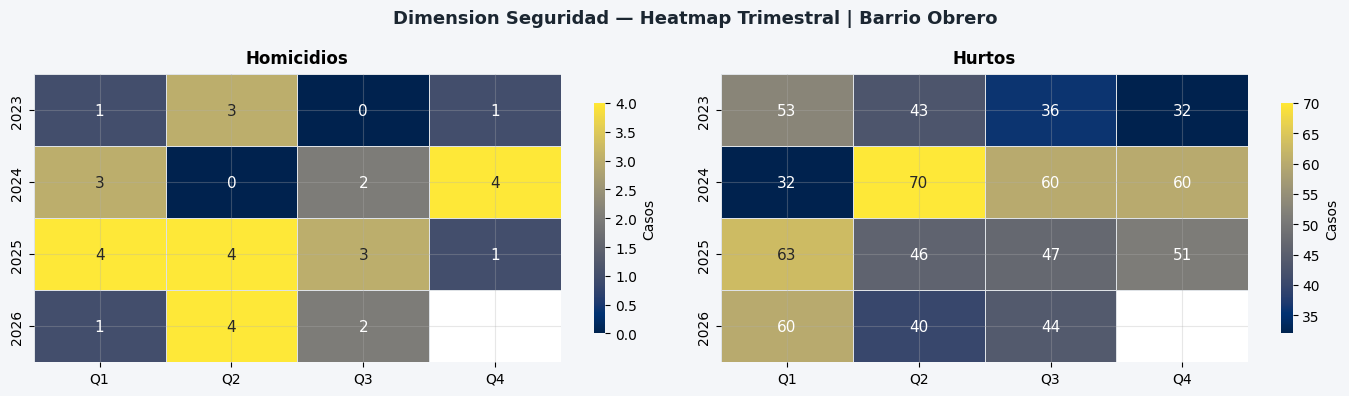

In [129]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), facecolor=BG)
fig.suptitle("Dimension Seguridad — Heatmap Trimestral | Barrio Obrero",
             fontsize=13, fontweight="bold", color="#1B2631")
for ax, col, titulo_h in [
    (axes[0], "homicidios", "Homicidios"),
    (axes[1], "hurtos",     "Hurtos"),
    ]:
    pivot = corr_trim.pivot(index="año", columns="trimestre", values=col)
    pivot.columns = ["Q1","Q2","Q3","Q4"]
    # Celda vacía donde no hay dato (NaN) en vez de forzar "0"; fmt=".0f" falla con NaN.
    _annot = pivot.apply(lambda c: c.map(lambda v: "" if pd.isna(v) else f"{v:.0f}"))
    sns.heatmap(pivot, annot=_annot, fmt="", cmap="cividis",
        linewidths=0.5, linecolor="#DEE2E6", ax=ax, annot_kws={"size":11},
        cbar_kws={"label":"Casos","shrink":0.8})
    ax.set_title(titulo_h, fontweight="bold", pad=8)
    ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout()
plt.savefig("itt_obrero_heatmap_seg.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


Conteo SPA por año y trimestre (base + extension 2026):
        Q1    Q2    Q3    Q4
año                         
2023  25.0   6.0  12.0  10.0
2024   3.0   7.0  14.0   4.0
2025  27.0  43.0  32.0  36.0
2026  12.0  12.0  25.0   NaN

Total SPA: 268 eventos  |  2023=53  |  2024=28  |  2025=138  |  2026=49


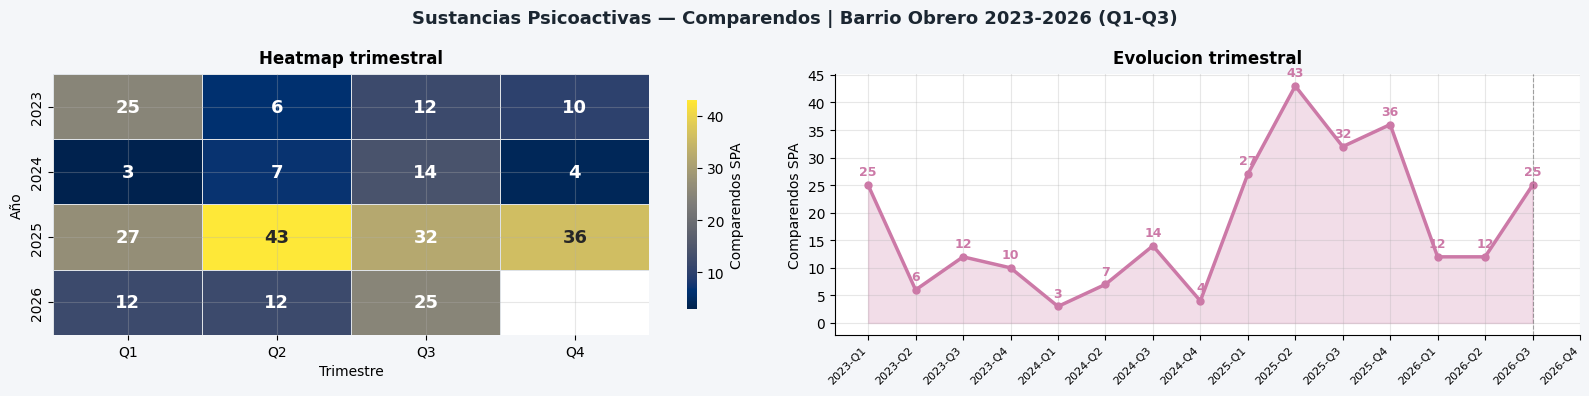


Sitios de ocurrencia:
sitio_hech
SITIOS PÚBLICOS O ABIERTOS AL PÚBLICO    230
MEDIO DE TRANSPORTE                        1


In [130]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# SPA (Sustancias Psicoactivas): comparendos del Código de Policía por consumo/porte de
# drogas en espacio público. Se integra LINEA BASE (hasta Q1 2026) + EXTENSION 2026
# (Q2-Q3) usando la misma funcion construir() de la Celda 6, con parser por formato.
df_spa_all = construir([
    dict(raw=raw_comp,     col_fecha="fecha_hech",  formato_fecha=None,
         filtro="SUSTANCIAS PSICOACTIVAS", filtro_col="agrupado",
         barrio_col="nom_barrio", barrio_val="OBRERO"),
    dict(raw=raw_comp_ext, col_fecha="fecha_hecho", formato_fecha="%Y-%m-%d",
         filtro="SUSTANCIAS PSICOACTIVAS", filtro_col="agrupado",
         barrio_col="nom_barrio", barrio_val="Barrio Obrero"),
])
ANIOS_SPA = [2023, 2024, 2025, 2026]
pivot_spa = (
    df_spa_all.groupby(['año','trimestre']).size()
    .unstack(fill_value=0)
    .reindex(index=ANIOS_SPA, fill_value=0)
    .reindex(columns=[1,2,3,4], fill_value=0)
    .astype(float)
)
pivot_spa.columns = ['Q1','Q2','Q3','Q4']
# 2026: Q1-Q3 tienen dato real (12 / 12 / 25). Solo Q4 queda sin fuente -> NaN.
pivot_spa.loc[2026, ['Q4']] = np.nan
print('Conteo SPA por año y trimestre (base + extension 2026):')
print(pivot_spa.to_string())
totales = {a: pivot_spa.loc[a].sum() for a in ANIOS_SPA}
print(f'\nTotal SPA: {int(df_spa_all.shape[0])} eventos  |  ' +
      '  |  '.join(f'{a}={int(totales[a]) if not pd.isna(totales[a]) else "?"}' for a in ANIOS_SPA))
fig, axes = plt.subplots(1, 2, figsize=(16, 4), facecolor=BG)
fig.suptitle('Sustancias Psicoactivas — Comparendos | Barrio Obrero 2023-2026 (Q1-Q3)',
             fontsize=13, fontweight='bold', color='#1B2631')
# Heatmap
mask_nan = pivot_spa.isna()
_annot_spa = pivot_spa.apply(lambda c: c.map(lambda v: '' if pd.isna(v) else f'{v:.0f}'))
sns.heatmap(pivot_spa, annot=_annot_spa, fmt='', cmap='cividis',
    linewidths=0.5, linecolor='#DEE2E6', ax=axes[0],
    annot_kws={'size': 13, 'weight': 'bold'},
    cbar_kws={'label': 'Comparendos SPA', 'shrink': 0.8},
    mask=mask_nan)
axes[0].set_title('Heatmap trimestral', fontweight='bold', pad=8)
axes[0].set_xlabel('Trimestre'); axes[0].set_ylabel('Año')
# Linea trimestral
periodos_spa = [f'{a}-Q{t}' for a in ANIOS_SPA for t in [1,2,3,4]]
x_spa = list(range(len(periodos_spa)))
vals_spa = [pivot_spa.loc[a, f'Q{t}'] for a in ANIOS_SPA for t in [1,2,3,4]]
vals_spa = [v if not pd.isna(v) else np.nan for v in vals_spa]
axes[1].fill_between(x_spa, vals_spa, alpha=0.25, color=OKI_MORADO)
axes[1].plot(x_spa, vals_spa, color=OKI_MORADO, linewidth=2.5, marker='o', markersize=5)
for i, v in enumerate(vals_spa):
    if pd.notna(v) and v > 0:
        axes[1].annotate(str(int(v)), (i, v),
            textcoords='offset points', xytext=(0, 7),
            ha='center', fontsize=9, fontweight='bold', color=OKI_MORADO)
ultimo_spa = max(i for i, v in enumerate(vals_spa) if pd.notna(v))
axes[1].axvline(ultimo_spa, color=OKI_GRIS, linewidth=0.8, linestyle='--', alpha=0.4)
axes[1].set_xticks(x_spa)
axes[1].set_xticklabels(periodos_spa, rotation=45, ha='right', fontsize=8)
axes[1].set_title('Evolucion trimestral', fontweight='bold', pad=8)
axes[1].set_ylabel('Comparendos SPA')
axes[1].yaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()
# Detalle: sitios donde ocurren (toda la serie)
print('\nSitios de ocurrencia:')
if 'sitio_hech' in df_spa_all.columns:
    print(df_spa_all['sitio_hech'].value_counts().head(10).to_string())


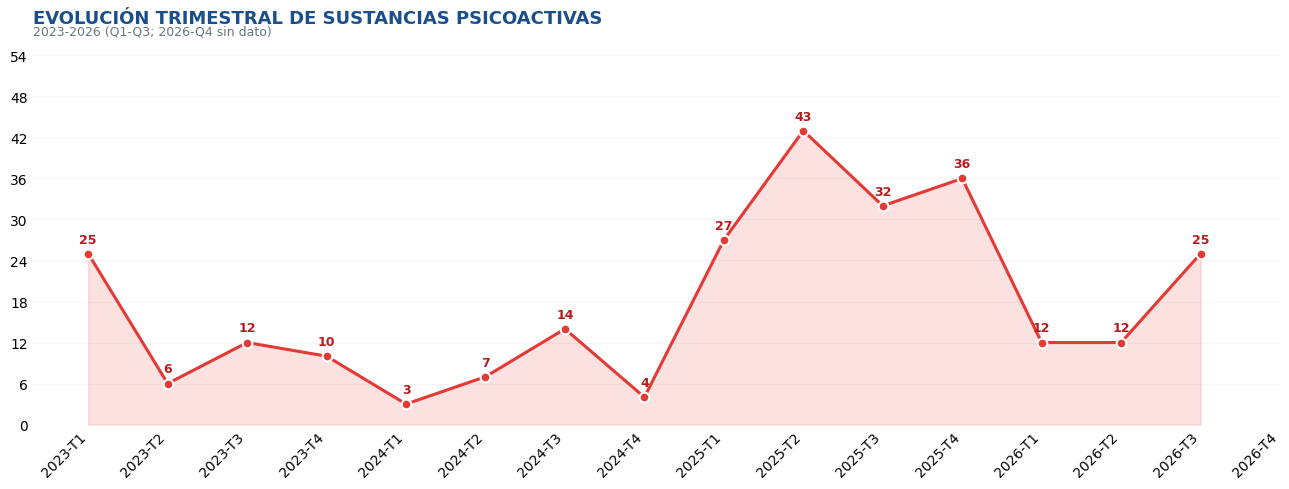

SPA 2026 (Q1-Q3): 49 comparendos  |  Q1=12  Q2=12  Q3=25  Q4=


In [131]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
import numpy as np
# Serie trimestral SPA integrando LINEA BASE + EXTENSION 2026 (Q2-Q3).
# Mismo criterio que el ITT: agrupado == 'SUSTANCIAS PSICOACTIVAS'.
df_spa_ev = construir([
    dict(raw=raw_comp,     col_fecha="fecha_hech",  formato_fecha=None,
         filtro="SUSTANCIAS PSICOACTIVAS", filtro_col="agrupado",
         barrio_col="nom_barrio", barrio_val="OBRERO"),
    dict(raw=raw_comp_ext, col_fecha="fecha_hecho", formato_fecha="%Y-%m-%d",
         filtro="SUSTANCIAS PSICOACTIVAS", filtro_col="agrupado",
         barrio_col="nom_barrio", barrio_val="Barrio Obrero"),
])
ANIOS_SPA = [2023, 2024, 2025, 2026]
idx = pd.MultiIndex.from_product([ANIOS_SPA, [1,2,3,4]], names=['año','trimestre'])
serie = df_spa_ev.groupby(['año','trimestre']).size().reindex(idx, fill_value=0).reset_index()
serie.columns = ['año','trimestre','casos']
serie['casos'] = serie['casos'].astype(float)
# 2026 Q4 sin fuente -> hueco (NaN), no cero. Q1-Q3 son dato real.
serie.loc[(serie['año']==2026) & (serie['trimestre']==4), 'casos'] = np.nan
serie['periodo'] = serie['año'].astype(str) + '-T' + serie['trimestre'].astype(str)
x = range(len(serie))
y = serie['casos'].values
labels = serie['periodo'].values
fig, ax = plt.subplots(figsize=(13, 5), facecolor='white')
ax.set_facecolor('white')
# Area + linea (los NaN quedan como hueco)
ax.fill_between(x, y, alpha=0.15, color='#E53935')
ax.plot(x, y, color='#E53935', linewidth=2.2, marker='o',
        markersize=7, markerfacecolor='#E53935', markeredgecolor='white', markeredgewidth=1.5)
# Etiqueta de valor sobre cada punto con dato
for xi, yi in zip(x, y):
    if pd.notna(yi):
        ax.annotate(f'{int(yi)}', (xi, yi), textcoords='offset points',
                    xytext=(0, 8), ha='center', fontsize=9, fontweight='bold', color='#B71C1C')
# Grilla horizontal suave
ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.grid(axis='y', color='#E0E0E0', linewidth=0.8, linestyle='-')
ax.grid(axis='x', visible=False)
ax.set_axisbelow(True)
# Ejes
ax.set_xticks(list(x))
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=10)
_ymax = np.nanmax(y) if np.any(pd.notna(y)) else 5
ax.set_ylim(0, _ymax * 1.3 if _ymax > 0 else 5)
ax.tick_params(axis='y', labelsize=10)
for spine in ['top','right','left','bottom']:
    ax.spines[spine].set_visible(False)
ax.tick_params(axis='both', length=0)
# Titulo estilo referencia
ax.set_title('EVOLUCIÓN TRIMESTRAL DE SUSTANCIAS PSICOACTIVAS',
             loc='left', fontsize=13, fontweight='bold', color='#1B4F8A', pad=14)
ax.text(0, 1.02, '2023-2026 (Q1-Q3; 2026-Q4 sin dato)', transform=ax.transAxes,
        fontsize=9, color='#6C757D')
plt.tight_layout()
plt.show()
_tot26 = int(np.nansum(serie.loc[serie['año']==2026, 'casos']))
print(f'SPA 2026 (Q1-Q3): {_tot26} comparendos  |  ' +
      '  '.join(f"Q{int(r.trimestre)}={'' if pd.isna(r.casos) else int(r.casos)}"
               for r in serie[serie['año']==2026].itertuples()))


## Celda 12 — Evolucion trimestral: Seguridad


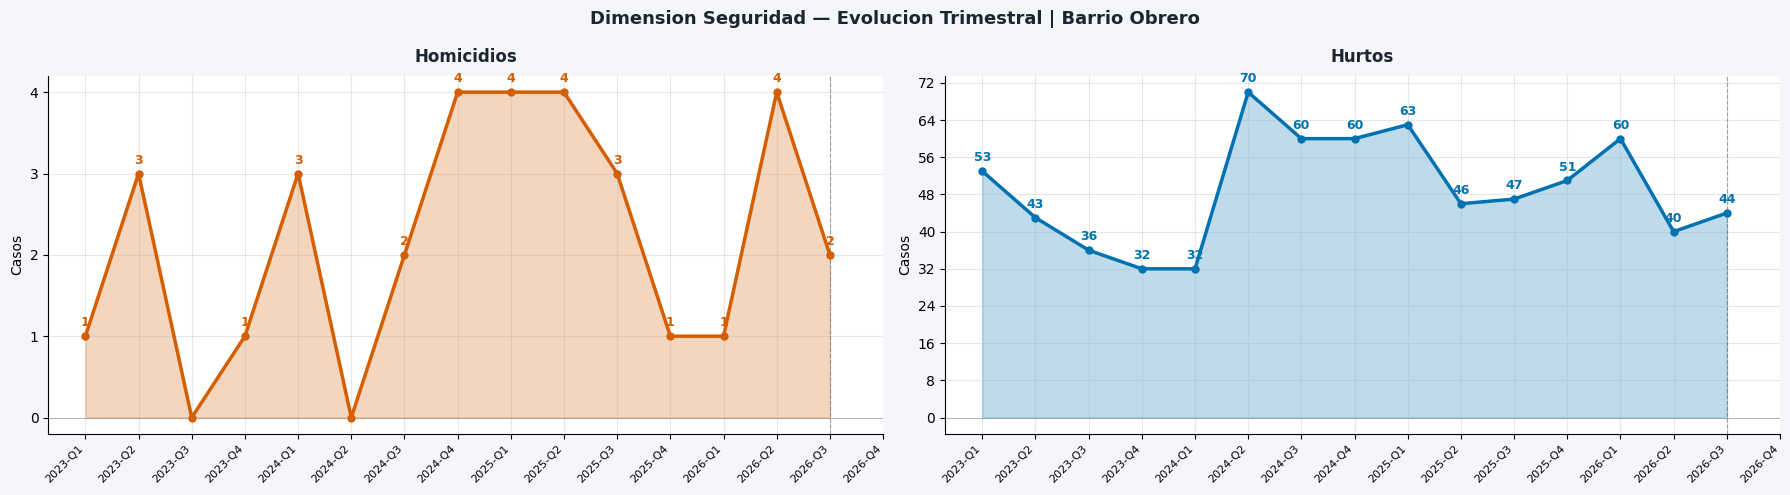

In [132]:
# Funcion reutilizable: linea + area rellena (NaN = hueco = sin dato)
periodos = corr_trim["periodo"].values
x = list(range(len(periodos)))

def plot_linefill(ax, col, titulo, color):
    vals = corr_trim[col].values.astype(float)
    valid = ~pd.isna(vals)
    ax.fill_between(x, np.where(valid, vals, np.nan), alpha=0.25, color=color)
    ax.plot(x, np.where(valid, vals, np.nan), color=color,
            linewidth=2.5, marker="o", markersize=5, zorder=3)
    for i, v in enumerate(vals):
        if pd.notna(v) and v > 0:
            ax.annotate(str(int(v)), (i, v),
                textcoords="offset points", xytext=(0, 7),
                ha="center", fontsize=9, fontweight="bold", color=color)
    ultimo_valido = max(i for i, v in enumerate(vals) if pd.notna(v))
    ax.axvline(ultimo_valido, color=OKI_GRIS, linewidth=0.8,
               linestyle="--", alpha=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels(periodos, rotation=45, ha="right", fontsize=8)
    ax.set_title(titulo, fontweight="bold", pad=10, color="#1B2631")
    ax.set_ylabel("Casos")
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.axhline(0, color=OKI_GRIS, linewidth=0.5, alpha=0.4)

fig, axes = plt.subplots(1, 2, figsize=(18, 5), facecolor=BG)
fig.suptitle("Dimension Seguridad — Evolucion Trimestral | Barrio Obrero",
             fontsize=13, fontweight="bold", color="#1B2631")
plot_linefill(axes[0], "homicidios", "Homicidios",  OKI_BERMELL)
plot_linefill(axes[1], "hurtos",     "Hurtos",       OKI_AZUL)
plt.tight_layout()
plt.savefig("itt_obrero_seg_trim.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()

## 2. Dimensión Cohesión Social — Peso: 9%

Indicadores: **VIF (Violencia Intrafamiliar)** · **Riñas / Conflictividad** · **SPA (Sustancias Psicoactivas)**
Fuente: DATIC 2023-2026 T1.
`score_cohesion = (score_vif + score_rinas + score_spa) / 3`
REF_VULNERABILIDAD (Sub PyE 2025) es dato de contexto — no entra al score.


## Celda 11 — Heatmap: Dimension Cohesion Social


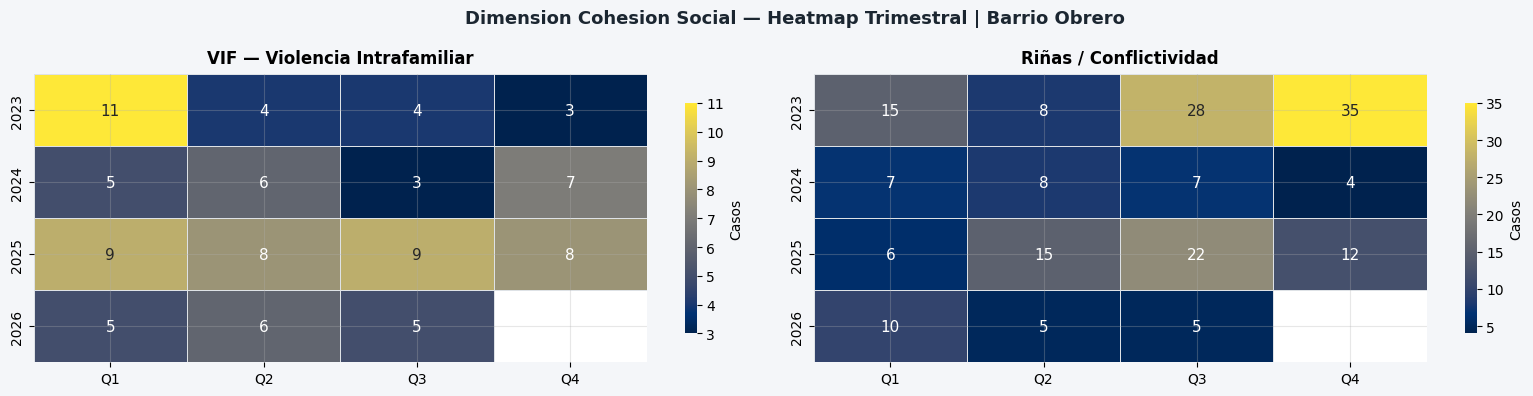

In [133]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4), facecolor=BG)
fig.suptitle("Dimension Cohesion Social — Heatmap Trimestral | Barrio Obrero",
             fontsize=13, fontweight="bold", color="#1B2631")
for ax, col, titulo_h in [
    (axes[0], "vif",   "VIF — Violencia Intrafamiliar"),
    (axes[1], "rinas", "Riñas / Conflictividad")]:
    pivot = corr_trim.pivot(index="año", columns="trimestre", values=col)
    pivot.columns = ["Q1","Q2","Q3","Q4"]
    # Celda vacía donde no hay dato (NaN) en vez de forzar "0"; fmt=".0f" falla con NaN.
    _annot = pivot.apply(lambda c: c.map(lambda v: "" if pd.isna(v) else f"{v:.0f}"))
    sns.heatmap(pivot, annot=_annot, fmt="", cmap="cividis",
        linewidths=0.5, linecolor="#DEE2E6", ax=ax, annot_kws={"size":11},
        cbar_kws={"label":"Casos","shrink":0.8})
    ax.set_title(titulo_h, fontweight="bold", pad=8)
    ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout()
plt.savefig("itt_obrero_heatmap_coh.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()

## Celda 14 — Evolucion trimestral: Cohesion Social


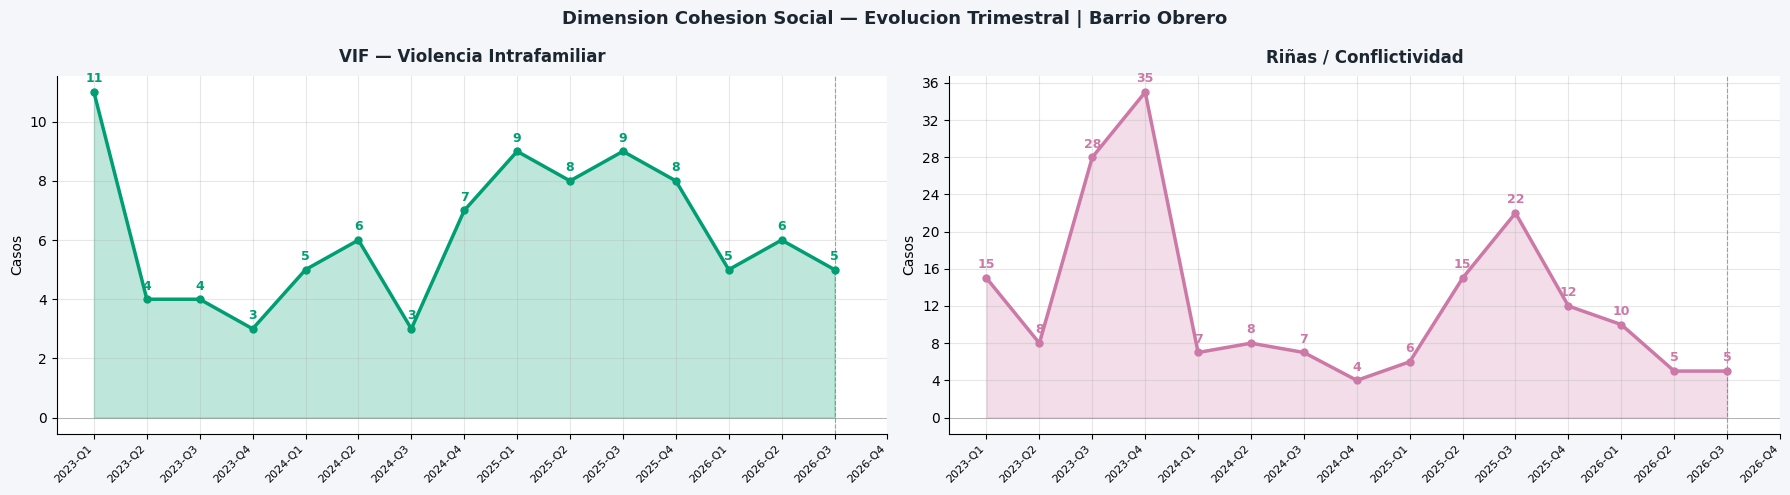

In [134]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5), facecolor=BG)
fig.suptitle("Dimension Cohesion Social — Evolucion Trimestral | Barrio Obrero",
             fontsize=13, fontweight="bold", color="#1B2631")
plot_linefill(axes[0], "vif",   "VIF — Violencia Intrafamiliar", OKI_VERDE)
plot_linefill(axes[1], "rinas", "Riñas / Conflictividad",        OKI_MORADO)
plt.tight_layout()
plt.savefig("itt_obrero_coh_trim.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()

── Vulnerabilidad activa | Barrio Obrero (Sub PyE 2025) ──
  Personas : 73  |  Tasa: 54.1/1.000 hab  |  Score: 45.9


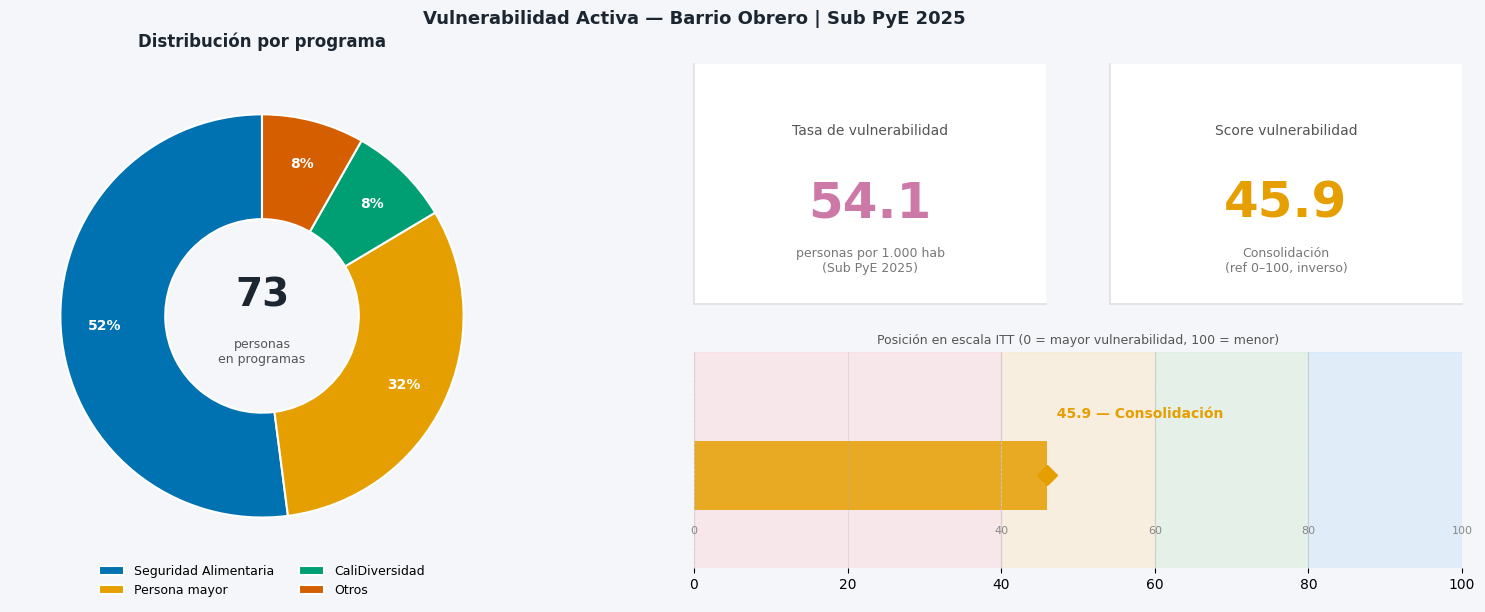

In [135]:
# ── Vulnerabilidad activa: Sub PyE 2025- ─────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

PATH_SUBPYE = str(REPO / "data" / "referencia" / "bienestar" /
                  "Caracterización Personas Sub PyE (2025).xlsx")
COL_BARRIO = "[Barrio de residencia] ¿En cuál barrio reside?"
COL_PROG   = "¿En cuál programa está siendo atendida la persona?"

POB_OBRERO   = 1349
VULN_REF_MIN = 0
VULN_REF_MAX = 100

df_sub    = pd.read_excel(PATH_SUBPYE)
mask_ob   = df_sub[COL_BARRIO].astype(str).str.upper().str.strip().str.contains("OBRERO", na=False)
df_ob     = df_sub[mask_ob].copy()

n_personas = len(df_ob)
tasa_vuln  = n_personas / POB_OBRERO * 1000
raw        = np.clip((tasa_vuln - VULN_REF_MIN) / (VULN_REF_MAX - VULN_REF_MIN) * 100, 0, 100)
score_vuln = round(100 - raw, 1)
REF_VULNERABILIDAD = score_vuln

print("── Vulnerabilidad activa | Barrio Obrero (Sub PyE 2025) ──")
print(f"  Personas : {n_personas}  |  Tasa: {tasa_vuln:.1f}/1.000 hab  |  Score: {score_vuln}")

# ── Preparar datos donut ──────────────────────────────────────────────────────
progs = df_ob[COL_PROG].value_counts()
# Agrupar slices < 5% en "Otros"
total_p  = progs.sum()
mask_peq = progs / total_p < 0.05
otros_n  = progs[mask_peq].sum()
progs_clean = progs[~mask_peq].copy()
if otros_n > 0:
    progs_clean["Otros"] = otros_n

colores_donut = [OKI_AZUL, OKI_NARANJA, OKI_VERDE, OKI_BERMELL, OKI_MORADO][:len(progs_clean)]

# ── Layout: 1 donut + 2 cards ─────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 6), facecolor=BG)
fig.suptitle("Vulnerabilidad Activa — Barrio Obrero | Sub PyE 2025",
             fontsize=13, fontweight="bold", color="#1B2631", y=1.01)

ax_donut = fig.add_axes([0.02, 0.08, 0.42, 0.84])   # izquierda
ax_card1 = fig.add_axes([0.50, 0.52, 0.22, 0.40])   # card superior
ax_card2 = fig.add_axes([0.76, 0.52, 0.22, 0.40])   # card superior derecha
ax_bar   = fig.add_axes([0.50, 0.08, 0.48, 0.36])   # barra inferior

# ── Donut ────────────────────────────────────────────────────────────────────
wedges, texts, autotexts = ax_donut.pie(
    progs_clean.values,
    labels=None,
    autopct="%1.0f%%",
    colors=colores_donut,
    startangle=90,
    pctdistance=0.78,
    wedgeprops=dict(width=0.52, edgecolor="white", linewidth=1.5)
)
for at in autotexts:
    at.set_fontsize(10); at.set_fontweight("bold"); at.set_color("white")
ax_donut.legend(
    wedges, progs_clean.index,
    loc="lower center", bbox_to_anchor=(0.5, -0.08),
    ncol=2, fontsize=9, frameon=False
)
ax_donut.text(0, 0.1, str(n_personas), ha="center", va="center",
              fontsize=28, fontweight="bold", color="#1B2631")
ax_donut.text(0, -0.18, "personas\nen programas", ha="center", va="center",
              fontsize=9, color="#555555")
ax_donut.set_title("Distribución por programa", fontweight="bold",
                   color="#1B2631", pad=12)

# ── Card 1: Tasa por 1.000 hab ───────────────────────────────────────────────
for ax_c in [ax_card1, ax_card2]:
    ax_c.set_facecolor("white")
    ax_c.set_xticks([]); ax_c.set_yticks([])
    for spine in ax_c.spines.values():
        spine.set_edgecolor("#E0E0E0"); spine.set_linewidth(1.2)

ax_card1.text(0.5, 0.72, "Tasa de vulnerabilidad",
              ha="center", va="center", fontsize=10, color="#555555",
              transform=ax_card1.transAxes)
ax_card1.text(0.5, 0.42, f"{tasa_vuln:.1f}",
              ha="center", va="center", fontsize=36, fontweight="bold",
              color=OKI_MORADO, transform=ax_card1.transAxes)
ax_card1.text(0.5, 0.18, "personas por 1.000 hab\n(Sub PyE 2025)",
              ha="center", va="center", fontsize=9, color="#777777",
              transform=ax_card1.transAxes)

# ── Card 2: Score cohesión ────────────────────────────────────────────────────
nivel_color = (OKI_BERMELL if score_vuln < 40 else
               OKI_NARANJA if score_vuln < 60 else
               OKI_VERDE   if score_vuln < 80 else OKI_AZUL)
nivel_lbl   = ("Activación"    if score_vuln < 40 else
               "Consolidación" if score_vuln < 60 else
               "Transformación" if score_vuln < 80 else "Escala")

ax_card2.text(0.5, 0.72, "Score vulnerabilidad",
              ha="center", va="center", fontsize=10, color="#555555",
              transform=ax_card2.transAxes)
ax_card2.text(0.5, 0.42, f"{score_vuln}",
              ha="center", va="center", fontsize=36, fontweight="bold",
              color=nivel_color, transform=ax_card2.transAxes)
ax_card2.text(0.5, 0.18, f"{nivel_lbl}\n(ref 0–100, inverso)",
              ha="center", va="center", fontsize=9, color="#777777",
              transform=ax_card2.transAxes)

# ── Barra de contexto ─────────────────────────────────────────────────────────
ax_bar.set_facecolor(BG)
for spine in ax_bar.spines.values(): spine.set_visible(False)
niveles_bg = [(0,40,"#FFCDD2"),(40,60,"#FFE0B2"),(60,80,"#C8E6C9"),(80,100,"#BBDEFB")]
for x0, x1, c in niveles_bg:
    ax_bar.axvspan(x0, x1, alpha=0.35, color=c)
ax_bar.barh([0], [score_vuln], color=nivel_color, alpha=0.85, height=0.45)
ax_bar.plot(score_vuln, 0, marker="D", ms=10, color=nivel_color, zorder=5)
ax_bar.text(score_vuln, 0.35, f"  {score_vuln} — {nivel_lbl}",
            va="bottom", fontsize=10, fontweight="bold", color=nivel_color)
for x, lbl in [(0,"0"),(40,"40"),(60,"60"),(80,"80"),(100,"100")]:
    ax_bar.axvline(x, color="#CCCCCC", linewidth=0.6, linestyle="--")
    ax_bar.text(x, -0.38, lbl, ha="center", fontsize=8, color="#888888")
ax_bar.set_xlim(0, 100); ax_bar.set_ylim(-0.6, 0.8)
ax_bar.set_yticks([])
ax_bar.set_title("Posición en escala ITT (0 = mayor vulnerabilidad, 100 = menor)",
                 fontsize=9, color="#555555", pad=6)

plt.savefig("itt_obrero_vulnerabilidad.png", dpi=150,
            bbox_inches="tight", facecolor=BG)
plt.show()


## 3. Dimensión Movilidad — Peso: 22%

Indicadores: **Siniestralidad total** · **Accidentes con lesionados** · **Accidentes mortales**
Fuente: Siniestros viales Barrio Obrero 2023-2026 T2. 2026-Q3/Q4 sin dato.
`score_movilidad = (score_siniestralidad + score_lesionados + score_mortales) / 3`


## Celda 10 — Heatmap: Dimension Movilidad


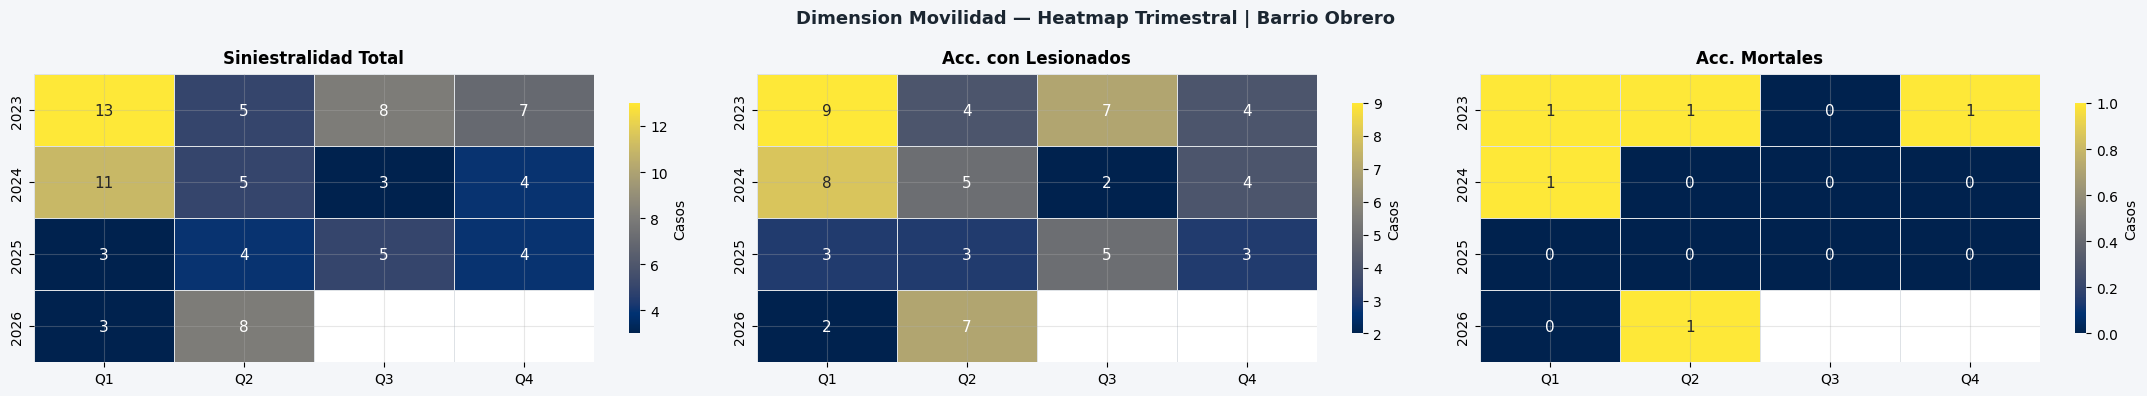

In [136]:
fig, axes = plt.subplots(1, 3, figsize=(22, 4), facecolor=BG)
fig.suptitle("Dimension Movilidad — Heatmap Trimestral | Barrio Obrero",
             fontsize=13, fontweight="bold", color="#1B2631")

# Movilidad tiene dato real hasta 2026-Q2 (archivo siniestros abril-junio: 8 eventos).
# Q3 y Q4 de 2026 = sin fuente -> NaN. No modifica corr_trim global.
corr_trim_q1 = corr_trim.copy()
mask_2026_sin_fuente = (corr_trim_q1["año"] == 2026) & (corr_trim_q1["trimestre"] > 2)
corr_trim_q1.loc[mask_2026_sin_fuente, ["siniestralidad", "lesionados", "mortales"]] = np.nan

for ax, col, titulo_h in [
    (axes[0], "siniestralidad", "Siniestralidad Total"),
    (axes[1], "lesionados",     "Acc. con Lesionados"),
    (axes[2], "mortales",       "Acc. Mortales")]:
    pivot = corr_trim_q1.pivot(index="año", columns="trimestre", values=col)
    pivot.columns = ["Q1","Q2","Q3","Q4"]
    # Celda vacía donde no hay dato (NaN) en vez de forzar "0"; fmt=".0f" falla con NaN.
    _annot = pivot.apply(lambda c: c.map(lambda v: "" if pd.isna(v) else f"{v:.0f}"))
    sns.heatmap(pivot, annot=_annot, fmt="", cmap="cividis",
        linewidths=0.5, linecolor="#DEE2E6", ax=ax, annot_kws={"size":11},
        cbar_kws={"label":"Casos","shrink":0.8})
    ax.set_title(titulo_h, fontweight="bold", pad=8)
    ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout()
plt.savefig("itt_obrero_heatmap_mov.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


## Celda 13 — Evolucion trimestral: Movilidad


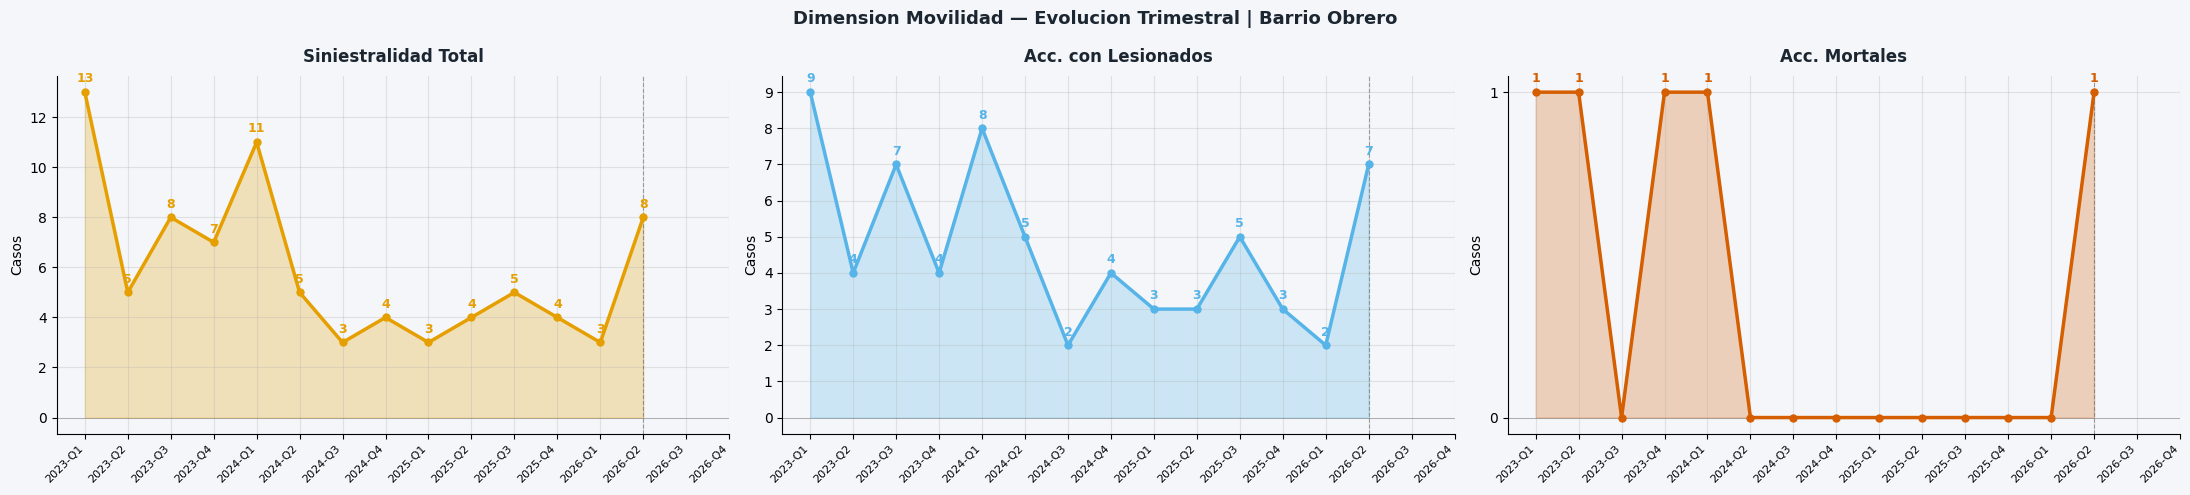

In [137]:
# ── Dimension Movilidad — Evolucion Trimestral | Barrio Obrero ────────────────
# COBERTURA 2026 de siniestros: Q1 (historico ene-mar) + Q2 (archivo abril-junio, 8
# eventos). Q3 (jul-sep) y Q4 (oct-dic) = SIN DATO (NaN): el archivo de SIMUR del 3er
# trimestre fue solicitado pero AUN NO HA LLEGADO (a la fecha de esta corrida). Cuando
# llegue, se integra con el mismo flujo (spatial join + dedup por huella) y Q3 se llena.
# No se rellena con 0 ni se estima: regla de datos faltantes = NaN, no se inventa.
corr_trim_q1 = corr_trim.copy()
mask_2026_sin_fuente = (corr_trim_q1["año"] == 2026) & (corr_trim_q1["trimestre"] > 2)
corr_trim_q1.loc[mask_2026_sin_fuente, ["siniestralidad", "lesionados", "mortales"]] = np.nan

_periodos = corr_trim_q1["periodo"].tolist()
_x        = np.arange(len(_periodos))

fig, axes = plt.subplots(1, 3, figsize=(22, 5), facecolor=BG)
fig.suptitle("Dimension Movilidad — Evolucion Trimestral | Barrio Obrero",
             fontsize=13, fontweight="bold", color="#1B2631")

cfg = [
    (axes[0], "siniestralidad", "Siniestralidad Total", OKI_NARANJA),
    (axes[1], "lesionados",     "Acc. con Lesionados",  OKI_AZUL_C),
    (axes[2], "mortales",       "Acc. Mortales",        OKI_BERMELL),
]

for ax, col, titulo, color in cfg:
    vals  = corr_trim_q1[col].values.astype(float)
    valid = ~pd.isna(vals)

    ax.fill_between(_x, np.where(valid, vals, np.nan), alpha=0.25, color=color)
    ax.plot(_x, np.where(valid, vals, np.nan), color=color,
            linewidth=2.5, marker="o", markersize=5, zorder=3)

    for i, v in enumerate(vals):
        if pd.notna(v) and v > 0:
            ax.annotate(str(int(v)), (i, v),
                        textcoords="offset points", xytext=(0, 7),
                        ha="center", fontsize=9, fontweight="bold", color=color)

    ultimo = max(i for i, v in enumerate(vals) if pd.notna(v))
    ax.axvline(ultimo, color=OKI_GRIS, linewidth=0.8, linestyle="--", alpha=0.4)
    ax.set_xticks(_x)
    ax.set_xticklabels(_periodos, rotation=45, ha="right", fontsize=8)
    ax.set_title(titulo, fontweight="bold", pad=10, color="#1B2631")
    ax.set_ylabel("Casos")
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.axhline(0, color=OKI_GRIS, linewidth=0.5, alpha=0.4)
    ax.set_facecolor(BG)

plt.tight_layout()
plt.savefig("itt_obrero_mov_trim.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


## 4. Dimensión Entorno Urbano — Peso: 17%

Indicadores: **NDVI / Área Verde Neta** · **Árboles DAGMA** · **Déficit Habitacional Cualitativo**
Fuente: Rasters NDVI 2023-2026 (rasterio) + DAGMA árboles 2025 + DANE Déficit 2024.
Métrica anual — se extiende plana dentro de cada año en la serie trimestral.


## Celda 3B — Proxy de Entorno Urbano para Barrio Obrero

Esta celda recalcula `REF_ENTORNO_U` usando el Excel de `deficit habitacional` en `data/referencia/`.

- Base territorial: `Comuna 9`, usada como proxy para `Barrio Obrero`.
- Variable principal: `Deficit Cualitativo`.
- Variable de intensidad: `Deficit Cualitativo / Deficit Habitacional`.
- Regla de score: ambos componentes se normalizan a `0-100` con referencias fijas y luego se promedian.
- Si el Excel no aparece o no encuentra la Comuna 9, el notebook conserva el valor previo de `REF_ENTORNO_U`.


In [138]:
import os
import pandas as pd
import numpy as np
from pathlib import Path

# Proxy de Entorno Urbano para Barrio Obrero usando deficit habitacional (Comuna 9).
# Este bloque sustituye el referente fijo solo para esta corrida si encuentra el Excel.
# Si falla la lectura, se mantiene el valor previo heredado de Pulmon de Oriente.
REF_ENTORNO_U = globals().get('REF_ENTORNO_U', 39.2)
FUENTE_ENTORNO_U = globals().get('FUENTE_ENTORNO_U', 'Pulmon de Oriente (referente fijo)')
DETALLE_ENTORNO_U = globals().get('DETALLE_ENTORNO_U', f'Score fijo heredado={REF_ENTORNO_U:.1f}')

PATH_PROXY_ENTORNO = [
    Path('/content/itt_repos_cali/data/referencia/vivienda/BD_DEFICIT_HABITACIONAL_COM_CORREG_2024 (1).xlsx'),
    Path('data/referencia/vivienda/BD_DEFICIT_HABITACIONAL_COM_CORREG_2024 (1).xlsx'),
    Path('./data/referencia/vivienda/BD_DEFICIT_HABITACIONAL_COM_CORREG_2024 (1).xlsx'),
]

proxy_path = next((p for p in PATH_PROXY_ENTORNO if p.exists()), None)
if proxy_path is None:
    print('No se encontro el Excel de referencia. REF_ENTORNO_U conserva su valor actual:', REF_ENTORNO_U)
else:
    def score_ref_proxy(valor, ref_min, ref_max, inverso=True):
        if ref_max == ref_min:
            return 100.0
        raw = np.clip((valor - ref_min) / (ref_max - ref_min) * 100, 0, 100)
        return 100 - raw if inverso else raw

    df_proxy = pd.read_excel(proxy_path, sheet_name='Hoja1')
    df_proxy.columns = [str(c).strip() for c in df_proxy.columns]

    # Se toma la Comuna 9 como aproximacion territorial a Barrio Obrero.
    col_area = 'Comuna o Corregimiento'
    col_total = 'Déficit Habitacional'
    col_cual = 'Déficit Cualitativo'

    fila_c9 = df_proxy.loc[df_proxy[col_area].astype(str).str.strip() == '9']
    if fila_c9.empty:
        print('No se encontro la Comuna 9 en el Excel. REF_ENTORNO_U conserva su valor actual:', REF_ENTORNO_U)
    else:
        deficit_total = float(fila_c9.iloc[0][col_total])
        deficit_cual = float(fila_c9.iloc[0][col_cual])
        deficit_pct = (deficit_cual / deficit_total) * 100 if deficit_total else np.nan

        # Referencias fijas de Hoja1 (38 comunas/corregimientos), no min-max de la muestra local.
        REF_MIN_DEFICIT_CUAL = 86.0
        REF_MAX_DEFICIT_CUAL = 20179.0
        REF_MIN_DEFICIT_PCT = 69.8
        REF_MAX_DEFICIT_PCT = 96.6

        # Componente 1: volumen absoluto de deficit cualitativo.
        score_proxy_volumen = score_ref_proxy(deficit_cual, REF_MIN_DEFICIT_CUAL, REF_MAX_DEFICIT_CUAL, True)
        # Componente 2: intensidad relativa del deficit cualitativo dentro del deficit total.
        score_proxy_intensidad = score_ref_proxy(deficit_pct, REF_MIN_DEFICIT_PCT, REF_MAX_DEFICIT_PCT, True)

        # Proxy final de Entorno Urbano = promedio simple de ambos componentes.
        REF_ENTORNO_U = round((score_proxy_volumen + score_proxy_intensidad) / 2, 1)
        FUENTE_ENTORNO_U = 'Proxy por deficit habitacional (Comuna 9)'
        DETALLE_ENTORNO_U = (
            f'Deficit cualitativo={deficit_cual:,.0f}; '
            f'proporcion={deficit_pct:.1f}%; '
            f'score_volumen={score_proxy_volumen:.1f}; '
            f'score_intensidad={score_proxy_intensidad:.1f}; '
            f'promedio={REF_ENTORNO_U:.1f}'
        )

        print('Proxy Entorno Urbano activado para Barrio Obrero')
        print('Fuente:', proxy_path)
        print('Base territorial:', 'Comuna 9 (proxy para Barrio Obrero)')
        print(f'Deficit cualitativo: {deficit_cual:,.0f}')
        print(f'Deficit cualitativo / deficit habitacional: {deficit_pct:.1f}%')
        print(f'Score proxy volumen: {score_proxy_volumen:.1f}')
        print(f'Score proxy intensidad: {score_proxy_intensidad:.1f}')
        print(f'Nuevo REF_ENTORNO_U: {REF_ENTORNO_U:.1f}')


Proxy Entorno Urbano activado para Barrio Obrero
Fuente: /content/itt_repos_cali/data/referencia/vivienda/BD_DEFICIT_HABITACIONAL_COM_CORREG_2024 (1).xlsx
Base territorial: Comuna 9 (proxy para Barrio Obrero)
Deficit cualitativo: 3,156
Deficit cualitativo / deficit habitacional: 87.5%
Score proxy volumen: 84.7
Score proxy intensidad: 33.8
Nuevo REF_ENTORNO_U: 59.3


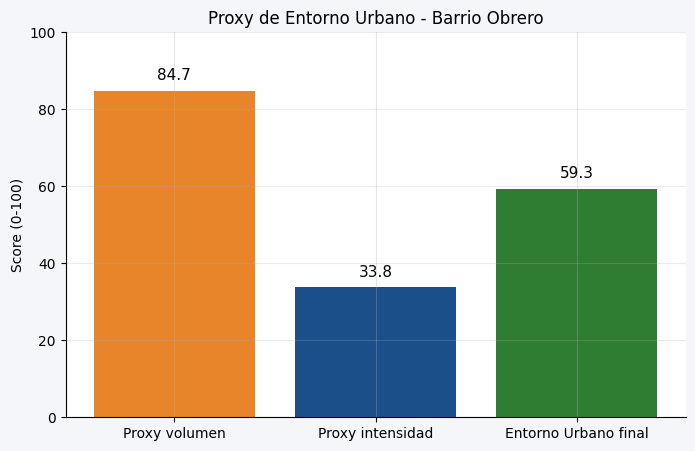

In [139]:
import matplotlib.pyplot as plt

labels = [
    'Proxy volumen',
    'Proxy intensidad',
    'Entorno Urbano final'
]
values = [
    score_proxy_volumen,
    score_proxy_intensidad,
    REF_ENTORNO_U
]
colors = ['#E8852A', '#1B4F8A', '#2E7D32']

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values, color=colors)

plt.ylim(0, 100)
plt.ylabel('Score (0-100)')
plt.title('Proxy de Entorno Urbano - Barrio Obrero')

for bar, val in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, val + 2, f'{val:.1f}',
             ha='center', va='bottom', fontsize=11)

plt.grid(axis='y', alpha=0.25)
plt.show()


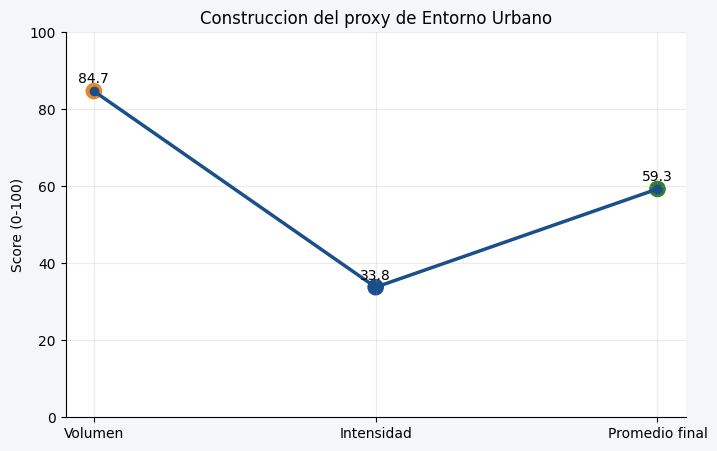

In [140]:
import matplotlib.pyplot as plt

x = ['Volumen', 'Intensidad', 'Promedio final']
y = [score_proxy_volumen, score_proxy_intensidad, REF_ENTORNO_U]

plt.figure(figsize=(8,5))
plt.plot(x, y, marker='o', linewidth=2.5, color='#1B4F8A')
plt.scatter(x, y, s=120, color=['#E8852A', '#1B4F8A', '#2E7D32'])

for xi, yi in zip(x, y):
    plt.text(xi, yi + 2, f'{yi:.1f}', ha='center')

plt.ylim(0, 100)
plt.ylabel('Score (0-100)')
plt.title('Construccion del proxy de Entorno Urbano')
plt.grid(alpha=0.25)
plt.show()


## Celda 3C — Heatmap de componentes del déficit cualitativo (2024)

Esta visualizacion muestra la composicion interna del `Deficit Cualitativo` usado como proxy de `Entorno Urbano`.

- Base territorial: `Comuna 9`, usada como proxy para `Barrio Obrero`.
- Periodo: `2024`.
- Lectura recomendada: colores mas intensos indican mayor peso dentro del deficit cualitativo total.
- Nota metodologica: es un corte anual 2024, no una serie mensual ni trimestral observada.


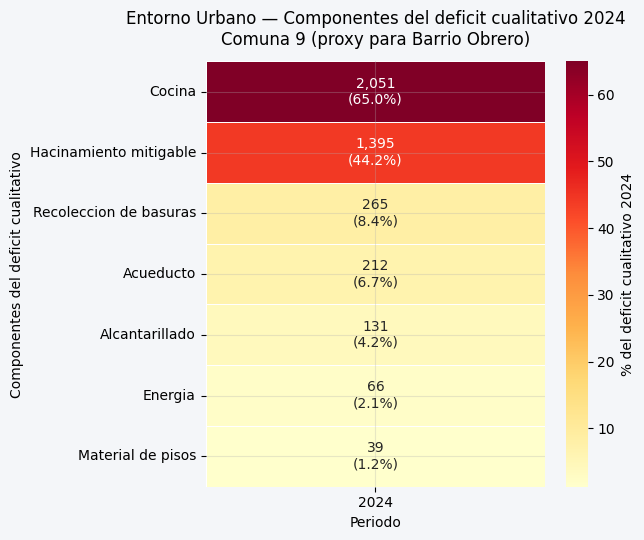

Composicion del deficit cualitativo 2024:
            componente  valor_2024  pct_deficit_cual
                Cocina      2051.0              65.0
Hacinamiento mitigable      1395.0              44.2
Recoleccion de basuras       265.0               8.4
             Acueducto       212.0               6.7
        Alcantarillado       131.0               4.2
               Energia        66.0               2.1
     Material de pisos        39.0               1.2


In [141]:
# Heatmap de componentes del deficit cualitativo 2024 para Comuna 9 / proxy de Barrio Obrero.
if 'fila_c9' not in globals() or fila_c9.empty:
    print('No hay fila de Comuna 9 cargada desde el Excel de referencia.')
else:
    cols_componentes = {
        'Hacinamiento mitigable': 'Déficit cualitativo Hacinamiento mitigable',
        'Material de pisos': 'Déficit cualitativo Material de pisos',
        'Cocina': 'Déficit cualitativo Cocina',
        'Acueducto': 'Déficit cualitativo Acueducto',
        'Alcantarillado': 'Déficit cualitativo Alcantarillado',
        'Energia': 'Déficit cualitativo Energia',
        'Recoleccion de basuras': 'Déficit cualitativo Recolección de basuras',
    }

    componentes_2024 = []
    for nombre, col in cols_componentes.items():
        valor = float(fila_c9.iloc[0][col])
        pct = (valor / deficit_cual * 100) if deficit_cual else 0.0
        componentes_2024.append({
            'componente': nombre,
            'valor_2024': valor,
            'pct_deficit_cual': pct,
            'etiqueta': f'{valor:,.0f}\n({pct:.1f}%)'
        })

    df_entorno_comp = pd.DataFrame(componentes_2024).sort_values('pct_deficit_cual', ascending=False)
    proxy_entorno_componentes_2024 = df_entorno_comp.copy()

    matriz = df_entorno_comp.set_index('componente')[['pct_deficit_cual']]
    matriz.columns = ['2024']
    anot = df_entorno_comp.set_index('componente')[['etiqueta']]
    anot.columns = ['2024']

    plt.figure(figsize=(6.5, 5.5))
    ax = sns.heatmap(
        matriz,
        annot=anot,
        fmt='',
        cmap='YlOrRd',
        linewidths=0.5,
        linecolor='white',
        cbar_kws={'label': '% del deficit cualitativo 2024'}
    )
    ax.set_title('Entorno Urbano — Componentes del deficit cualitativo 2024\nComuna 9 (proxy para Barrio Obrero)', pad=12)
    ax.set_xlabel('Periodo')
    ax.set_ylabel('Componentes del deficit cualitativo')
    plt.tight_layout()
    plt.show()

    print('Composicion del deficit cualitativo 2024:')
    print(df_entorno_comp[['componente', 'valor_2024', 'pct_deficit_cual']].round({'valor_2024': 0, 'pct_deficit_cual': 1}).to_string(index=False))


## Celda EU — Entorno Urbano

Calcula el score de **Entorno Urbano** desde dos indicadores con datos reales del polígono:

- **NDVI / Área verde** (rasters TIF 2023-2026): % del barrio con NDVI ≥ 0.20 → serie anual.
- **Árboles DAGMA**: 151 puntos → densidad árb/ha → score estático aplicado a todos los años.

Composite: 50% score área verde + 50% score árboles. Reemplaza `REF_ENTORNO_U = 39.2` en `base`.

In [142]:
# ── Celda EU-1: procesar rasters NDVI (rasterio) ─────────────────────────────
import subprocess, importlib.util
import numpy as np
from pathlib import Path

if importlib.util.find_spec('rasterio') is None:
    subprocess.run(['pip', 'install', 'rasterio', '-q'], check=False)
import rasterio

NDVI_DIR    = DATA_DIR / '5_Entorno_Urbano' / 'NDVI_Barrio_Obrero'
NDVI_UMBRAL = 0.20
ARBOLES_N   = len(raw_arb['features'])   # cargado en Celda 4

ndvi_stats = {}
AREA_HA    = None

for año in ANIOS:
    tif = NDVI_DIR / f'Barrio_Obrero_ndvi_{año}.tif'
    if not tif.exists():
        print(f'  {año}: raster no encontrado')
        ndvi_stats[año] = {'ndvi_mean': np.nan, 'verde_m2': np.nan, 'pct_verde': np.nan}
        continue
    with rasterio.open(tif) as src:
        data = src.read(1).astype(float)
        if src.nodata is not None:
            data[data == src.nodata] = np.nan
        # Pixel en m² (CRS geográfico, lat ~3.44°)
        px_lon_m = abs(src.transform.a) * 111320 * np.cos(np.radians(3.44))
        px_lat_m = abs(src.transform.e) * 110540
        px_area  = px_lon_m * px_lat_m
        total_px  = int(np.sum(~np.isnan(data)))
        verde_px  = int(np.sum(data >= NDVI_UMBRAL))
        ndvi_mean = round(float(np.nanmean(data)), 4)
        verde_m2  = round(verde_px * px_area)
        total_m2  = round(total_px * px_area)
        pct_verde = round(verde_px / total_px * 100, 1) if total_px > 0 else 0
        ndvi_stats[año] = {'ndvi_mean': ndvi_mean, 'verde_m2': verde_m2,
                           'pct_verde': pct_verde, 'total_m2': total_m2}
        if AREA_HA is None:
            AREA_HA = round(total_m2 / 10000, 2)
    print(f'{año}: NDVI_medio={ndvi_mean}  |  área_verde={verde_m2} m² ({pct_verde}%)')

dens_arboles_ha = round(ARBOLES_N / AREA_HA, 1) if AREA_HA else np.nan
print(f'\nÁrboles: {ARBOLES_N}  |  Área barrio: {AREA_HA} ha  |  Densidad: {dens_arboles_ha} árb/ha')


2023: NDVI_medio=0.0687  |  área_verde=5154 m² (6.4%)
2024: NDVI_medio=0.0809  |  área_verde=6938 m² (8.6%)
2025: NDVI_medio=0.0804  |  área_verde=6245 m² (7.8%)
2026: NDVI_medio=0.0688  |  área_verde=3469 m² (4.3%)

Árboles: 874  |  Área barrio: 8.03 ha  |  Densidad: 108.8 árb/ha


In [143]:
# ── Celda EU-2: scores EntornoU → actualizar base + recalcular ITT ───────────
REF_VERDE_MIN,   REF_VERDE_MAX   = 0, 30   # % área verde
REF_ARBOLES_MIN, REF_ARBOLES_MAX = 0, 50   # árboles/ha

score_arboles_fijo = round(score_ref(dens_arboles_ha,
                                     REF_ARBOLES_MIN, REF_ARBOLES_MAX, False), 1)
print(f'Score árboles (estático): {score_arboles_fijo}  ({dens_arboles_ha} árb/ha, ref 0-50)')

rows_eu = []
for año in ANIOS:
    st  = ndvi_stats.get(año, {})
    pct = st.get('pct_verde', np.nan)
    sc_verde = score_ref(pct, REF_VERDE_MIN, REF_VERDE_MAX, False) if not np.isnan(pct) else np.nan
    sc_eu    = round((sc_verde + score_arboles_fijo) / 2, 1) if not np.isnan(sc_verde) else score_arboles_fijo
    rows_eu.append(dict(
        año=año,
        ndvi_mean=st.get('ndvi_mean', np.nan),
        pct_verde=pct,
        verde_m2=st.get('verde_m2', np.nan),
        score_verde=sc_verde,
        score_arboles=score_arboles_fijo,
        score_entorno_u=sc_eu
    ))

df_eu = pd.DataFrame(rows_eu)

print()
print('── Entorno Urbano: indicadores y scores ─────────────────────────────────')
print(df_eu[['año','ndvi_mean','pct_verde','verde_m2','score_verde',
             'score_arboles','score_entorno_u']].to_string(index=False))
print()

# Actualizar base
for _, row in df_eu.iterrows():
    base.loc[base['año'] == int(row['año']), 'score_entorno_u'] = row['score_entorno_u']

# Recalcular ITT
base['score_des_social'] = base.apply(
    lambda r: np.nanmean([
        r.get('score_vif', np.nan),
        r.get('score_rinas', np.nan),
        r.get('score_spa', np.nan),
        r.get('score_matricula', np.nan),
        r.get('score_desercion', np.nan),
    ]),
    axis=1
)
# 2026 usa su PROPIO dato social (VIF/Riñas/SPA parciales reales); NO se copia 2025
# (eso inventaria data). El año queda marcado 'Parcial' en clasificar().
base['ITT'] = (
    PESOS['Seguridad'] * base['score_seguridad'] +
    PESOS['Movilidad'] * base['score_movilidad'] +
    PESOS['DesSocial'] * base['score_des_social'] +
    PESOS['EntornoU']  * base['score_entorno_u'] +
    PESOS['DesEco']    * base['score_des_eco']
)
base['nivel'] = base.apply(lambda r: clasificar(r['ITT'], r['año']), axis=1)

print('ITT actualizado — EntornoU real (NDVI + árboles):')
print(base[['año','score_entorno_u','ITT','nivel']].round(1).to_string(index=False))


Score árboles (estático): 100.0  (108.8 árb/ha, ref 0-50)

── Entorno Urbano: indicadores y scores ─────────────────────────────────
 año  ndvi_mean  pct_verde  verde_m2  score_verde  score_arboles  score_entorno_u
2023     0.0687        6.4      5154    21.333333          100.0             60.7
2024     0.0809        8.6      6938    28.666667          100.0             64.3
2025     0.0804        7.8      6245    26.000000          100.0             63.0
2026     0.0688        4.3      3469    14.333333          100.0             57.2

ITT actualizado — EntornoU real (NDVI + árboles):
 año  score_entorno_u  ITT                   nivel
2023             60.7 51.4           Consolidacion
2024             64.3 56.7           Consolidacion
2025             63.0 52.1           Consolidacion
2026             57.2 70.0 Parcial (no comparable)


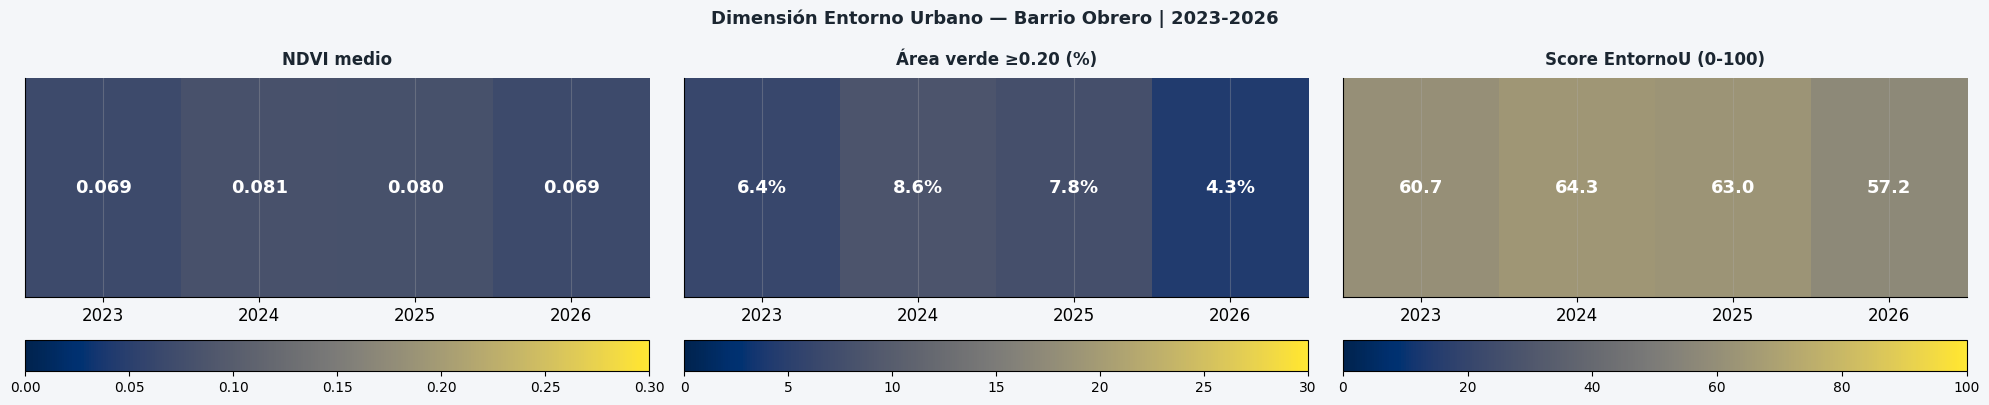

In [144]:
# ── Celda EU-3: heatmap Entorno Urbano ───────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 4), facecolor=BG)
fig.suptitle('Dimensión Entorno Urbano — Barrio Obrero | 2023-2026',
             fontsize=13, fontweight='bold', color='#1B2631')

df_e = df_eu.set_index('año').reindex(ANIOS)
configs_hm = [
    ('ndvi_mean',       'NDVI medio',            'cividis', 0,    0.30, ''),
    ('pct_verde',       'Área verde ≥0.20 (%)',  'cividis', 0,    30,   '%'),
    ('score_entorno_u', 'Score EntornoU (0-100)', 'cividis', 0,   100,  ''),
]
for ax, (col, titulo, cmap, vmin, vmax, sfx) in zip(axes, configs_hm):
    vals = df_e[col].values.astype(float).reshape(1, -1)
    im = ax.imshow(vals, cmap=cmap, aspect='auto', vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(ANIOS))); ax.set_xticklabels(ANIOS, fontsize=12)
    ax.set_yticks([])
    ax.set_title(titulo, fontweight='bold', pad=10, color='#1B2631')
    for j, v in enumerate(vals[0]):
        fmt = f'{v:.3f}' if col == 'ndvi_mean' else f'{v:.1f}{sfx}'
        txt = fmt if not np.isnan(v) else 'S/D'
        ax.text(j, 0, txt, ha='center', va='center',
                fontsize=13, fontweight='bold', color='white')
    plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.14)

plt.tight_layout()
plt.savefig('itt_obrero_entorno_heatmap.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


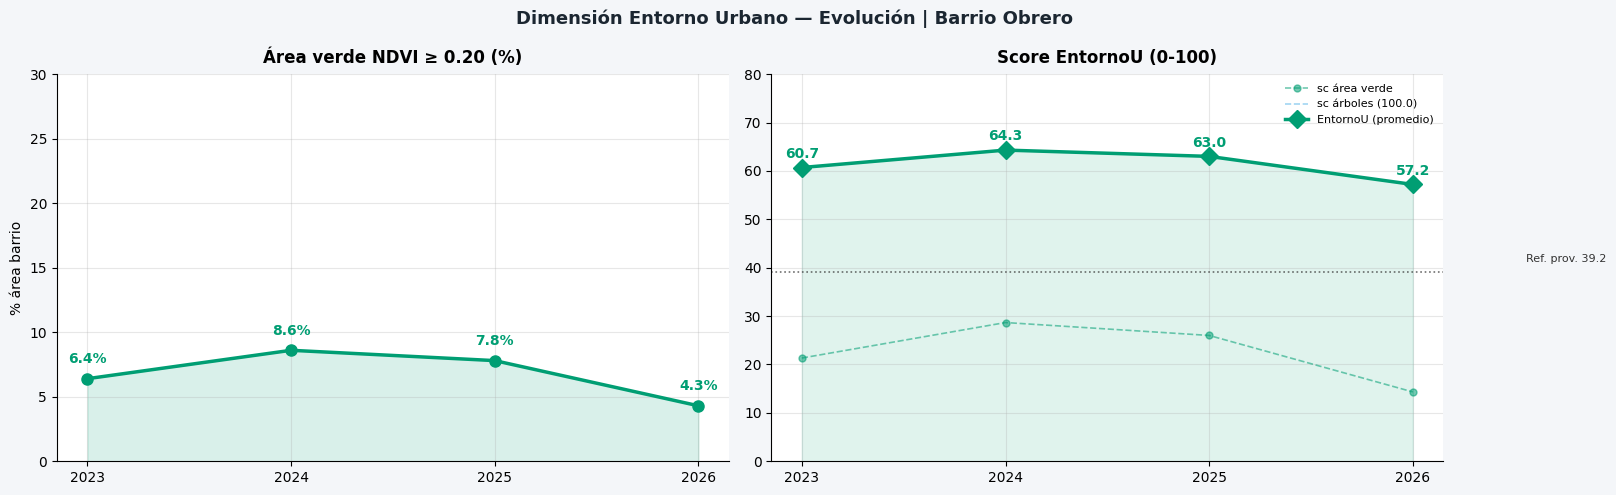

In [145]:
# ── Celda EU-4: evolución anual Entorno Urbano ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5), facecolor=BG)
fig.suptitle('Dimensión Entorno Urbano — Evolución | Barrio Obrero',
             fontsize=13, fontweight='bold', color='#1B2631')

df_e = df_eu.set_index('año').reindex(ANIOS)
x    = list(range(len(ANIOS)))

# Panel 1: % área verde
ax = axes[0]; ax.set_facecolor('white')
vals = df_e['pct_verde'].values.astype(float)
ymax = max(30, float(np.nanmax(vals)) * 1.35) if not np.all(np.isnan(vals)) else 30
ax.plot(x, vals, color=OKI_VERDE, linewidth=2.5, marker='o', markersize=8, zorder=3)
ax.fill_between(x, vals, alpha=0.15, color=OKI_VERDE)
for xi, v in zip(x, vals):
    if not np.isnan(v):
        ax.text(xi, v + ymax * 0.04, f'{v:.1f}%',
                ha='center', fontsize=10, fontweight='bold', color=OKI_VERDE)
ax.set_xticks(x); ax.set_xticklabels(ANIOS)
ax.set_ylim(0, ymax); ax.set_ylabel('% área barrio')
ax.set_title('Área verde NDVI ≥ 0.20 (%)', fontweight='bold', pad=8)
ax.spines[['top', 'right']].set_visible(False)

# Panel 2: Score con componentes
ax = axes[1]; ax.set_facecolor('white')
sc_eu  = df_e['score_entorno_u'].values.astype(float)
sc_v   = df_e['score_verde'].values.astype(float)
ax.plot(x, sc_v,
        color=OKI_VERDE,  linewidth=1.2, linestyle='--', marker='o',
        markersize=5, alpha=0.55, label='sc área verde', zorder=2)
ax.axhline(score_arboles_fijo, color=OKI_AZUL_C, linewidth=1.2,
           linestyle='--', alpha=0.55,
           label=f'sc árboles ({score_arboles_fijo})')
ax.plot(x, sc_eu, color=OKI_VERDE, linewidth=2.5, marker='D',
        markersize=9, label='EntornoU (promedio)', zorder=3)
ax.fill_between(x, sc_eu, alpha=0.12, color=OKI_VERDE)
for xi, v in zip(x, sc_eu):
    if not np.isnan(v):
        ax.text(xi, v + 2, f'{v:.1f}', ha='center', fontsize=10,
                fontweight='bold', color=OKI_VERDE)
ax.axhline(39.2, color=OKI_GRIS, linewidth=1.2, linestyle=':', alpha=0.7)
ax.text(len(x) - 0.05, 39.2 + 2, 'Ref. prov. 39.2',
        fontsize=8, color=OKI_GRIS, ha='right')
ax.set_xticks(x); ax.set_xticklabels(ANIOS)
ax.set_ylim(0, 80)
ax.set_title('Score EntornoU (0-100)', fontweight='bold', pad=8)
ax.legend(fontsize=8, frameon=False, loc='upper right')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('itt_obrero_entorno_evolucion.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


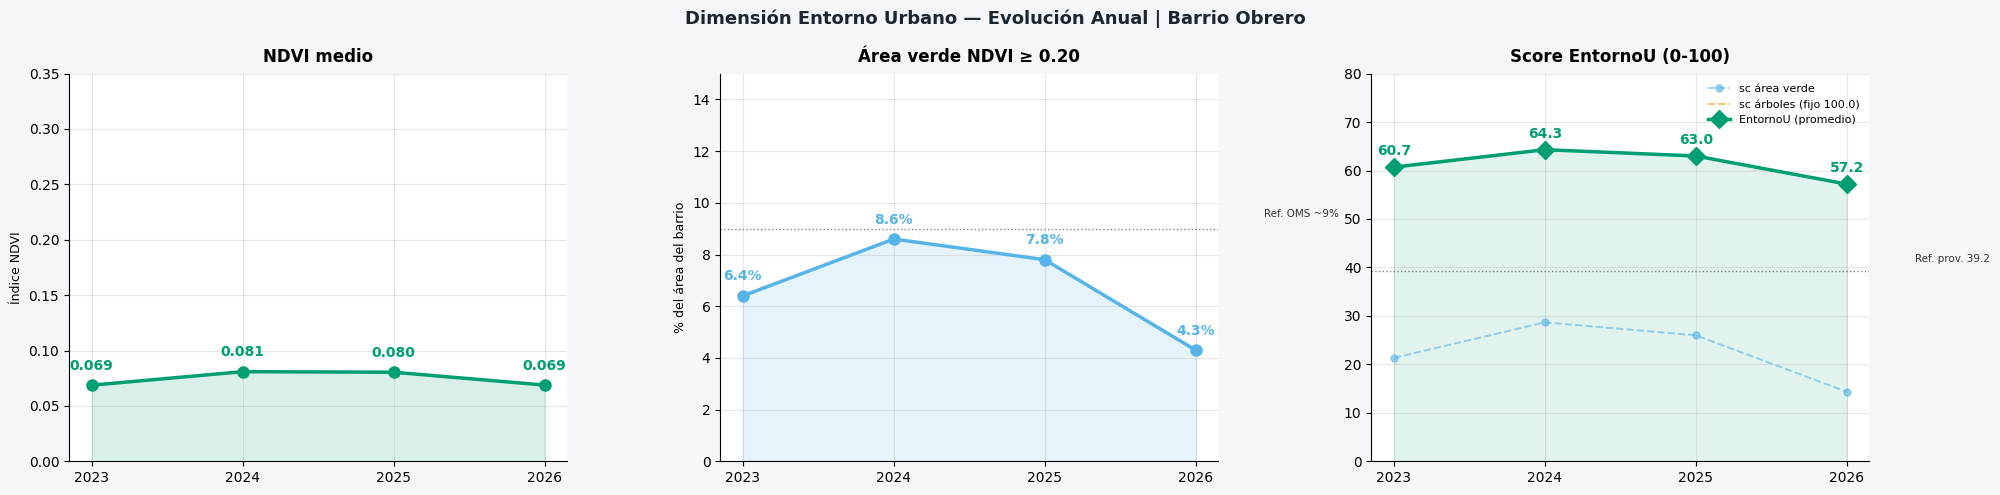

In [146]:
# ── Celda EU-4 (reemplazo): 3 indicadores Entorno Urbano en una sola figura ───
fig, axes = plt.subplots(1, 3, figsize=(20, 5), facecolor=BG)
fig.suptitle('Dimensión Entorno Urbano — Evolución Anual | Barrio Obrero',
             fontsize=13, fontweight='bold', color='#1B2631')

df_e = df_eu.set_index('año').reindex(ANIOS)
x    = list(range(len(ANIOS)))

# ── Panel 1: NDVI medio ───────────────────────────────────────────────────────
ax = axes[0]; ax.set_facecolor('white')
vals = df_e['ndvi_mean'].values.astype(float)
ymax = max(0.35, float(np.nanmax(vals)) * 1.35) if not np.all(np.isnan(vals)) else 0.35
ax.plot(x, vals, color=OKI_VERDE, linewidth=2.5, marker='o', markersize=8, zorder=3)
ax.fill_between(x, vals, alpha=0.15, color=OKI_VERDE)
for xi, v in zip(x, vals):
    if not np.isnan(v):
        ax.text(xi, v + ymax * 0.04, f'{v:.3f}',
                ha='center', fontsize=10, fontweight='bold', color=OKI_VERDE)
ax.set_xticks(x); ax.set_xticklabels(ANIOS)
ax.set_ylim(0, ymax)
ax.set_ylabel('Índice NDVI', fontsize=9)
ax.set_title('NDVI medio', fontweight='bold', pad=8)
ax.spines[['top', 'right']].set_visible(False)

# ── Panel 2: % área verde ─────────────────────────────────────────────────────
ax = axes[1]; ax.set_facecolor('white')
vals = df_e['pct_verde'].values.astype(float)
ymax = max(15, float(np.nanmax(vals)) * 1.40) if not np.all(np.isnan(vals)) else 15
ax.plot(x, vals, color=OKI_AZUL_C, linewidth=2.5, marker='o', markersize=8, zorder=3)
ax.fill_between(x, vals, alpha=0.15, color=OKI_AZUL_C)
for xi, v in zip(x, vals):
    if not np.isnan(v):
        ax.text(xi, v + ymax * 0.04, f'{v:.1f}%',
                ha='center', fontsize=10, fontweight='bold', color=OKI_AZUL_C)
# Referencia OMS: 9 m²/hab → aprox 9% para zona densa (línea de contexto)
ax.axhline(9, color=OKI_GRIS, linewidth=1.0, linestyle=':', alpha=0.6)
ax.text(len(x) - 0.05, 9 + ymax * 0.03, 'Ref. OMS ~9%',
        fontsize=7.5, color=OKI_GRIS, ha='right')
ax.set_xticks(x); ax.set_xticklabels(ANIOS)
ax.set_ylim(0, ymax)
ax.set_ylabel('% del área del barrio', fontsize=9)
ax.set_title('Área verde NDVI ≥ 0.20', fontweight='bold', pad=8)
ax.spines[['top', 'right']].set_visible(False)

# ── Panel 3: Score EntornoU con componentes ───────────────────────────────────
ax = axes[2]; ax.set_facecolor('white')
sc_eu  = df_e['score_entorno_u'].values.astype(float)
sc_v   = df_e['score_verde'].values.astype(float)

ax.plot(x, sc_v,
        color=OKI_AZUL_C, linewidth=1.4, linestyle='--', marker='o',
        markersize=5, alpha=0.6, label='sc área verde', zorder=2)
ax.axhline(score_arboles_fijo, color=OKI_NARANJA, linewidth=1.4,
           linestyle='--', alpha=0.6,
           label=f'sc árboles (fijo {score_arboles_fijo})')
ax.plot(x, sc_eu, color=OKI_VERDE, linewidth=2.5, marker='D',
        markersize=9, label='EntornoU (promedio)', zorder=3)
ax.fill_between(x, sc_eu, alpha=0.12, color=OKI_VERDE)
for xi, v in zip(x, sc_eu):
    if not np.isnan(v):
        ax.text(xi, v + 2.5, f'{v:.1f}', ha='center', fontsize=10,
                fontweight='bold', color=OKI_VERDE)
ax.axhline(39.2, color=OKI_GRIS, linewidth=1.0, linestyle=':', alpha=0.6)
ax.text(len(x) - 0.05, 39.2 + 2, 'Ref. prov. 39.2',
        fontsize=7.5, color=OKI_GRIS, ha='right')
ax.set_xticks(x); ax.set_xticklabels(ANIOS)
ax.set_ylim(0, 80)
ax.set_title('Score EntornoU (0-100)', fontweight='bold', pad=8)
ax.legend(fontsize=8, frameon=False, loc='upper right')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('itt_obrero_entorno_evolucion.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


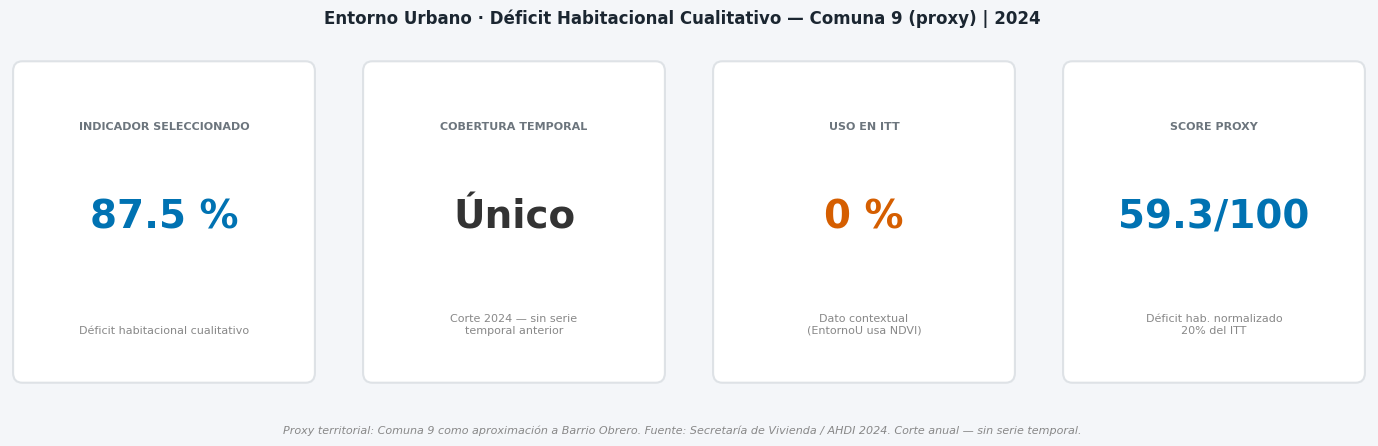

In [147]:
# ── Celda EU-3b: card Déficit Habitacional — formato dashboard ────────────────
fig = plt.figure(figsize=(14, 4), facecolor=BG)
fig.suptitle('Entorno Urbano · Déficit Habitacional Cualitativo — Comuna 9 (proxy) | 2024',
             fontsize=12, fontweight='bold', color='#1B2631', y=1.02)

posiciones = [
    [0.02, 0.08, 0.22, 0.82],
    [0.27, 0.08, 0.22, 0.82],
    [0.52, 0.08, 0.22, 0.82],
    [0.77, 0.08, 0.22, 0.82],
]

def card(ax, etiqueta_top, valor_str, etiqueta_bot, color_val):
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
    rect = mpatches.FancyBboxPatch(
        (0.04, 0.04), 0.92, 0.92,
        boxstyle='round,pad=0.03',
        linewidth=1.5, edgecolor='#DEE2E6', facecolor='white'
    )
    ax.add_patch(rect)
    ax.text(0.5, 0.78, etiqueta_top, ha='center', fontsize=8,
            color='#6C757D', fontweight='bold', transform=ax.transAxes)
    ax.text(0.5, 0.48, valor_str,    ha='center', fontsize=28,
            color=color_val, fontweight='bold', transform=ax.transAxes)
    ax.text(0.5, 0.16, etiqueta_bot, ha='center', fontsize=8,
            color='#888888', transform=ax.transAxes)

axes_c = [fig.add_axes(p) for p in posiciones]

pct_val  = globals().get('deficit_pct', None)
sc_eu_val = globals().get('REF_ENTORNO_U', 39.2)

card(axes_c[0],
     'INDICADOR SELECCIONADO',
     f'{pct_val:.1f} %' if pct_val else 'N/D',
     'Déficit habitacional cualitativo',
     OKI_AZUL)

card(axes_c[1],
     'COBERTURA TEMPORAL',
     'Único',
     'Corte 2024 — sin serie\ntemporal anterior',
     OKI_GRIS)

card(axes_c[2],
     'USO EN ITT',
     '0 %',
     'Dato contextual\n(EntornoU usa NDVI)',
     OKI_BERMELL)

card(axes_c[3],
     'SCORE PROXY',
     f'{sc_eu_val:.1f}/100',
     f'Déficit hab. normalizado\n20% del ITT',
     OKI_AZUL)

fig.text(0.5, -0.04,
    'Proxy territorial: Comuna 9 como aproximación a Barrio Obrero. '
    'Fuente: Secretaría de Vivienda / AHDI 2024. Corte anual — sin serie temporal.',
    ha='center', fontsize=8, color='#888888', style='italic')

plt.savefig('itt_obrero_deficit_card.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


## Celda ED — Educación y Desarrollo

Calcula tasas anuales de **deserción** y **repitencia** para la **IE Republica de Argentina**
 (única IE oficial en Barrio Obrero, DANE `176001005368`).

- **Numerador deserción:** SIMPADE 2023-2025 — disponible en el repo (`data/referencia/educacion/SIMPADE/`).
- **Denominador matrícula:** SIMAT Anexo 6A Diciembre — descargado desde Drive en Colab (Celda ED-2).
- **Grados válidos:** 0-11 + Aceleración del Aprendizaje (excluye adultos, PFC, prejardín).
- **2026:** sin corte anual SIMAT/SIMPADE → mantiene `REF_EDUC_DES` provisional en `base`.

Los scores de deserción y repitencia reemplazan el referente provisional `REF_EDUC_DES = 54.9`
 en `base['score_educ_des']` y recalculan el ITT global.

In [148]:
# ── Celda ED-1: configuración + carga SIMPADE (local en repo) ───────────────
import os, subprocess, importlib.util
import pandas as pd
import numpy as np
from pathlib import Path

DANE_IE    = '176001005368'   # IE Republica de Argentina
AÑOS_EDUC  = [2023, 2024, 2025]

EDUC_DIR = REPO / 'data' / 'referencia' / 'educacion'
SIMPADE_FILES = {
    2023: (EDUC_DIR / 'SIMPADE' / 'SIMPADE_2023-11.xlsx', 'xlsx'),
    2024: (EDUC_DIR / 'SIMPADE' / 'SIMPADE_2024-11.xlsx', 'xlsx'),
    2025: (EDUC_DIR / 'SIMPADE' / 'SIMPADE_2025-11.csv',  'csv'),
}

# IDs de Google Drive — Anexo 6A diciembre (corte anual de matrícula)
SIMAT_DRIVE_IDS = {
    2023: '196frGLmnvMgXR_ZD--IqdRcaEGDrVoME',
    2024: '1DEkO7Das1dcEt7qE-gJKHGJE9S5b9rRj',
    2025: '18rLE8paAcWuoRziRCgjA5Yz5lJdv--cR',
}

GRADOS_EFIC  = list(range(0, 12)) + [99]   # 0-11 + aceleración
REF_DES_MIN, REF_DES_MAX = 0, 15           # tasa deserción %
REF_REP_MIN, REF_REP_MAX = 0, 20           # tasa repitencia %

# ── Cargar SIMPADE ────────────────────────────────────────────────────────
def cargar_simpade(año, path, fmt):
    try:
        if fmt == 'xlsx':
            df = pd.read_excel(path, dtype=str)
        else:
            df = pd.read_csv(path, sep=';', encoding='utf-8-sig', dtype=str)
        df.columns = [c.strip() for c in df.columns]
        mask_ie  = df['DANE_EE'].str.strip() == DANE_IE
        mask_sec = df['SECTOR'].str.strip().str.upper() == 'OFICIAL'
        df_ie    = df[mask_ie & mask_sec]
        mask_adu = df_ie['GRADO'].astype(str).str.upper().str.contains('CICLO|ADULTO', na=False)
        return len(df_ie[~mask_adu])
    except Exception as e:
        print(f'  ERROR SIMPADE {año}: {e}')
        return np.nan

desertores_educ = {}
for año, (path, fmt) in SIMPADE_FILES.items():
    n = cargar_simpade(año, path, fmt)
    desertores_educ[año] = n
    print(f'SIMPADE {año}: {n} desertores  (IE Rep. Argentina, grados 0-11+acel, sector oficial)')

SIMPADE 2023: 194 desertores  (IE Rep. Argentina, grados 0-11+acel, sector oficial)
SIMPADE 2024: 89 desertores  (IE Rep. Argentina, grados 0-11+acel, sector oficial)
SIMPADE 2025: 102 desertores  (IE Rep. Argentina, grados 0-11+acel, sector oficial)


In [149]:
# ── Celda ED-2: SIMAT Anexo 6A — lee consolidado LOCAL si existe (sino, Drive/Colab) ──
# El consolidado liviano lo genera scripts_educ/build_educacion_barrio_obrero.py a partir
# de data/Educacion_2026 (SIMAT/SIMPADE). Asi el notebook corre local sin descargar de Drive.
import json as _json
from pathlib import Path as _Path

matricula_simat  = {}   # año → matrícula
repitentes_simat = {}   # año → repitentes

_CONS = REPO / "data" / "itt_barrio_obrero" / "6_Educacion" / "educacion_BO_2023_2026_consolidado.json"

def procesar_simat_6a(path_xlsx, año):
    """Fallback Colab: parsea el Anexo 6A crudo si no hay consolidado."""
    df = pd.read_excel(path_xlsx, dtype=str)
    df.columns = [c.strip().upper().replace(" ", "_") for c in df.columns]
    col_dane = next((c for c in df.columns if "CODIGO_DANE" in c and "SEDE" not in c), None)
    if col_dane is None or not {"SECTOR", "GRADO", "REPITENTE"}.issubset(df.columns):
        return np.nan, np.nan
    mask_ie  = df[col_dane].astype(str).str.strip() == DANE_IE
    mask_sec = df["SECTOR"].astype(str).str.strip().str.upper() == "OFICIAL"
    df_ie = df[mask_ie & mask_sec].copy()
    df_ie["_G"] = pd.to_numeric(df_ie["GRADO"], errors="coerce")
    df_ef = df_ie[df_ie["_G"].isin(GRADOS_EFIC)]
    return len(df_ef), int((df_ef["REPITENTE"].astype(str).str.strip().str.upper() == "S").sum())

if _CONS.exists():
    _c = _json.load(open(_CONS, encoding="utf-8"))
    for _a in [2023, 2024, 2025]:
        matricula_simat[_a]  = _c["matricula"].get(str(_a))
        repitentes_simat[_a] = _c["repitentes"].get(str(_a))
        _d = _c["desertores"].get(str(_a))
        if _d is not None:
            desertores_educ[_a] = _d   # completa/confirma SIMPADE desde el consolidado
    print(f"SIMAT: consolidado LOCAL leido ({_CONS.name})")
    print(f"  matricula: {{a: matricula_simat.get(a) for a in [2023,2024,2025]}}")
    print(f"  repitentes: {{a: repitentes_simat.get(a) for a in [2023,2024,2025]}}")
else:
    # Fallback Colab: descargar de Drive (metodo original)
    import importlib.util, subprocess
    if os.path.exists("/content"):
        if importlib.util.find_spec("gdown") is None:
            subprocess.run(["pip", "install", "gdown", "-q"], check=False)
        import gdown
        for año, fid in SIMAT_DRIVE_IDS.items():
            dest = _Path(f"/content/simat_6a_dic_{año}.xlsx")
            if not dest.exists():
                try:
                    gdown.download(url=f"https://drive.google.com/uc?id={fid}", output=str(dest), quiet=False, fuzzy=True)
                except Exception as e:
                    print(f"  {año}: gdown fallo -> {e}")
            if _Path(dest).exists():
                m, r = procesar_simat_6a(dest, año)
                matricula_simat[año], repitentes_simat[año] = m, r
                print(f"  SIMAT 6A {año}: matricula={m}, repitentes={r}")
            else:
                print(f"  {año}: SIMAT no disponible -> NaN")
    else:
        print("No hay consolidado local ni Colab: SIMAT -> NaN")

print()
print("Resumen desertores / matricula / repitentes:")
for año in AÑOS_EDUC:
    print(f"  {año} — desertores: {desertores_educ.get(año,'NaN')} | matricula: {matricula_simat.get(año,'NaN')} | repitentes: {repitentes_simat.get(año,'NaN')}")


SIMAT: consolidado LOCAL leido (educacion_BO_2023_2026_consolidado.json)
  matricula: {a: matricula_simat.get(a) for a in [2023,2024,2025]}
  repitentes: {a: repitentes_simat.get(a) for a in [2023,2024,2025]}

Resumen desertores / matricula / repitentes:
  2023 — desertores: 194 | matricula: 750 | repitentes: 109
  2024 — desertores: 89 | matricula: 709 | repitentes: 80
  2025 — desertores: 102 | matricula: 762 | repitentes: 78


In [150]:
# ── Celda ED-3: tasas → scores → actualizar base + recalcular ITT ───────────
rows_educ = []
for año in AÑOS_EDUC:
    m = matricula_simat.get(año, np.nan)
    r = repitentes_simat.get(año, np.nan)
    d = desertores_educ.get(año, np.nan)

    def _safe(v):
        try: return float(v)
        except: return np.nan

    m_f, r_f, d_f = _safe(m), _safe(r), _safe(d)

    tasa_des = round(d_f / m_f * 100, 2) if (not np.isnan(d_f) and not np.isnan(m_f) and m_f > 0) else np.nan
    tasa_rep = round(r_f / m_f * 100, 2) if (not np.isnan(r_f) and not np.isnan(m_f) and m_f > 0) else np.nan

    sc_des = score_ref(tasa_des, REF_DES_MIN, REF_DES_MAX, True) if not np.isnan(tasa_des) else np.nan
    sc_rep = score_ref(tasa_rep, REF_REP_MIN, REF_REP_MAX, True) if not np.isnan(tasa_rep) else np.nan

    sc_disp = [s for s in [sc_des, sc_rep] if not np.isnan(s)]
    # NaN si SIMAT no está cargado — no usar referencial para años con datos reales
    sc_educ = round(sum(sc_disp) / len(sc_disp), 1) if sc_disp else np.nan

    rows_educ.append(dict(
        año=año, matricula=m, desertores=d, repitentes=r,
        tasa_desercion=tasa_des, tasa_repitencia=tasa_rep,
        score_desercion=sc_des, score_repitencia=sc_rep,
        score_educ_des=sc_educ
    ))

df_educ = pd.DataFrame(rows_educ)
REF_MAT_MIN = float(df_educ['matricula'].dropna().min())
REF_MAT_MAX = float(df_educ['matricula'].dropna().max())
df_educ['score_matricula'] = df_educ['matricula'].apply(
    lambda v: score_ref(v, REF_MAT_MIN, REF_MAT_MAX, False) if not np.isnan(v) else np.nan
)

# ── Verificar disponibilidad SIMAT ───────────────────────────────────────
sin_simat = [r['año'] for _, r in df_educ.iterrows() if pd.isna(r['score_educ_des'])]
if sin_simat:
    print(f'⚠ SIMAT no disponible para {sin_simat} — ejecutar en Colab para scores reales.')
    print('  El ITT quedará NaN para esos años hasta cargar SIMAT.')
else:
    print('✓ SIMAT cargado — scores de educación calculados con datos reales.')
print()

print('── Educación y Desarrollo: tasas e indicadores ──────────────────────────')
cols_show = ['año','matricula','desertores','tasa_desercion','repitentes','tasa_repitencia','score_educ_des']
print(df_educ[cols_show].to_string(index=False))
print()

# ── Actualizar base con scores reales (2023-2025) ────────────────────────
for _, row in df_educ.iterrows():
    base.loc[base['año'] == int(row['año']), 'score_educ_des'] = row['score_educ_des']
    base.loc[base['año'] == int(row['año']), 'score_matricula'] = row['score_matricula']
    base.loc[base['año'] == int(row['año']), 'score_desercion'] = row['score_desercion']

# ── Recalcular ITT (5 dimensiones) ──────────────────────────────────────
base['score_des_social'] = base.apply(
    lambda r: np.nanmean([
        r.get('score_vif', np.nan),
        r.get('score_rinas', np.nan),
        r.get('score_spa', np.nan),
        r.get('score_matricula', np.nan),
        r.get('score_desercion', np.nan),
    ]),
    axis=1
)
# 2026 usa su PROPIO dato social parcial real; NO se copia de 2025 (no inventar).
# Educacion 2026 queda NaN si no hay corte -> nanmean promedia solo lo que hay.
base['ITT'] = (
    PESOS['Seguridad'] * base['score_seguridad'] +
    PESOS['Movilidad'] * base['score_movilidad'] +
    PESOS['DesSocial'] * base['score_des_social'] +
    PESOS['EntornoU']  * base['score_entorno_u'] +
    PESOS['DesEco']    * base['score_des_eco']
)
base['nivel'] = base.apply(lambda r: clasificar(r['ITT'], r['año']), axis=1)

print('ITT actualizado — Desarrollo Social con dato propio por año (2026 parcial, no copiado):')
print(base[['año','score_matricula','score_desercion','score_des_social','score_des_eco','ITT','nivel']].round(1).to_string(index=False))

✓ SIMAT cargado — scores de educación calculados con datos reales.

── Educación y Desarrollo: tasas e indicadores ──────────────────────────
 año  matricula  desertores  tasa_desercion  repitentes  tasa_repitencia  score_educ_des
2023        750         194           25.87         109            14.53            13.7
2024        709          89           12.55          80            11.28            30.0
2025        762         102           13.39          78            10.24            29.8

ITT actualizado — Desarrollo Social con dato propio por año (2026 parcial, no copiado):
 año  score_matricula  score_desercion  score_des_social  score_des_eco  ITT                   nivel
2023             77.4              0.0              48.6           50.0 50.2           Consolidacion
2024              0.0             16.3              52.5           50.0 51.1           Consolidacion
2025            100.0             10.7              45.0           50.0 53.4           Consolidacion
2026     

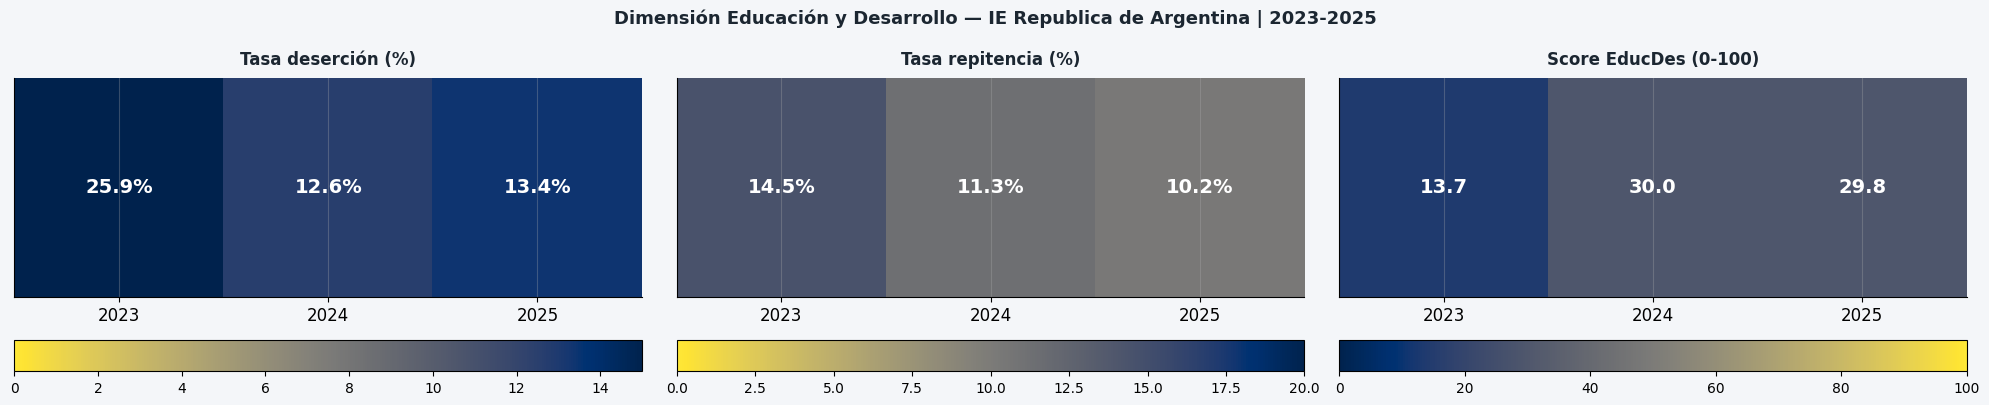

In [151]:
# ── Celda ED-4: heatmap tasas + score EducDes ────────────────────────────────
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(20, 4), facecolor=BG)
fig.suptitle(
    'Dimensión Educación y Desarrollo — IE Republica de Argentina | 2023-2025',
    fontsize=13, fontweight='bold', color='#1B2631'
)

df_e = df_educ.set_index('año').reindex(AÑOS_EDUC)

configs_hm = [
    ('tasa_desercion',  'Tasa deserción (%)',    'cividis_r', 0,   15, '%'),
    ('tasa_repitencia', 'Tasa repitencia (%)',   'cividis_r', 0,   20, '%'),
    ('score_educ_des',  'Score EducDes (0-100)', 'cividis',   0,  100, ''),
]
for ax, (col, titulo, cmap, vmin, vmax, sfx) in zip(axes, configs_hm):
    vals = df_e[col].values.astype(float).reshape(1, -1)
    im = ax.imshow(vals, cmap=cmap, aspect='auto', vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(AÑOS_EDUC)))
    ax.set_xticklabels(AÑOS_EDUC, fontsize=12)
    ax.set_yticks([])
    ax.set_title(titulo, fontweight='bold', pad=10, color='#1B2631')
    for j, v in enumerate(vals[0]):
        txt = f'{v:.1f}{sfx}' if not np.isnan(v) else 'S/D'
        ax.text(j, 0, txt, ha='center', va='center',
                fontsize=14, fontweight='bold', color='white')
    plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.14)

plt.tight_layout()
plt.savefig('itt_obrero_educacion_heatmap.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()

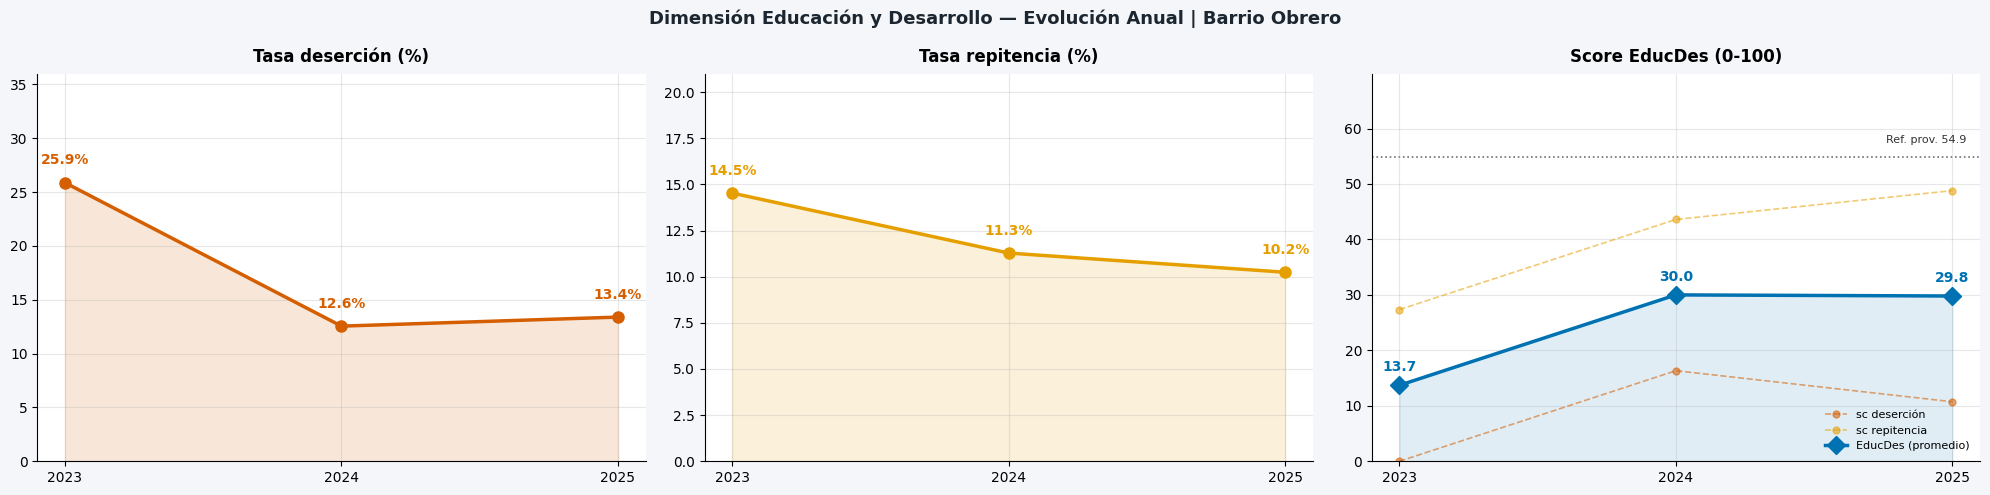

In [152]:
# ── Celda ED-5: evolución anual línea + relleno ──────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 5), facecolor=BG)
fig.suptitle(
    'Dimensión Educación y Desarrollo — Evolución Anual | Barrio Obrero',
    fontsize=13, fontweight='bold', color='#1B2631'
)

df_e = df_educ.set_index('año').reindex(AÑOS_EDUC)
x    = list(range(len(AÑOS_EDUC)))

cfg_lin = [
    ('tasa_desercion',  'Tasa deserción (%)',  OKI_BERMELL),
    ('tasa_repitencia', 'Tasa repitencia (%)', OKI_NARANJA),
]
for ax, (col, titulo, color) in zip(axes[:2], cfg_lin):
    ax.set_facecolor('white')
    vals = df_e[col].values.astype(float)
    # ylim dinámico: máximo real + 25% de margen, mínimo 20
    vmax_data = np.nanmax(vals) if not np.all(np.isnan(vals)) else 20
    ymax = max(20, round(vmax_data * 1.3 + 2, 0))
    ax.plot(x, vals, color=color, linewidth=2.5, marker='o', markersize=8, zorder=3)
    ax.fill_between(x, vals, alpha=0.15, color=color)
    for xi, v in zip(x, vals):
        if not np.isnan(v):
            # etiqueta siempre dentro del área: si el valor es muy alto, poner debajo
            offset = ymax * 0.04
            va_pos = 'bottom'
            if v + offset > ymax * 0.92:
                offset = -ymax * 0.06
                va_pos = 'top'
            ax.text(xi, v + offset, f'{v:.1f}%',
                    ha='center', va=va_pos, fontsize=10,
                    fontweight='bold', color=color)
    ax.set_xticks(x); ax.set_xticklabels(AÑOS_EDUC)
    ax.set_ylim(0, ymax)
    ax.set_title(titulo, fontweight='bold', pad=8)
    ax.spines[['top', 'right']].set_visible(False)

# Score EducDes — zoom centrado en el rango real + trazas individuales
ax = axes[2]
ax.set_facecolor('white')
sc_vals  = df_e['score_educ_des'].values.astype(float)
sc_des   = df_e['score_desercion'].values.astype(float)
sc_rep   = df_e['score_repitencia'].values.astype(float)

# Líneas de componentes en gris claro
ax.plot(x, sc_des, color=OKI_BERMELL, linewidth=1.2, linestyle='--',
        marker='o', markersize=5, alpha=0.55, label='sc deserción', zorder=2)
ax.plot(x, sc_rep, color=OKI_NARANJA, linewidth=1.2, linestyle='--',
        marker='o', markersize=5, alpha=0.55, label='sc repitencia', zorder=2)
# Línea principal EducDes
ax.plot(x, sc_vals, color=OKI_AZUL, linewidth=2.5, marker='D', markersize=9,
        label='EducDes (promedio)', zorder=3)
ax.fill_between(x, sc_vals, alpha=0.12, color=OKI_AZUL)

for xi, v in zip(x, sc_vals):
    if not np.isnan(v):
        ax.text(xi, v + 2.5, f'{v:.1f}', ha='center', fontsize=10,
                fontweight='bold', color=OKI_AZUL)

# Referencia provisional
ax.axhline(REF_EDUC_DES, color=OKI_GRIS, linewidth=1.2,
           linestyle=':', alpha=0.7, zorder=1)
ax.text(len(x) - 1 + 0.05, REF_EDUC_DES + 2.5,
        f'Ref. prov. {REF_EDUC_DES}', fontsize=8, color=OKI_GRIS, ha='right')

# ylim dinámico con mínimo visible de 0-60
all_sc = [v for v in list(sc_vals) + list(sc_des) + list(sc_rep) if not np.isnan(v)]
ymin_sc = max(0, min(all_sc) - 10) if all_sc else 0
ymax_sc = min(110, max(max(all_sc) + 12, REF_EDUC_DES + 15)) if all_sc else 110
ax.set_ylim(ymin_sc, ymax_sc)

ax.set_xticks(x); ax.set_xticklabels(AÑOS_EDUC)
ax.set_title('Score EducDes (0-100)', fontweight='bold', pad=8)
ax.legend(fontsize=8, frameon=False, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('itt_obrero_educacion_evolucion.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


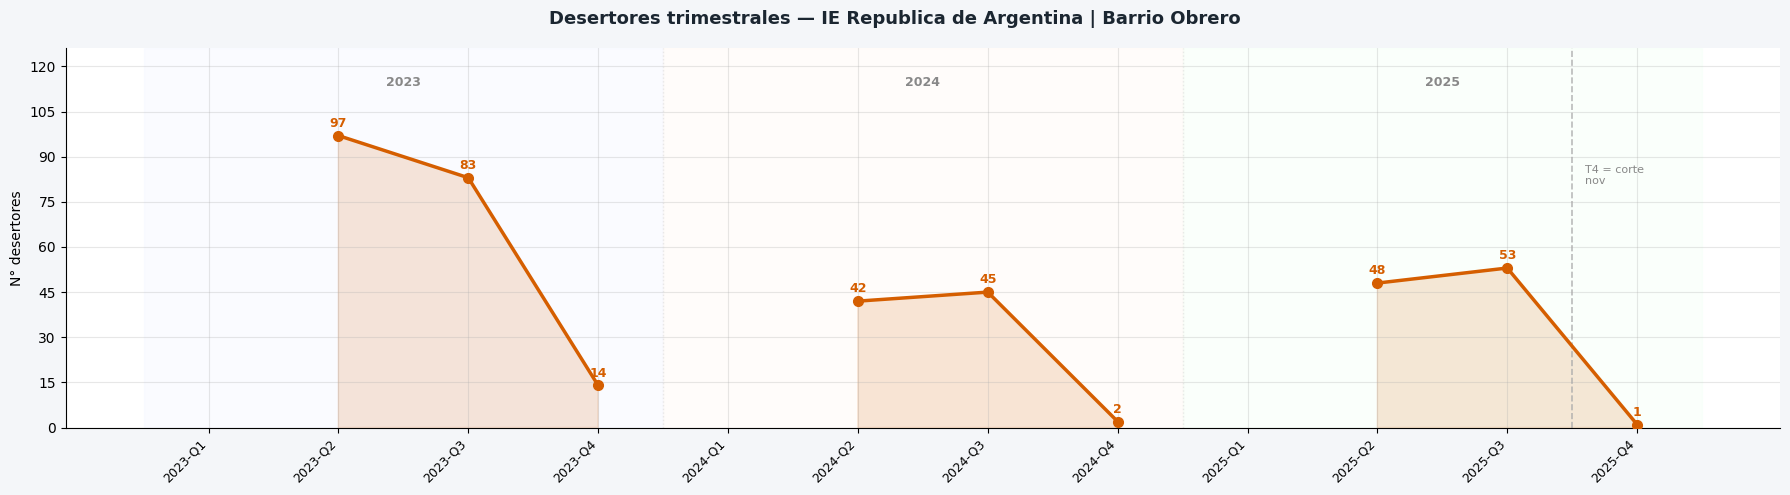

In [153]:
# ── Desertores trimestrales — IE Republica de Argentina (independiente) ───────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path

DANE_IE   = '176001005368'
EDUC_DIR  = REPO / 'data' / 'referencia' / 'educacion'
SIMPADE_FILES = {
    2023: (EDUC_DIR / 'SIMPADE' / 'SIMPADE_2023-11.xlsx', 'xlsx'),
    2024: (EDUC_DIR / 'SIMPADE' / 'SIMPADE_2024-11.xlsx', 'xlsx'),
    2025: (EDUC_DIR / 'SIMPADE' / 'SIMPADE_2025-11.csv',  'csv'),
}

def mes_a_trimestre(m):
    if m in [1,2,3]:   return 1
    if m in [4,5,6]:   return 2
    if m in [7,8,9]:   return 3
    if m in [10,11,12]: return 4
    return np.nan

# ── Cargar y agregar por trimestre ────────────────────────────────────────────
registros = []
for año, (path, fmt) in SIMPADE_FILES.items():
    try:
        df = pd.read_excel(path, dtype=str) if fmt == 'xlsx' \
             else pd.read_csv(path, sep=';', encoding='utf-8-sig', dtype=str)
        df.columns = [c.strip() for c in df.columns]
        mask = (df['DANE_EE'].str.strip() == DANE_IE) & \
               (df['SECTOR'].str.strip().str.upper() == 'OFICIAL')
        df_ie = df[mask].copy()
        mask_adu = df_ie['GRADO'].astype(str).str.upper() \
                     .str.contains('CICLO|ADULTO', na=False)
        df_ie = df_ie[~mask_adu]
        df_ie['mes']  = pd.to_numeric(df_ie['MES_FINAL'], errors='coerce')
        df_ie['trim'] = df_ie['mes'].apply(mes_a_trimestre)
        df_ie['año']  = año
        registros.append(df_ie[['año','trim']].dropna())
    except Exception as e:
        print(f'{año}: no cargado — {e}')

df_simp = pd.concat(registros, ignore_index=True) if registros else pd.DataFrame()

# ── Construir serie 12 trimestres ─────────────────────────────────────────────
periodos_educ = []
for año in [2023, 2024, 2025]:
    for t in [1, 2, 3, 4]:
        n = df_simp[(df_simp['año']==año) & (df_simp['trim']==t)].shape[0] \
            if not df_simp.empty else 0
        periodos_educ.append({'periodo': f'{año}-Q{t}',
                               'año': año, 'trimestre': t,
                               'desertores': float(n) if n > 0 else np.nan})

df_ct  = pd.DataFrame(periodos_educ)
x      = list(range(len(df_ct)))
labels = df_ct['periodo'].tolist()
vals   = df_ct['desertores'].values.astype(float)
vmax   = float(np.nanmax(vals)) if not np.all(np.isnan(vals)) else 10

# ── Figura ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(18, 5), facecolor=BG)
ax.set_facecolor('white')
fig.suptitle('Desertores trimestrales — IE Republica de Argentina | Barrio Obrero',
             fontsize=13, fontweight='bold', color='#1B2631')

ax.plot(x, vals, color=OKI_BERMELL, linewidth=2.5,
        marker='o', markersize=7, zorder=3)
ax.fill_between(x, np.where(~np.isnan(vals), vals, np.nan),
                alpha=0.15, color=OKI_BERMELL)

for xi, v in zip(x, vals):
    if not np.isnan(v) and v > 0:
        ax.text(xi, v + vmax * 0.03, str(int(v)),
                ha='center', fontsize=9, fontweight='bold', color=OKI_BERMELL)

# Línea de corte nov (T4 parcial)
idx_corte = df_ct[df_ct['periodo'] == '2025-Q3'].index[0]
ax.axvline(x=idx_corte + 0.5, color='#AAAAAA', linewidth=1.2,
           linestyle='--', alpha=0.8)
ax.text(idx_corte + 0.6, vmax * 0.90, 'T4 = corte\nnov',
        fontsize=8, color='#888888', va='top')

# Separadores de año
for sep in ['2024-Q1', '2025-Q1']:
    xi_sep = df_ct[df_ct['periodo'] == sep].index[0]
    ax.axvline(x=xi_sep - 0.5, color='#DDDDDD', linewidth=1.0,
               linestyle=':', alpha=0.6)

# Fondo por año
for año, color_f in zip([2023,2024,2025], ['#F0F4FF','#FFF8F0','#F0FFF4']):
    ini = df_ct[df_ct['año']==año].index[0]
    fin = df_ct[df_ct['año']==año].index[-1]
    ax.axvspan(ini-0.5, fin+0.5, alpha=0.3, color=color_f, zorder=0)
    ax.text((ini+fin)/2, vmax*1.17, str(año),
            ha='center', fontsize=9, color='#888888', fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=9)
ax.set_ylabel('N° desertores', fontsize=10)
ax.set_ylim(0, vmax * 1.3)
ax.spines[['top','right']].set_visible(False)
ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.savefig('itt_obrero_educacion_trim.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


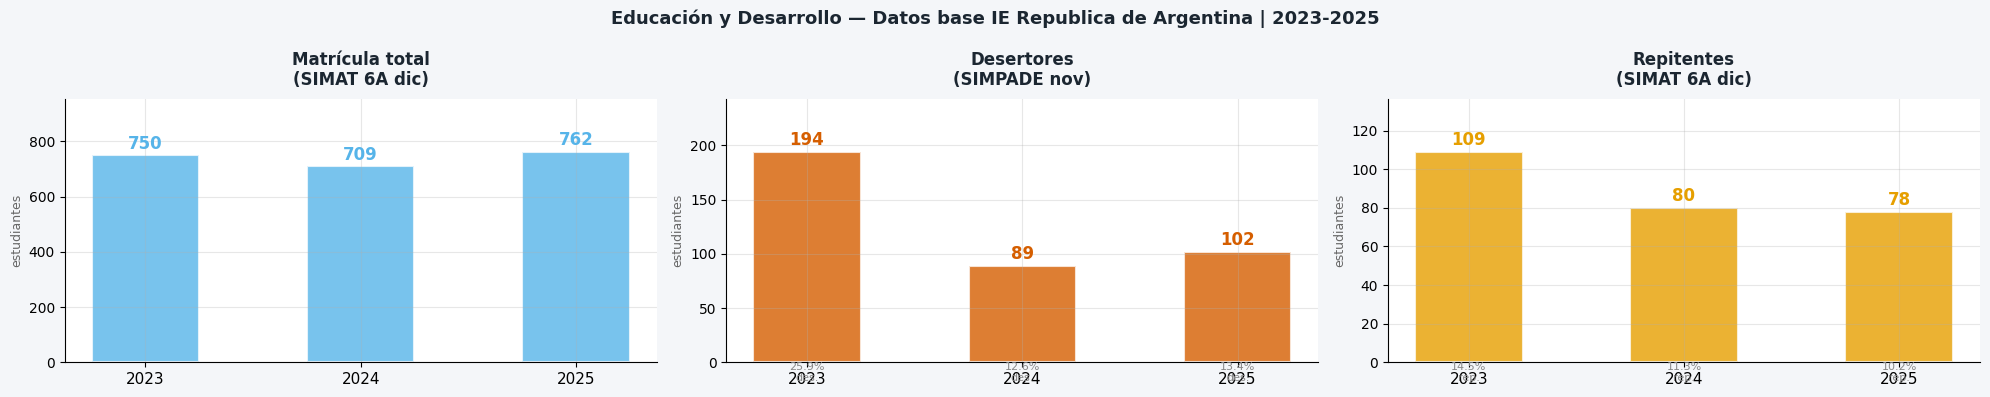

── Datos base: matrícula, desertores, repitentes, tasas ─────────────────
 año  matricula  desertores  tasa_desercion  repitentes  tasa_repitencia  score_educ_des
2023        750         194           25.87         109            14.53            13.7
2024        709          89           12.55          80            11.28            30.0
2025        762         102           13.39          78            10.24            29.8


In [154]:
# ── Celda ED-3b: tabla visual — matrícula, desertores, repitentes ─────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(20, 4), facecolor=BG)
fig.suptitle(
    'Educación y Desarrollo — Datos base IE Republica de Argentina | 2023-2025',
    fontsize=13, fontweight='bold', color='#1B2631'
)

df_e = df_educ.set_index('año').reindex(AÑOS_EDUC)

configs = [
    ('matricula',   'Matrícula total\n(SIMAT 6A dic)',     OKI_AZUL_C,  'estudiantes'),
    ('desertores',  'Desertores\n(SIMPADE nov)',            OKI_BERMELL, 'estudiantes'),
    ('repitentes',  'Repitentes\n(SIMAT 6A dic)',          OKI_NARANJA, 'estudiantes'),
]

x      = list(range(len(AÑOS_EDUC)))
ancho  = 0.5

for ax, (col, titulo, color, unidad) in zip(axes, configs):
    ax.set_facecolor('white')
    vals = df_e[col].values.astype(float)

    bars = ax.bar(x, vals, color=color, alpha=0.80, width=ancho,
                  edgecolor='white', linewidth=1.5)

    # Etiqueta encima de cada barra
    vmax = np.nanmax(vals) if not np.all(np.isnan(vals)) else 1
    for xi, v in zip(x, vals):
        if not np.isnan(v):
            ax.text(xi, v + vmax * 0.03, f'{int(v)}',
                    ha='center', fontsize=12, fontweight='bold', color=color)

    # Tasa derivada como subtítulo de cada barra
    if col == 'desertores':
        for xi, row in enumerate(df_educ.itertuples()):
            td = row.tasa_desercion
            if not np.isnan(td):
                ax.text(xi, -vmax * 0.09, f'{td:.1f}%\ndes.',
                        ha='center', fontsize=8, color='#888888', clip_on=False)
    elif col == 'repitentes':
        for xi, row in enumerate(df_educ.itertuples()):
            tr = row.tasa_repitencia
            if not np.isnan(tr):
                ax.text(xi, -vmax * 0.09, f'{tr:.1f}%\nrep.',
                        ha='center', fontsize=8, color='#888888', clip_on=False)

    ax.set_xticks(x); ax.set_xticklabels(AÑOS_EDUC, fontsize=11)
    ax.set_ylim(0, vmax * 1.25)
    ax.set_title(titulo, fontweight='bold', pad=10, color='#1B2631')
    ax.set_ylabel(unidad, fontsize=9, color='#666666')
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('itt_obrero_educacion_base.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()

# ── También imprimir tabla completa ──────────────────────────────────────────
print('── Datos base: matrícula, desertores, repitentes, tasas ─────────────────')
print(df_educ[['año','matricula','desertores','tasa_desercion',
               'repitentes','tasa_repitencia','score_educ_des']].to_string(index=False))


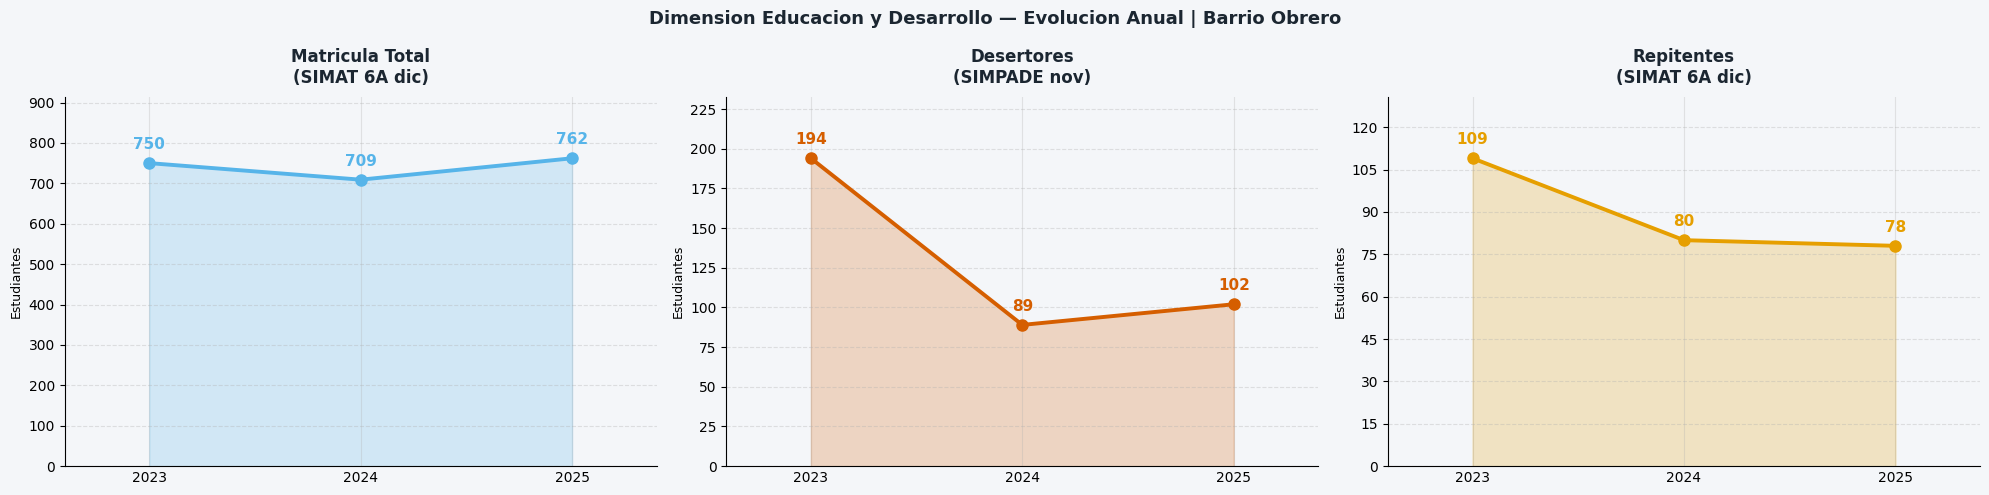

In [155]:
# ── Celda ED-6: evolución anual Educación — línea + relleno ───────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 5), facecolor=BG)
fig.suptitle('Dimension Educacion y Desarrollo — Evolucion Anual | Barrio Obrero',
             fontsize=13, fontweight='bold', color='#1B2631')

df_ep    = df_educ.set_index('año').reindex(AÑOS_EDUC)
anos_lbl = [str(a) for a in AÑOS_EDUC]
x_e      = np.arange(len(AÑOS_EDUC))

cfg_ed = [
    ('matricula',  'Matricula Total\n(SIMAT 6A dic)',   OKI_AZUL_C,  'estudiantes'),
    ('desertores', 'Desertores\n(SIMPADE nov)',          OKI_BERMELL, 'estudiantes'),
    ('repitentes', 'Repitentes\n(SIMAT 6A dic)',         OKI_NARANJA, 'estudiantes'),
]

for ax, (col, titulo, color, unidad) in zip(axes, cfg_ed):
    vals  = df_ep[col].values.astype(float)
    valid = ~np.isnan(vals)

    ax.fill_between(x_e, 0, np.where(valid, vals, np.nan),
                    alpha=0.22, color=color)
    ax.plot(x_e, np.where(valid, vals, np.nan),
            color=color, linewidth=2.8, marker='o', markersize=8, zorder=3)

    for i, v in enumerate(vals):
        if not np.isnan(v):
            ax.annotate(str(int(v)), (i, v),
                        textcoords='offset points', xytext=(0, 10),
                        ha='center', fontsize=11, fontweight='bold', color=color)

    ax.set_xticks(x_e)
    ax.set_xticklabels(anos_lbl, fontsize=10)
    ax.set_title(titulo, fontweight='bold', pad=10, color='#1B2631')
    ax.set_ylabel(unidad.capitalize(), fontsize=9)
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_xlim(-0.4, len(AÑOS_EDUC) - 0.6)
    ax.set_ylim(0, np.nanmax(vals) * 1.2)
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    ax.set_facecolor(BG)
    ax.tick_params(axis='x', length=0)

plt.tight_layout()
plt.savefig('itt_obrero_educ_evol.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


── Desertores por trimestre (IE Rep. Argentina) ──────────────────────────
  Nota: corte noviembre — T4 cubre oct-nov (parcial).
año  2023  2024  2025
T1    NaN   NaN   NaN
T2   97.0  42.0  48.0
T3   83.0  45.0  53.0
T4   14.0   2.0   1.0



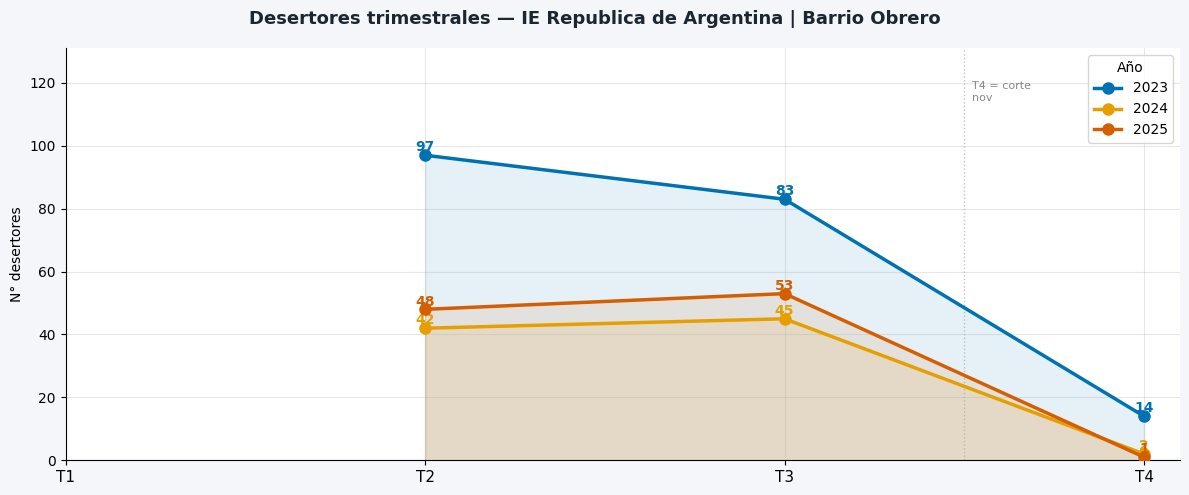

In [156]:
# ── Celda ED-5b: evolución trimestral de desertores (SIMPADE) ─────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar SIMPADE con MES_FINAL
def cargar_simpade_trim(año, path, fmt):
    if fmt == 'xlsx':
        df = pd.read_excel(path, dtype=str)
    else:
        df = pd.read_csv(path, sep=';', encoding='utf-8-sig', dtype=str)
    df.columns = [c.strip() for c in df.columns]
    mask_ie  = df['DANE_EE'].str.strip() == DANE_IE
    mask_sec = df['SECTOR'].str.strip().str.upper() == 'OFICIAL'
    df_ie    = df[mask_ie & mask_sec]
    mask_adu = df_ie['GRADO'].astype(str).str.upper().str.contains('CICLO|ADULTO', na=False)
    df_ie    = df_ie[~mask_adu].copy()
    df_ie['mes'] = pd.to_numeric(df_ie['MES_FINAL'], errors='coerce')
    df_ie['año'] = año
    return df_ie[['año', 'mes']].dropna()

frames = []
for año, (path, fmt) in SIMPADE_FILES.items():
    try:
        frames.append(cargar_simpade_trim(año, path, fmt))
    except Exception as e:
        print(f'  ERROR {año}: {e}')

df_trim_educ = pd.concat(frames, ignore_index=True)
df_trim_educ['trimestre'] = df_trim_educ['mes'].apply(
    lambda m: 1 if m <= 3 else (2 if m <= 6 else (3 if m <= 9 else 4))
)

# Tabla pivote: año × trimestre
pivot = (df_trim_educ.groupby(['año', 'trimestre'])
         .size().reset_index(name='desertores'))
tabla = pivot.pivot(index='trimestre', columns='año', values='desertores').reindex([1,2,3,4])
tabla.index = ['T1','T2','T3','T4']
print('── Desertores por trimestre (IE Rep. Argentina) ──────────────────────────')
print(f'  Nota: corte noviembre — T4 cubre oct-nov (parcial).')
print(tabla.to_string())
print()

# ── Gráfica línea + relleno ──────────────────────────────────────────────
COLS_TRIM = [OKI_AZUL, OKI_NARANJA, OKI_BERMELL]
AÑOS_EDUC_T = [2023, 2024, 2025]

fig, ax = plt.subplots(figsize=(12, 5), facecolor=BG)
ax.set_facecolor('white')
fig.suptitle(
    'Desertores trimestrales — IE Republica de Argentina | Barrio Obrero',
    fontsize=13, fontweight='bold', color='#1B2631'
)

x = [0, 1, 2, 3]
xlabels = ['T1', 'T2', 'T3', 'T4']

for año, color in zip(AÑOS_EDUC_T, COLS_TRIM):
    if año not in tabla.columns:
        continue
    vals = tabla[año].values.astype(float)
    ax.plot(x, vals, color=color, linewidth=2.5, marker='o', markersize=8,
            label=str(año), zorder=3)
    ax.fill_between(x, vals, alpha=0.10, color=color)
    for xi, v in zip(x, vals):
        if not np.isnan(v):
            ax.text(xi, v + 1.2, f'{int(v)}', ha='center', fontsize=10,
                    fontweight='bold', color=color)

ax.set_xticks(x); ax.set_xticklabels(xlabels, fontsize=11)
ax.set_ylabel('N° desertores', fontsize=10)
ax.set_ylim(0, tabla.max().max() * 1.3 + 5)
ax.axvline(x=2.5, color='#AAAAAA', linewidth=1, linestyle=':', alpha=0.7)
ax.text(2.52, ax.get_ylim()[1] * 0.92, 'T4 = corte\nnov', fontsize=8,
        color='#888888', va='top')
ax.legend(title='Año', fontsize=10)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('itt_obrero_educacion_trim.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


In [157]:
# ── Celda ED-2026M: Educacion 2026 corte marzo — desde consolidado local (no Drive) ──
import json as _json
from pathlib import Path as _Path
import pandas as pd
import numpy as np

_CONS = REPO / "data" / "itt_barrio_obrero" / "6_Educacion" / "educacion_BO_2023_2026_consolidado.json"
mat_2026_mar = rep_2026_mar = np.nan
if _CONS.exists():
    _c = _json.load(open(_CONS, encoding="utf-8"))
    mat_2026_mar = _c["matricula"].get("2026", np.nan)
    rep_2026_mar = _c["repitentes"].get("2026", np.nan)

# Referencia historica anual 2023-2025 (del consolidado / variables ya cargadas)
hist_educ = []
for ano in [2023, 2024, 2025]:
    m = matricula_simat.get(ano, np.nan)
    r = repitentes_simat.get(ano, np.nan)
    d = desertores_educ.get(ano, np.nan)
    tasa_rep = (r / m * 100) if (pd.notna(m) and pd.notna(r) and m and m > 0) else np.nan
    tasa_des = (d / m * 100) if (pd.notna(m) and pd.notna(d) and m and m > 0) else np.nan
    hist_educ.append({"ano": ano, "matricula_anual": m, "repitentes_anual": r,
                      "desertores_anual": d,
                      "tasa_repitencia_anual": round(tasa_rep, 2) if pd.notna(tasa_rep) else np.nan,
                      "tasa_desercion_anual": round(tasa_des, 2) if pd.notna(tasa_des) else np.nan})
df_hist_educ = pd.DataFrame(hist_educ)

df_educ_2026_marzo = pd.DataFrame([{
    "ano": 2026, "corte": "Marzo",
    "matricula_observada": mat_2026_mar, "repitentes_observados": rep_2026_mar,
    "desertores_observados": np.nan,
    "tasa_repitencia_observada": round(rep_2026_mar / mat_2026_mar * 100, 2) if (pd.notna(mat_2026_mar) and mat_2026_mar and mat_2026_mar > 0) else np.nan,
    "tasa_desercion_observada": np.nan,
    "score_educ_des_anual_comparable": np.nan,
    "nota": "Corte parcial marzo 2026 (SIMAT). No comparable con cierre anual 2023-2025. No entra al ITT anual.",
}])

print("Historico anual comparable 2023-2025:")
print(df_hist_educ.to_string(index=False))
print()
print("Educacion 2026 corte marzo:")
print(df_educ_2026_marzo.to_string(index=False))


Historico anual comparable 2023-2025:
 ano  matricula_anual  repitentes_anual  desertores_anual  tasa_repitencia_anual  tasa_desercion_anual
2023              750               109               194                  14.53                 25.87
2024              709                80                89                  11.28                 12.55
2025              762                78               102                  10.24                 13.39

Educacion 2026 corte marzo:
 ano corte  matricula_observada  repitentes_observados  desertores_observados  tasa_repitencia_observada  tasa_desercion_observada  score_educ_des_anual_comparable                                                                                               nota
2026 Marzo                  867                    104                    NaN                       12.0                       NaN                              NaN Corte parcial marzo 2026 (SIMAT). No comparable con cierre anual 2023-2025. No entra al ITT an

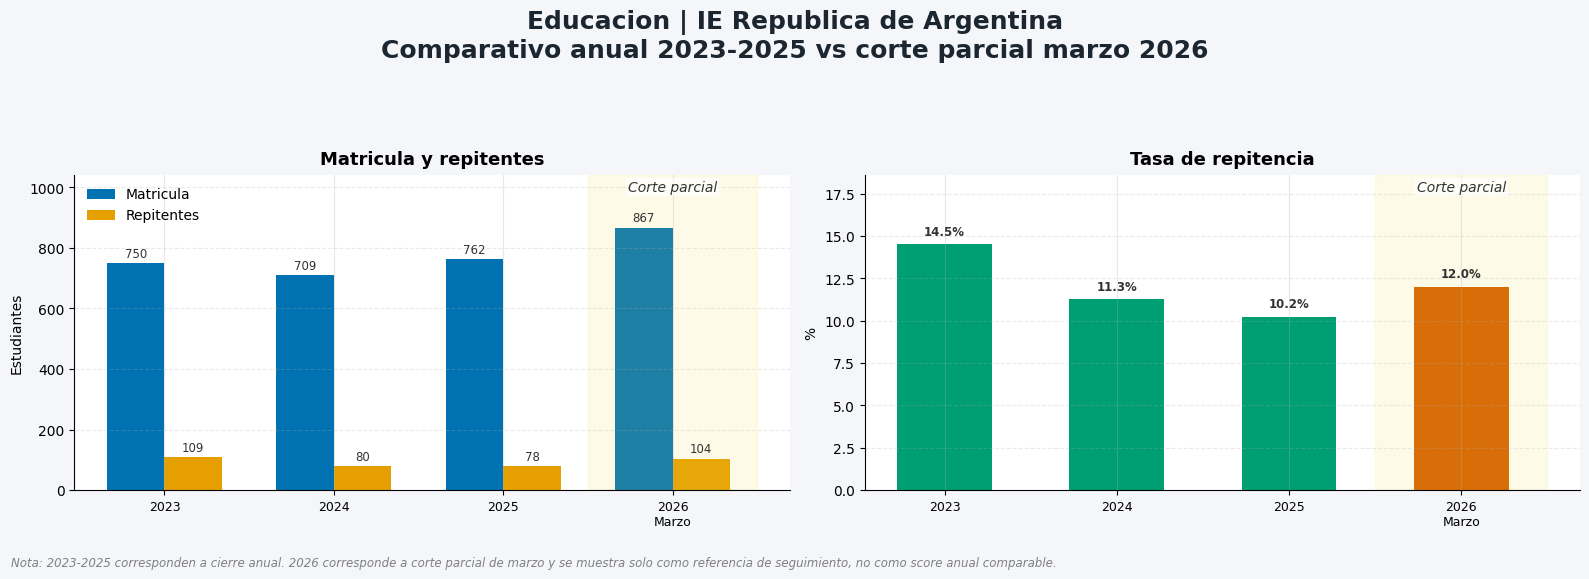

In [158]:
# ── Celda ED-2026V: Comparativo visual Educacion 2023-2025 vs 2026 marzo ──
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if 'df_hist_educ' not in globals() or 'df_educ_2026_marzo' not in globals():
    raise RuntimeError("Primero ejecuta la celda ED-2026M para crear df_hist_educ y df_educ_2026_marzo.")

# Paleta Okabe-Ito
OKI_AZUL     = "#0072B2"
OKI_NARANJA  = "#E69F00"
OKI_VERDE    = "#009E73"
OKI_AMARILLO = "#F0E442"
OKI_BERMELL  = "#D55E00"
OKI_GRIS     = "#333333"
BG           = "#F4F6F9"

df_plot = df_hist_educ.copy()
df_plot["label"] = df_plot["ano"].astype(str)

row_2026 = df_educ_2026_marzo.iloc[0]
df_plot_2026 = pd.DataFrame([{
    "label": "2026\nMarzo",
    "matricula_anual": row_2026["matricula_observada"],
    "repitentes_anual": row_2026["repitentes_observados"],
    "tasa_repitencia_anual": row_2026["tasa_repitencia_observada"],
}])

df_all = pd.concat([
    df_plot[["label", "matricula_anual", "repitentes_anual", "tasa_repitencia_anual"]],
    df_plot_2026
], ignore_index=True)

x = np.arange(len(df_all))
w = 0.34

titulo_general = (
    "Educacion | IE Republica de Argentina\n"
    "Comparativo anual 2023-2025 vs corte parcial marzo 2026"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), facecolor=BG)
fig.suptitle(
    titulo_general,
    fontsize=18, fontweight="bold", color="#1B2631", y=0.98
)

# ── Panel 1 ────────────────────────────────────────────────────────────────
ax = axes[0]
bars1 = ax.bar(x - w/2, df_all["matricula_anual"], width=w, color=OKI_AZUL, label="Matricula")
bars2 = ax.bar(x + w/2, df_all["repitentes_anual"], width=w, color=OKI_NARANJA, label="Repitentes")

ymax1 = float(df_all["matricula_anual"].fillna(0).max()) * 1.20
ax.set_ylim(0, ymax1)

# Banda 2026
ax.axvspan(len(df_all)-1 - 0.5, len(df_all)-1 + 0.5, color=OKI_AMARILLO, alpha=0.12)

# Etiqueta arriba de la banda, no sobre la barra
ax.text(
    len(df_all)-1,
    ymax1 * 0.985,
    "Corte parcial",
    ha="center", va="top",
    fontsize=10, color=OKI_GRIS, style="italic",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1.5)
)

for b in list(bars1) + list(bars2):
    h = b.get_height()
    if pd.notna(h):
        ax.text(
            b.get_x() + b.get_width()/2,
            h + ymax1 * 0.01,
            f"{int(h)}",
            ha="center", va="bottom",
            fontsize=8.5, color=OKI_GRIS
        )

ax.set_title("Matricula y repitentes", fontweight="bold", pad=8, fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(df_all["label"], fontsize=9)
ax.set_ylabel("Estudiantes")
ax.legend(frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.25)

# ── Panel 2 ────────────────────────────────────────────────────────────────
ax2 = axes[1]
colors = [OKI_VERDE, OKI_VERDE, OKI_VERDE, OKI_BERMELL]
bars3 = ax2.bar(x, df_all["tasa_repitencia_anual"], color=colors, width=0.55)

ymax2 = float(df_all["tasa_repitencia_anual"].fillna(0).max()) * 1.28
ax2.set_ylim(0, ymax2)

ax2.axvspan(len(df_all)-1 - 0.5, len(df_all)-1 + 0.5, color=OKI_AMARILLO, alpha=0.12)

ax2.text(
    len(df_all)-1,
    ymax2 * 0.985,
    "Corte parcial",
    ha="center", va="top",
    fontsize=10, color=OKI_GRIS, style="italic",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1.5)
)

for b in bars3:
    h = b.get_height()
    if pd.notna(h):
        ax2.text(
            b.get_x() + b.get_width()/2,
            h + ymax2 * 0.02,
            f"{h:.1f}%",
            ha="center", va="bottom",
            fontsize=8.5, color=OKI_GRIS, fontweight="bold"
        )

ax2.set_title("Tasa de repitencia", fontweight="bold", pad=8, fontsize=13)
ax2.set_xticks(x)
ax2.set_xticklabels(df_all["label"], fontsize=9)
ax2.set_ylabel("%")
ax2.grid(axis="y", linestyle="--", alpha=0.25)

fig.text(
    0.01, 0.02,
    "Nota: 2023-2025 corresponden a cierre anual. 2026 corresponde a corte parcial de marzo y se muestra solo como referencia de seguimiento, no como score anual comparable.",
    fontsize=8.5, color="gray", style="italic"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.88])
plt.show()



## 6. Dimensión Desarrollo Económico — Peso: 15%

Indicadores: **Creación de negocios nuevos** · **Empleabilidad formal** · **Ingresos reportados**

Fuente: Registro Mercantil 2025 — 123 negocios georreferenciados en el polígono (94.1% micro).
La periodicidad se construye desde la **fecha de matrícula** del negocio (2023-2025).
Ingresos y personal son valores reportados por los negocios creados en cada año,
no ingresos o empleos generados estrictamente en ese periodo.

**Refs calibrados con serie histórica 2023-2025:**
`negocios_nuevos: [0–15]` · `personal: [0–20]` · `ingresos log1p: [0–20.4]`


In [159]:
# ── Celda DE-1: configuración + carga Registro Mercantil (fuente consolidada) ─
# Fuente ÚNICA 2023-2026: data/itt_barrio_obrero/4_Desarrollo_Economico/
#   registro_mercantil_BO_2023_2026_consolidado.json
# Ya filtrada a Barrio Obrero (geocodificado), 1 fila por negocio (última renovación).
# NO hay empleo/personal en la fuente -> activoTotal reemplaza al componente de empleo.
with open(PATHS['registro_mercantil_consolidado'], encoding='utf-8') as f:
    _raw_de = json.load(f)

df_de = pd.DataFrame(_raw_de['registros'])
print(f"Registro Mercantil consolidado: {len(df_de)} negocios de Barrio Obrero (1 fila por negocio)")

# ── Fechas a datetime (ISO YYYY-MM-DD o null) ────────────────────────────────
df_de['fecha_mat']    = pd.to_datetime(df_de['fechaMatricula'],   errors='coerce')
df_de['fecha_renov']  = pd.to_datetime(df_de['fechaRenovacion'],  errors='coerce')
df_de['fecha_cancel'] = pd.to_datetime(df_de['fechaCancelacion'], errors='coerce')
df_de['anio_mat']     = df_de['fecha_mat'].dt.year
df_de['trim_mat']     = df_de['fecha_mat'].dt.quarter

# ── Numéricos: ingresos (ingresosOrdinarios) y activo_total (activoTotal) ─────
df_de['ingresos']    = pd.to_numeric(df_de['ingresosOrdinarios'], errors='coerce')
df_de['activo_total']= pd.to_numeric(df_de['activoTotal'],        errors='coerce')
# Solo cuentan positivos (NaN donde no hay dato — no se inventa)
df_de['ingresos_limpio'] = df_de['ingresos'].where(df_de['ingresos'] > 0, np.nan)
df_de['activo_limpio']   = df_de['activo_total'].where(df_de['activo_total'] > 0, np.nan)
# CIIU (float en la fuente -> entero como string para agrupar por sector)
df_de['codigo_ciiu'] = pd.to_numeric(df_de['codigo_ciiu'], errors='coerce')

# ── EMPLEO (PERSONAL_O): nº de personas empleadas, igual que Ciudad Paraíso ───
# El consolidado NO trae empleo; se recupera del geojson 2025 con coordenadas
# (campo PERSONAL_O, clave NUM_INSCRI) y se mapea a cada negocio por numeroInscrito.
# Supuesto: el empleo por negocio (corte 2025) se mantiene estable en la serie.
import re as _re
EMPLEO_POR_NEGOCIO = {}
try:
    _geo_emp = pd.DataFrame([f['properties'] for f in load_gj(PATHS['registro_mercantil'])['features']])
    _geo_emp['_k'] = _geo_emp['NUM_INSCRI'].astype(str).str.replace(r'[=\"\s]', '', regex=True)
    _geo_emp['_p'] = pd.to_numeric(_geo_emp['PERSONAL_O'], errors='coerce')
    EMPLEO_POR_NEGOCIO = _geo_emp.dropna(subset=['_p']).set_index('_k')['_p'].to_dict()
    print(f"  Empleo por negocio (PERSONAL_O 2025): {len(EMPLEO_POR_NEGOCIO)} negocios con dato")
except Exception as _e:
    print(f"  [AVISO] no se pudo leer empleo (PERSONAL_O): {type(_e).__name__}; empleo = NaN")
df_de['_k']     = df_de['numeroInscrito'].astype(str).str.strip()
df_de['empleo'] = pd.to_numeric(df_de['_k'].map(EMPLEO_POR_NEGOCIO), errors='coerce')

print(f"  Rango matrícula: {int(df_de['anio_mat'].min())}-{int(df_de['anio_mat'].max())}")
print(f"  Cancelados (fechaCancelacion no nula): {df_de['fecha_cancel'].notna().sum()}")
print(f"  Ingresos positivos stock total: ${df_de['ingresos_limpio'].sum():,.0f}")
print(f"  Activo total positivo stock total: ${df_de['activo_limpio'].sum():,.0f}")


Registro Mercantil consolidado: 1175 negocios de Barrio Obrero (1 fila por negocio)
  Empleo por negocio (PERSONAL_O 2025): 761 negocios con dato
  Rango matrícula: 1970-2026
  Cancelados (fechaCancelacion no nula): 124
  Ingresos positivos stock total: $179,411,843,520
  Activo total positivo stock total: $153,114,085,828


In [160]:
# ── Celda DE-2: stock activo 2023-2026 (fuente consolidada) ──────────────────
# Lógica stock-activo por año X: un negocio cuenta si fecha_mat.year <= X
#   Y no fue cancelado hasta X (fecha_cancel nula, o su año > X).
# Componentes DE: establecimientos, ingresos (suma ingresos>0), activo_total (suma>0).
# NO hay empleo en la fuente -> el componente de empleo se reemplaza por activo_total.
ANIOS_DE = [2023, 2024, 2025, 2026]

def _stock_mask(df, X):
    mat_ok     = df['anio_mat'] <= X
    not_cancel = df['fecha_cancel'].isna() | (df['fecha_cancel'].dt.year > X)
    return mat_ok & not_cancel

rows_de_stock = []
for ano in ANIOS_DE:
    sub = df_de[_stock_mask(df_de, ano)].copy()
    est   = int(len(sub))
    ing   = float(sub.loc[sub['ingresos_limpio'] > 0, 'ingresos_limpio'].sum())
    act   = float(sub.loc[sub['activo_limpio']   > 0, 'activo_limpio'].sum())
    n_ing = int(sub['ingresos_limpio'].notna().sum())
    rows_de_stock.append({
        'año': ano,
        'tipo_dato': 'Real (stock activo consolidado)',
        'establecimientos_activos': float(est),
        'ingresos_operacionales': ing,
        'activo_total': act,
        'negocios_con_ingreso': n_ing,
        'ingresos_log1p': float(np.log1p(ing)),
        'activo_log1p':   float(np.log1p(act)),
        'empleo_personas': float(sub.loc[sub['empleo'] >= 0, 'empleo'].sum()),
    })
df_de_stock = pd.DataFrame(rows_de_stock)

# ── Referencias de normalización (min-max) ───────────────────────────────────
REF_EST_MIN = 0
REF_EST_MAX = int(df_de_stock['establecimientos_activos'].max())
REF_ING_STOCK_MIN = float(df_de_stock['ingresos_log1p'].min())
REF_ING_STOCK_MAX = float(df_de_stock['ingresos_log1p'].max())
REF_ACT_STOCK_MIN = float(df_de_stock['activo_log1p'].min())
REF_ACT_STOCK_MAX = float(df_de_stock['activo_log1p'].max())
_emp_max = float(df_de_stock['empleo_personas'].max())
REF_EMP_MIN, REF_EMP_MAX = 0, (_emp_max * 1.15 if _emp_max > 0 else 1)  # empleo (personas, stock activo)

# ── Compatibilidad con visualizaciones (celdas 69-73, 92) ────────────────────
# Mantienen las columnas negocios_nuevos / personal_nuevos / ingresos_nuevos.
# NO hay empleo -> personal_nuevos = NaN. Flujo de matrículas por año/trimestre
# (fecha_mat) para negocios_nuevos e ingresos_nuevos.
rows_de_trim = []
for ano in ANIOS_DE:
    for trim in [1, 2, 3, 4]:
        sub = df_de[(df_de['anio_mat'] == ano) & (df_de['trim_mat'] == trim)]
        rows_de_trim.append({
            'periodo': f'{ano}-Q{trim}', 'año': ano, 'trimestre': trim,
            'negocios_nuevos': int(len(sub)),
            'personal_nuevos': np.nan,
            'ingresos_nuevos': float(sub.loc[sub['ingresos_limpio'] > 0, 'ingresos_limpio'].sum()),
        })
df_de_trim = pd.DataFrame(rows_de_trim)

rows_de_anual = []
for ano in ANIOS_DE:
    sub = df_de[df_de['anio_mat'] == ano]
    rows_de_anual.append({
        'año': ano,
        'negocios_nuevos': int(len(sub)),
        'personal_nuevos': np.nan,
        'ingresos_nuevos': float(sub.loc[sub['ingresos_limpio'] > 0, 'ingresos_limpio'].sum()),
    })
df_de_anual = pd.DataFrame(rows_de_anual)

print("Actividad Económica — stock activo 2023-2026 (fuente consolidada)")
print(df_de_stock[['año', 'tipo_dato', 'establecimientos_activos',
                   'ingresos_operacionales', 'activo_total',
                   'negocios_con_ingreso']].to_string(index=False))
print()
print(f"REF_EST       [{REF_EST_MIN} - {REF_EST_MAX}]")
print(f"REF_ING_STOCK [{REF_ING_STOCK_MIN:.3f} - {REF_ING_STOCK_MAX:.3f}] (log1p)")
print(f"REF_ACT_STOCK [{REF_ACT_STOCK_MIN:.3f} - {REF_ACT_STOCK_MAX:.3f}] (log1p)")
print()
print("Matrículas por año (flujo — para visualizaciones):")
print(df_de_anual.to_string(index=False))


Actividad Económica — stock activo 2023-2026 (fuente consolidada)
 año                       tipo_dato  establecimientos_activos  ingresos_operacionales  activo_total  negocios_con_ingreso
2023 Real (stock activo consolidado)                     862.0            1.734567e+11  1.447477e+11                   218
2024 Real (stock activo consolidado)                     939.0            1.747839e+11  1.481128e+11                   219
2025 Real (stock activo consolidado)                    1016.0            1.706523e+11  1.475886e+11                   222
2026 Real (stock activo consolidado)                    1051.0            1.694511e+11  1.481229e+11                   218

REF_EST       [0 - 1051]
REF_ING_STOCK [25.856 - 25.887] (log1p)
REF_ACT_STOCK [25.698 - 25.721] (log1p)

Matrículas por año (flujo — para visualizaciones):
 año  negocios_nuevos  personal_nuevos  ingresos_nuevos
2023               84              NaN     4909697209.0
2024               89              NaN     308858

In [161]:
# ── Celda DE-3: score oficial ITT | stock activo consolidado 2023-2026 ───────
# Requiere:
# - df_de_stock creado en DE-2 (con ingresos_log1p, activo_log1p)
# - REF_EST_MIN/MAX, REF_ING_STOCK_MIN/MAX, REF_ACT_STOCK_MIN/MAX definidos en DE-2
# - base, score_ref, clasificar y PESOS ya definidos
# Componentes DE: establecimientos, ingresos, activo_total (reemplaza empleo).
# score_des_eco = promedio (nanmean) de los componentes NO nulos.
rows_de_sc = []
for _, row in df_de_stock.iterrows():
    ano     = int(row['año'])
    neg     = float(row['establecimientos_activos'])
    ing     = float(row['ingresos_operacionales'])
    act     = float(row['activo_total'])
    ing_log = float(row['ingresos_log1p']) if pd.notna(row['ingresos_log1p']) else np.nan
    act_log = float(row['activo_log1p'])   if pd.notna(row['activo_log1p'])   else np.nan

    sc_neg = score_ref(neg,     REF_EST_MIN,       REF_EST_MAX,       False) if not pd.isna(neg)     else np.nan
    sc_ing = score_ref(ing_log, REF_ING_STOCK_MIN, REF_ING_STOCK_MAX, False) if not pd.isna(ing_log) else np.nan
    sc_act = score_ref(act_log, REF_ACT_STOCK_MIN, REF_ACT_STOCK_MAX, False) if not pd.isna(act_log) else np.nan
    emp     = float(row['empleo_personas']) if pd.notna(row['empleo_personas']) else np.nan
    sc_emp  = score_ref(emp, REF_EMP_MIN, REF_EMP_MAX, False) if (not pd.isna(emp) and emp > 0) else np.nan

    sc_de = float(np.nanmean([sc_neg, sc_ing, sc_act, sc_emp])) if np.any(~pd.isna([sc_neg, sc_ing, sc_act, sc_emp])) else np.nan
    rows_de_sc.append({
        'año': ano,
        'tipo_dato': row['tipo_dato'],
        'establecimientos_activos': neg,
        'ingresos_operacionales': ing,
        'activo_total': act,
        'negocios_con_ingreso': float(row['negocios_con_ingreso']),
        'ingresos_log1p': ing_log,
        'activo_log1p': act_log,
        'empleo_personas': emp,
        'score_establecimientos': sc_neg,
        'score_ingresos': sc_ing,
        'score_activo_total': sc_act,
        'score_empleo': sc_emp,
        'score_des_eco': sc_de,
    })
df_de_scores = pd.DataFrame(rows_de_sc)

for _, r in df_de_scores.iterrows():
    if not pd.isna(r['score_des_eco']):
        base.loc[base['año'] == int(r['año']), 'score_des_eco'] = r['score_des_eco']

# Recalcular ITT con los 5 scores definitivos
base['ITT'] = (
    PESOS['Seguridad'] * base['score_seguridad'] +
    PESOS['Movilidad'] * base['score_movilidad'] +
    PESOS['DesSocial'] * base['score_des_social'] +
    PESOS['EntornoU']  * base['score_entorno_u'] +
    PESOS['DesEco']    * base['score_des_eco']
)
# OJO: clasificar DEBE recibir el año (2026 queda 'Parcial (no comparable)')
base['nivel'] = base.apply(lambda r: clasificar(r['ITT'], r['año']), axis=1)

print("Scores Desarrollo Economico por año — oficial ITT (stock activo consolidado):")
cols_sc = [
    'año', 'tipo_dato', 'establecimientos_activos', 'ingresos_operacionales',
    'activo_total', 'empleo_personas', 'negocios_con_ingreso', 'score_establecimientos',
    'score_ingresos', 'score_activo_total', 'score_empleo', 'score_des_eco'
]
print(df_de_scores[cols_sc].round(2).to_string(index=False))
print()
print("ITT actualizado — 5 dimensiones:")
cols_b = [
    'año', 'score_seguridad', 'score_movilidad', 'score_des_social',
    'score_entorno_u', 'score_des_eco', 'ITT', 'nivel'
]
print(base[cols_b].round(1).to_string(index=False))


Scores Desarrollo Economico por año — oficial ITT (stock activo consolidado):
 año                       tipo_dato  establecimientos_activos  ingresos_operacionales  activo_total  empleo_personas  negocios_con_ingreso  score_establecimientos  score_ingresos  score_activo_total  score_empleo  score_des_eco
2023 Real (stock activo consolidado)                     862.0            1.734567e+11  1.447477e+11           1710.0                 218.0                   82.02            75.4                0.00         83.30          60.18
2024 Real (stock activo consolidado)                     939.0            1.747839e+11  1.481128e+11           1762.0                 219.0                   89.34           100.0               99.70         85.84          93.72
2025 Real (stock activo consolidado)                    1016.0            1.706523e+11  1.475886e+11           1785.0                 222.0                   96.67            22.8               84.32         86.96          72.69
2026 R

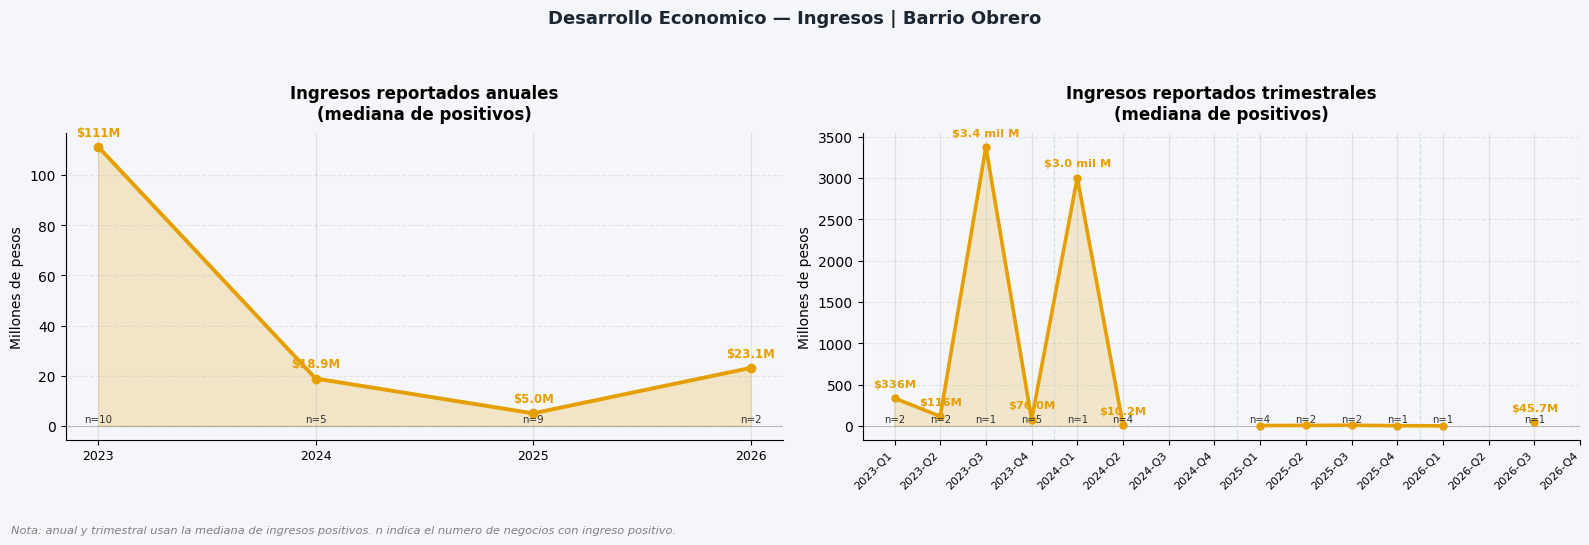

Resumen anual:


,año,negocios_con_ingreso,ingreso_mediano,ingreso_mediano_m
0,2023,10,111310250.0,111.31025
1,2024,5,18878000.0,18.87800
2,2025,9,5000000.0,5.00000
3,2026,2,23110000.0,23.11000


Resumen trimestral:


,periodo,negocios_con_ingreso,ingreso_mediano,ingreso_mediano_m
0,2023-Q1,2,3.355000e+08,335.500000
1,2023-Q2,2,1.158310e+08,115.831000
2,2023-Q3,1,3.378715e+09,3378.714708
3,2023-Q4,5,7.600000e+07,76.000000
4,2024-Q1,1,3.006395e+09,3006.395092
5,2024-Q2,4,1.019423e+07,10.194234
6,2024-Q3,0,NaN,NaN
7,2024-Q4,0,NaN,NaN
8,2025-Q1,4,3.500000e+06,3.500000
9,2025-Q2,2,5.500000e+06,5.500000


In [162]:
# ── Celda DE-ING-VIS: Ingresos | anual + trimestral robustos | Barrio Obrero ─
# Fuente consolidada (df_de): ingresos = ingresosOrdinarios; serie = mediana de positivos.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
if 'BG' not in globals():         BG = '#F4F6F9'
if 'OKI_NARANJA' not in globals(): OKI_NARANJA = '#E69F00'
if 'OKI_GRIS' not in globals():    OKI_GRIS = '#333333'
_df = df_de.copy()
_df['anio_mat'] = _df['fecha_mat'].dt.year
_df['trim_mat'] = _df['fecha_mat'].dt.quarter
_df['ingresos_pos'] = pd.to_numeric(_df['ingresos'], errors='coerce')
_df.loc[_df['ingresos_pos'] <= 0, 'ingresos_pos'] = np.nan
ANIOS_ING = [2023, 2024, 2025, 2026]
# ---------- Serie anual robusta ----------
rows_anual = []
for ano in ANIOS_ING:
    sub = _df[_df['anio_mat'] == ano].copy()
    med = float(sub['ingresos_pos'].median()) if sub['ingresos_pos'].notna().any() else np.nan
    n_pos = int(sub['ingresos_pos'].notna().sum())
    rows_anual.append({
        'año': ano,
        'negocios_con_ingreso': n_pos,
        'ingreso_mediano': med,
        'ingreso_mediano_m': med / 1e6 if pd.notna(med) else np.nan
    })
df_ing_anual = pd.DataFrame(rows_anual)
# ---------- Serie trimestral robusta ----------
rows_trim = []
for ano in ANIOS_ING:
    for trim in [1, 2, 3, 4]:
        sub = _df[(_df['anio_mat'] == ano) & (_df['trim_mat'] == trim)].copy()
        med = float(sub['ingresos_pos'].median()) if sub['ingresos_pos'].notna().any() else np.nan
        n_pos = int(sub['ingresos_pos'].notna().sum())
        rows_trim.append({
            'periodo': f'{ano}-Q{trim}',
            'año': ano,
            'trimestre': trim,
            'negocios_con_ingreso': n_pos,
            'ingreso_mediano': med,
            'ingreso_mediano_m': med / 1e6 if pd.notna(med) else np.nan
        })
df_ing_trim = pd.DataFrame(rows_trim)
def fmt_compacto_m(v):
    if not pd.notna(v):
        return '—'
    if v >= 1000:
        return f'${v/1000:.1f} mil M'
    if v >= 100:
        return f'${v:.0f}M'
    if v >= 10:
        return f'${v:.1f}M'
    return f'${v:.1f}M'
fig, axes = plt.subplots(1, 2, figsize=(16, 5.4), facecolor=BG)
fig.suptitle('Desarrollo Economico — Ingresos | Barrio Obrero',
             fontsize=13, fontweight='bold', color='#1B2631')
# Panel 1 — anual
ax = axes[0]
x1 = np.arange(len(df_ing_anual))
vals1 = df_ing_anual['ingreso_mediano_m'].to_numpy(dtype=float)
ax.fill_between(x1, vals1, where=~np.isnan(vals1), alpha=0.20, color=OKI_NARANJA)
ax.plot(x1, vals1, color=OKI_NARANJA, linewidth=2.8, marker='o', markersize=6, zorder=3)
for i, row in df_ing_anual.iterrows():
    v = row['ingreso_mediano_m']
    if pd.notna(v) and v > 0:
        ax.annotate(fmt_compacto_m(v), (i, v), textcoords='offset points',
                    xytext=(0, 8), ha='center', fontsize=8.5, fontweight='bold', color=OKI_NARANJA)
        ax.annotate(f"n={int(row['negocios_con_ingreso'])}", (i, 0), textcoords='offset points',
                    xytext=(0, 3), ha='center', fontsize=7.4, color=OKI_GRIS)
ax.set_xticks(x1); ax.set_xticklabels(df_ing_anual['año'].astype(str), fontsize=9)
ax.set_title('Ingresos reportados anuales\n(mediana de positivos)', pad=10, fontweight='bold')
ax.set_ylabel('Millones de pesos'); ax.axhline(0, color=OKI_GRIS, linewidth=0.5, alpha=0.4)
ax.grid(axis='y', linestyle='--', alpha=0.25); ax.set_facecolor(BG)
# Panel 2 — trimestral
ax2 = axes[1]
x2 = np.arange(len(df_ing_trim))
vals2 = df_ing_trim['ingreso_mediano_m'].to_numpy(dtype=float)
ax2.fill_between(x2, vals2, where=~np.isnan(vals2), alpha=0.18, color=OKI_NARANJA)
ax2.plot(x2, vals2, color=OKI_NARANJA, linewidth=2.6, marker='o', markersize=5, zorder=3)
vals2_valid = vals2[~np.isnan(vals2)]
max_trim = np.nanmax(vals2_valid) if len(vals2_valid) else np.nan
for i, row in df_ing_trim.iterrows():
    v = row['ingreso_mediano_m']
    if not pd.notna(v) or v <= 0:
        continue
    if (pd.notna(max_trim) and v == max_trim) or v >= 10:
        ax2.annotate(fmt_compacto_m(v), (i, v), textcoords='offset points',
                     xytext=(0, 8), ha='center', fontsize=8.2, fontweight='bold', color=OKI_NARANJA)
for i, n in enumerate(df_ing_trim['negocios_con_ingreso'].values):
    if n > 0:
        ax2.annotate(f'n={int(n)}', (i, 0), textcoords='offset points',
                     xytext=(0, 3), ha='center', fontsize=7.2, color=OKI_GRIS)
ax2.set_xticks(x2); ax2.set_xticklabels(df_ing_trim['periodo'], rotation=45, ha='right', fontsize=8)
ax2.set_title('Ingresos reportados trimestrales\n(mediana de positivos)', pad=10, fontweight='bold')
ax2.set_ylabel('Millones de pesos'); ax2.axhline(0, color=OKI_GRIS, linewidth=0.5, alpha=0.4)
ax2.grid(axis='y', linestyle='--', alpha=0.25); ax2.set_facecolor(BG)
for cut in [3.5, 7.5, 11.5]:
    ax2.axvline(cut, color='#D0D7DE', linewidth=0.9, linestyle='--', alpha=0.8)
fig.text(0.01, 0.01,
         'Nota: anual y trimestral usan la mediana de ingresos positivos. n indica el numero de negocios con ingreso positivo.',
         fontsize=8.2, color='gray', style='italic')
plt.tight_layout(rect=[0, 0.06, 1, 0.93])
plt.savefig('itt_obrero_ingresos_anual_trimestral_mediana.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Resumen anual:')
try:
    display(df_ing_anual)
except NameError:
    print(df_ing_anual.to_string(index=False))
print('Resumen trimestral:')
try:
    display(df_ing_trim[['periodo', 'negocios_con_ingreso', 'ingreso_mediano', 'ingreso_mediano_m']])
except NameError:
    print(df_ing_trim[['periodo', 'negocios_con_ingreso', 'ingreso_mediano', 'ingreso_mediano_m']].to_string(index=False))


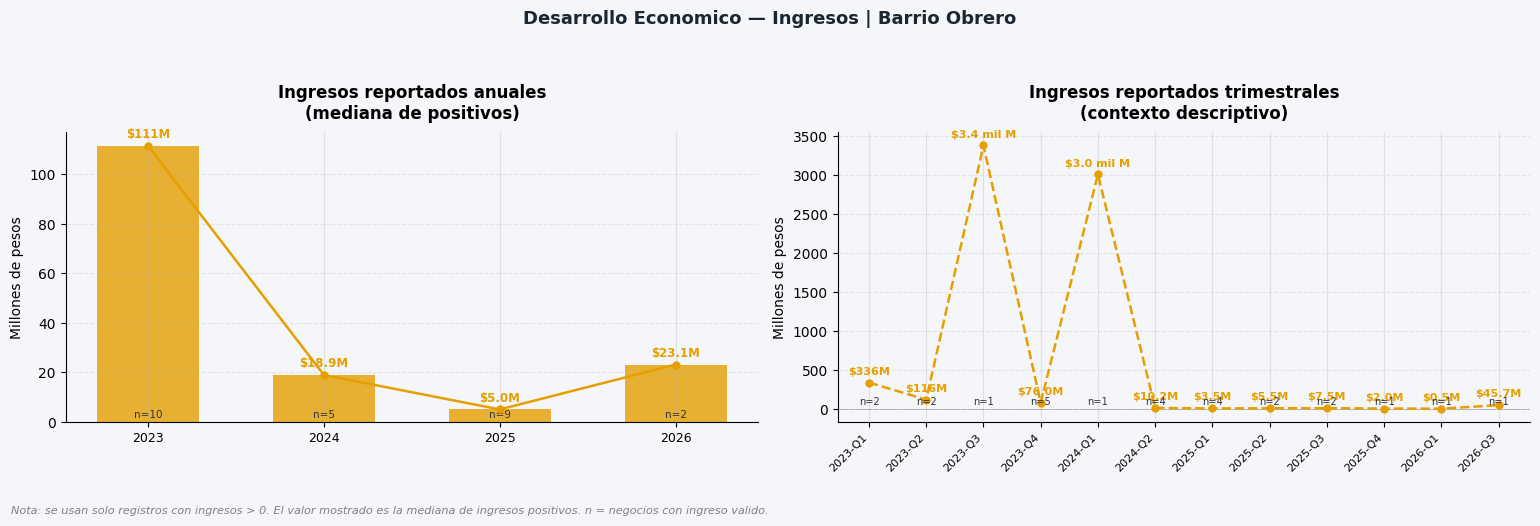

Resumen anual:


,año,negocios_con_ingreso,ingreso_mediano,ingreso_mediano_m
0,2023,10,111310250.0,111.31025
1,2024,5,18878000.0,18.87800
2,2025,9,5000000.0,5.00000
3,2026,2,23110000.0,23.11000


Resumen trimestral con dato positivo:


,periodo,negocios_con_ingreso,ingreso_mediano,ingreso_mediano_m
0,2023-Q1,2,3.355000e+08,335.500000
1,2023-Q2,2,1.158310e+08,115.831000
2,2023-Q3,1,3.378715e+09,3378.714708
3,2023-Q4,5,7.600000e+07,76.000000
4,2024-Q1,1,3.006395e+09,3006.395092
5,2024-Q2,4,1.019423e+07,10.194234
6,2025-Q1,4,3.500000e+06,3.500000
7,2025-Q2,2,5.500000e+06,5.500000
8,2025-Q3,2,7.500000e+06,7.500000
9,2025-Q4,1,2.000000e+06,2.000000


In [163]:
# ── Celda DE-ING-VIS: Ingresos | visual contextual honesto | Barrio Obrero ─
# Fuente consolidada (df_de): ingresos = ingresosOrdinarios; serie = mediana de positivos.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
if 'BG' not in globals():         BG = '#F4F6F9'
if 'OKI_NARANJA' not in globals(): OKI_NARANJA = '#E69F00'
if 'OKI_GRIS' not in globals():    OKI_GRIS = '#333333'
_df = df_de.copy()
_df['anio_mat'] = _df['fecha_mat'].dt.year
_df['trim_mat'] = _df['fecha_mat'].dt.quarter
_df['ingresos_pos'] = pd.to_numeric(_df['ingresos'], errors='coerce')
_df.loc[_df['ingresos_pos'] <= 0, 'ingresos_pos'] = np.nan
ANIOS_ING = [2023, 2024, 2025, 2026]
# ---------- Serie anual robusta ----------
rows_anual = []
for ano in ANIOS_ING:
    sub = _df[_df['anio_mat'] == ano].copy()
    med = float(sub['ingresos_pos'].median()) if sub['ingresos_pos'].notna().any() else np.nan
    n_pos = int(sub['ingresos_pos'].notna().sum())
    rows_anual.append({
        'año': ano,
        'negocios_con_ingreso': n_pos,
        'ingreso_mediano': med,
        'ingreso_mediano_m': med / 1e6 if pd.notna(med) else np.nan
    })
df_ing_anual = pd.DataFrame(rows_anual)
# ---------- Serie trimestral robusta ----------
rows_trim = []
for ano in ANIOS_ING:
    for trim in [1, 2, 3, 4]:
        sub = _df[(_df['anio_mat'] == ano) & (_df['trim_mat'] == trim)].copy()
        med = float(sub['ingresos_pos'].median()) if sub['ingresos_pos'].notna().any() else np.nan
        n_pos = int(sub['ingresos_pos'].notna().sum())
        rows_trim.append({
            'periodo': f'{ano}-Q{trim}',
            'año': ano,
            'trimestre': trim,
            'negocios_con_ingreso': n_pos,
            'ingreso_mediano': med,
            'ingreso_mediano_m': med / 1e6 if pd.notna(med) else np.nan
        })
df_ing_trim = pd.DataFrame(rows_trim)
df_ing_trim_pos = df_ing_trim[df_ing_trim['negocios_con_ingreso'] > 0].copy().reset_index(drop=True)
def fmt_compacto_m(v):
    if not pd.notna(v):
        return '—'
    if v >= 1000:
        return f'${v/1000:.1f} mil M'
    if v >= 100:
        return f'${v:.0f}M'
    if v >= 10:
        return f'${v:.1f}M'
    return f'${v:.1f}M'
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2), facecolor=BG)
fig.suptitle('Desarrollo Economico — Ingresos | Barrio Obrero',
             fontsize=13, fontweight='bold', color='#1B2631')
# Panel anual principal (barras + línea)
ax = axes[0]
x1 = np.arange(len(df_ing_anual))
vals1 = df_ing_anual['ingreso_mediano_m'].to_numpy(dtype=float)
ax.bar(x1, np.nan_to_num(vals1, nan=0.0), color=OKI_NARANJA, alpha=0.80, width=0.58)
for i, row in df_ing_anual.iterrows():
    v = row['ingreso_mediano_m']; n = int(row['negocios_con_ingreso'])
    if pd.notna(v) and v > 0:
        ax.annotate(fmt_compacto_m(v), (i, v), textcoords='offset points',
                    xytext=(0, 6), ha='center', fontsize=8.5, fontweight='bold', color=OKI_NARANJA)
    ax.annotate(f'n={n}', (i, 0), textcoords='offset points',
                xytext=(0, 3), ha='center', fontsize=7.5, color=OKI_GRIS)
ax.plot(x1, vals1, color=OKI_NARANJA, linewidth=1.8, marker='o', markersize=5, zorder=3)
ax.set_xticks(x1); ax.set_xticklabels(df_ing_anual['año'].astype(str), fontsize=9)
ax.set_title('Ingresos reportados anuales\n(mediana de positivos)', pad=10, fontweight='bold')
ax.set_ylabel('Millones de pesos'); ax.axhline(0, color=OKI_GRIS, linewidth=0.5, alpha=0.4)
ax.grid(axis='y', linestyle='--', alpha=0.25); ax.set_facecolor(BG)
# Panel trimestral contextual
ax2 = axes[1]
if len(df_ing_trim_pos) > 0:
    x2 = np.arange(len(df_ing_trim_pos))
    vals2 = df_ing_trim_pos['ingreso_mediano_m'].to_numpy(dtype=float)
    ax2.plot(x2, vals2, color=OKI_NARANJA, linewidth=1.8, marker='o', markersize=5, linestyle='--', zorder=3)
    for i, row in df_ing_trim_pos.iterrows():
        v = row['ingreso_mediano_m']; n = int(row['negocios_con_ingreso'])
        ax2.annotate(fmt_compacto_m(v), (i, v), textcoords='offset points',
                     xytext=(0, 6), ha='center', fontsize=8.0, fontweight='bold', color=OKI_NARANJA)
        ax2.annotate(f'n={n}', (i, 0), textcoords='offset points',
                     xytext=(0, 3), ha='center', fontsize=7.1, color=OKI_GRIS)
    ax2.set_xticks(x2); ax2.set_xticklabels(df_ing_trim_pos['periodo'], rotation=45, ha='right', fontsize=8)
else:
    ax2.text(0.5, 0.5, 'Sin trimestres con ingresos positivos', ha='center', va='center',
             fontsize=10, color=OKI_GRIS, transform=ax2.transAxes); ax2.set_xticks([])
ax2.set_title('Ingresos reportados trimestrales\n(contexto descriptivo)', pad=10, fontweight='bold')
ax2.set_ylabel('Millones de pesos'); ax2.axhline(0, color=OKI_GRIS, linewidth=0.5, alpha=0.4)
ax2.grid(axis='y', linestyle='--', alpha=0.25); ax2.set_facecolor(BG)
fig.text(0.01, 0.01,
         'Nota: se usan solo registros con ingresos > 0. El valor mostrado es la mediana de ingresos positivos. n = negocios con ingreso valido.',
         fontsize=8.1, color='gray', style='italic')
plt.tight_layout(rect=[0, 0.06, 1, 0.93])
plt.savefig('itt_obrero_ingresos_contextual_mediana.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Resumen anual:')
try:
    display(df_ing_anual)
except NameError:
    print(df_ing_anual.to_string(index=False))
print('Resumen trimestral con dato positivo:')
try:
    display(df_ing_trim_pos[['periodo', 'negocios_con_ingreso', 'ingreso_mediano', 'ingreso_mediano_m']])
except NameError:
    print(df_ing_trim_pos[['periodo', 'negocios_con_ingreso', 'ingreso_mediano', 'ingreso_mediano_m']].to_string(index=False))


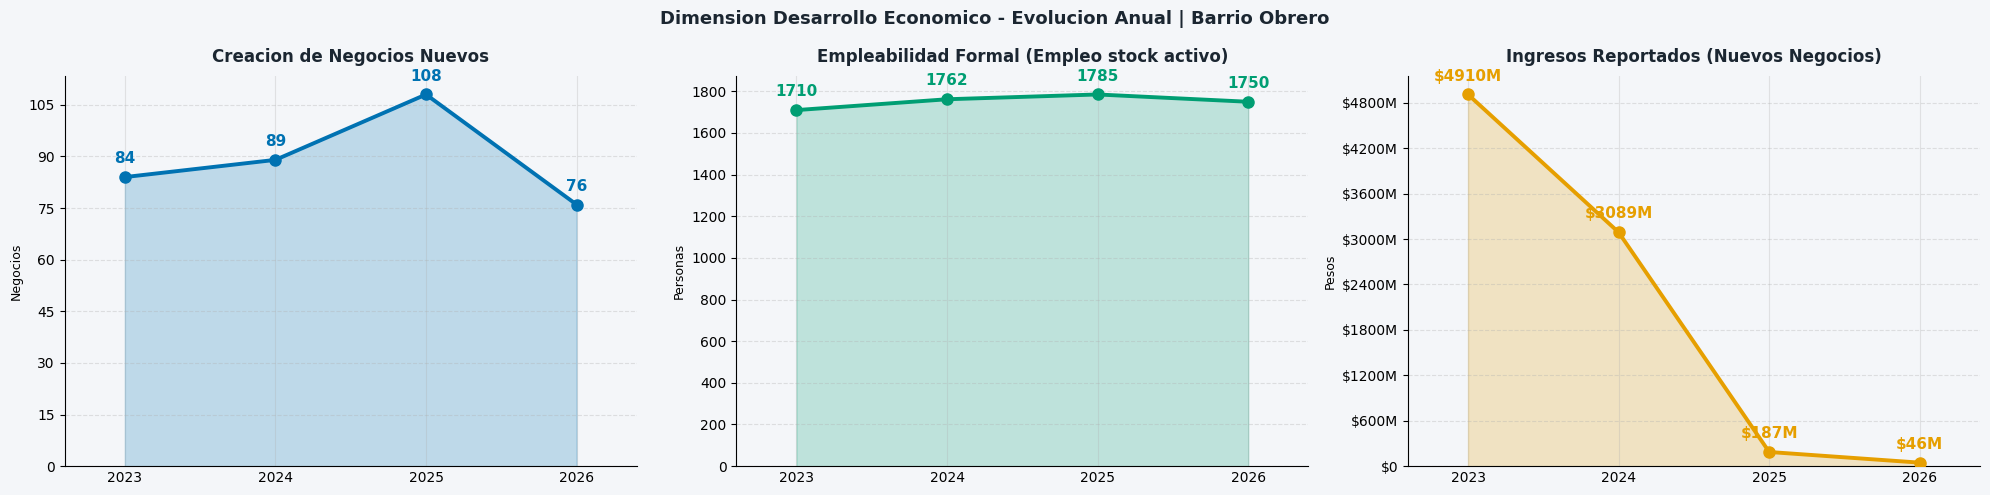

In [164]:
# -- Celda DE-5: evolucion anual Desarrollo Economico
fig, axes = plt.subplots(1, 3, figsize=(20, 5), facecolor=BG)
fig.suptitle('Dimension Desarrollo Economico - Evolucion Anual | Barrio Obrero',
             fontsize=13, fontweight='bold', color='#1B2631')

anos_lbl = [str(a) for a in ANIOS_DE]
x_de     = np.arange(len(ANIOS_DE))

cfg_de = [
    ('negocios_nuevos', 'Creacion de Negocios Nuevos',           OKI_AZUL,    'negocios'),
    ('empleo_personas', 'Empleabilidad Formal (Empleo stock activo)', OKI_VERDE, 'personas'),
    ('ingresos_nuevos', 'Ingresos Reportados (Nuevos Negocios)',  OKI_NARANJA, 'pesos'),
]

# El empleo real viene del STOCK ACTIVO por año (df_de_scores), no del flujo de nuevos.
df_de_plot = df_de_anual.set_index('año').reindex(ANIOS_DE)
_emp_stock = df_de_scores.set_index('año').reindex(ANIOS_DE)['empleo_personas'] \
    if 'df_de_scores' in dir() and 'empleo_personas' in df_de_scores.columns else None
if _emp_stock is not None:
    df_de_plot['empleo_personas'] = _emp_stock.values

for ax, (col, titulo, color, unidad) in zip(axes, cfg_de):
    vals  = df_de_plot[col].values.astype(float)
    valid = ~np.isnan(vals)

    ax.fill_between(x_de, np.where(valid, vals, np.nan), alpha=0.22, color=color)
    ax.plot(x_de, np.where(valid, vals, np.nan),
            color=color, linewidth=2.8, marker='o', markersize=8, zorder=3)

    for i, v in enumerate(vals):
        if not np.isnan(v):
            if col == 'ingresos_nuevos':
                lbl = f'${v/1e6:.0f}M' if v >= 1e6 else f'${v:,.0f}'
            else:
                lbl = str(int(v))
            ax.annotate(lbl, (i, v),
                        textcoords='offset points', xytext=(0, 10),
                        ha='center', fontsize=11, fontweight='bold', color=color)

    ax.set_xticks(x_de)
    ax.set_xticklabels(anos_lbl, fontsize=10)
    ax.set_title(titulo, fontweight='bold', pad=10, color='#1B2631')
    ax.set_ylabel(unidad.capitalize(), fontsize=9)
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=(col != 'ingresos_nuevos')))
    if col == 'ingresos_nuevos':
        ax.yaxis.set_major_formatter(
            plt.FuncFormatter(lambda v, _: f'${v/1e6:.0f}M' if v >= 1e6 else f'${v:,.0f}'))
    ax.set_xlim(-0.4, len(ANIOS_DE) - 0.6)
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    ax.set_facecolor(BG)
    ax.tick_params(axis='x', length=0)

plt.tight_layout()
plt.savefig('itt_obrero_de_evol.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


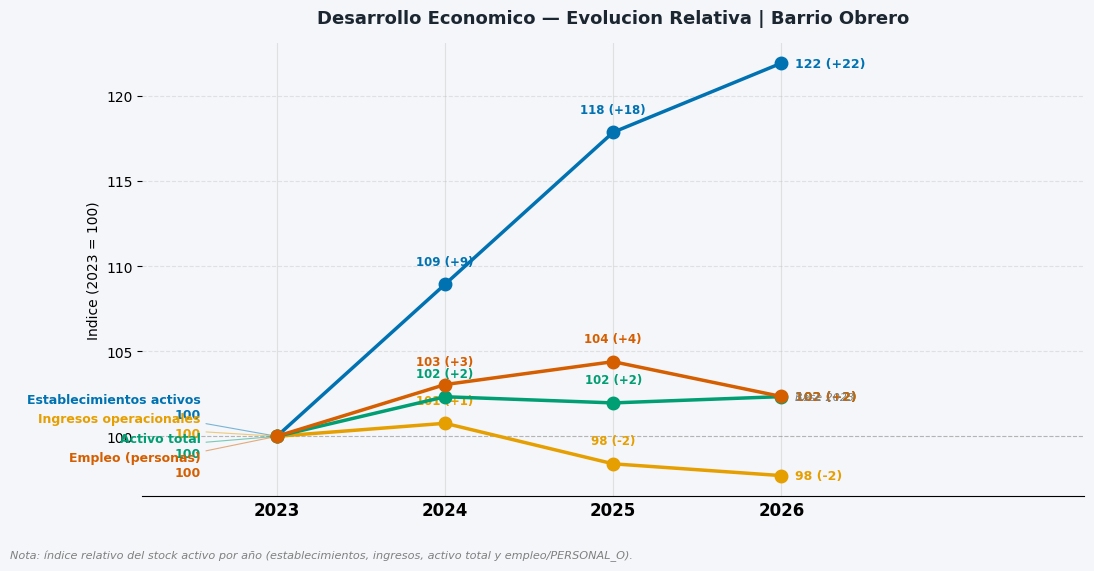

In [165]:
# ── Celda DE-6: slope chart DE — indice base 2023=100 | Barrio Obrero ───────
# Requiere df_de_scores (DE-3) con establecimientos_activos, ingresos_operacionales,
# activo_total; indices relativos al primer año. No hay empleo -> no se grafica.
if 'ANIOS_DE' not in globals():
    ANIOS_DE = [2023, 2024, 2025, 2026]
_sl = df_de_scores.set_index('año').reindex(ANIOS_DE).copy()
df_slope = pd.DataFrame({
    'establecimientos': _sl['establecimientos_activos'].values.astype(float),
    'ingresos':         _sl['ingresos_operacionales'].values.astype(float),
    'activo_total':     _sl['activo_total'].values.astype(float),
    'empleo':           (_sl['empleo_personas'].values.astype(float)
                         if 'empleo_personas' in _sl.columns else np.full(len(ANIOS_DE), np.nan)),
}, index=ANIOS_DE)
indicadores = {
    'establecimientos': ('Establecimientos activos', OKI_AZUL),
    'ingresos':         ('Ingresos operacionales',   OKI_NARANJA),
    'activo_total':     ('Activo total',             OKI_VERDE),
    'empleo':           ('Empleo (personas)',        OKI_BERMELL),
}
x_pos = list(range(len(ANIOS_DE)))
fig, ax = plt.subplots(figsize=(11, 6), facecolor=BG)
ax.set_facecolor(BG)
offsets = [21, 7, -7, -21]
for (col, (label, color)), off in zip(indicadores.items(), offsets):
    vals = df_slope[col].values.astype(float)
    if np.isnan(vals[0]) or vals[0] == 0:
        continue
    idx = (vals / vals[0]) * 100
    ax.plot(x_pos, idx, color=color, linewidth=2.5, marker='o', markersize=9, zorder=3, label=label)
    # etiqueta inicio
    ax.annotate(f'{label}\n100', xy=(0, idx[0]), xytext=(-55, off),
                textcoords='offset points', ha='right', va='center',
                fontsize=9, fontweight='bold', color=color,
                arrowprops=dict(arrowstyle='-', color=color, lw=0.8, alpha=0.5))
    # etiquetas intermedias y final
    for j in range(1, len(idx)):
        if np.isnan(idx[j]):
            continue
        d = idx[j] - 100
        txt = f'{idx[j]:.0f} ({"+"+str(int(round(d))) if d >= 0 else str(int(round(d)))})'
        es_final = (j == len(idx) - 1)
        ax.annotate(txt, xy=(j, idx[j]),
                    xytext=(10, 0) if es_final else (0, 12),
                    textcoords='offset points',
                    ha='left' if es_final else 'center',
                    va='center' if es_final else 'bottom',
                    fontsize=9 if es_final else 8.5, color=color, fontweight='bold')
ax.axhline(100, color='gray', linewidth=0.8, linestyle='--', alpha=0.45)
ax.text(x_pos[-1] + 0.08, 102, f'Base {ANIOS_DE[0]}', ha='left', va='bottom',
        fontsize=8, color='gray', style='italic')
ax.set_xticks(x_pos)
ax.set_xticklabels([str(a) for a in ANIOS_DE], fontsize=12, fontweight='bold')
ax.set_xlim(-0.8, len(ANIOS_DE) - 0.1 + 0.9)
ax.set_ylabel(f'Indice ({ANIOS_DE[0]} = 100)', fontsize=10)
ax.set_title('Desarrollo Economico — Evolucion Relativa | Barrio Obrero',
             fontsize=13, fontweight='bold', color='#1B2631', pad=14)
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.tick_params(axis='x', length=0)
ax.spines[['top', 'right', 'left']].set_visible(False)
fig.text(0.01, 0.01,
         'Nota: índice relativo del stock activo por año (establecimientos, ingresos, activo total y empleo/PERSONAL_O).',
         fontsize=8.1, color='gray', style='italic')
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig('itt_obrero_de_slope.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


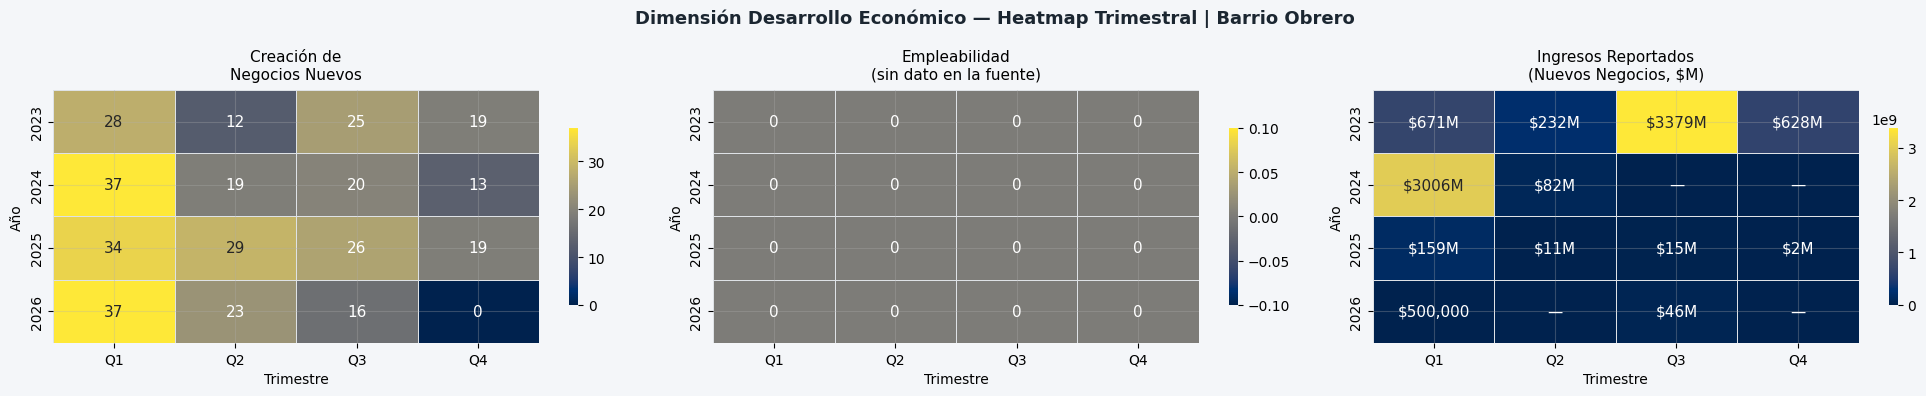

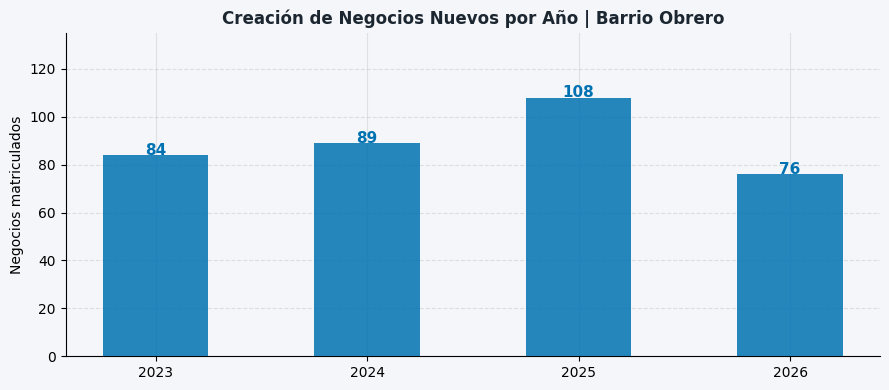

In [166]:
# ── Celda DE-4: heatmap trimestral + evolución anual Desarrollo Económico ─────
fig, axes = plt.subplots(1, 3, figsize=(20, 4), facecolor=BG)
fig.suptitle("Dimensión Desarrollo Económico — Heatmap Trimestral | Barrio Obrero",
             fontsize=13, fontweight="bold", color="#1B2631")

for ax, col, titulo, fmt_fn in [
    (axes[0], "negocios_nuevos", "Creación de\nNegocios Nuevos",
     lambda x: f"{int(x)}"),
    (axes[1], "personal_nuevos", "Empleabilidad\n(sin dato en la fuente)",
     lambda x: f"{int(x)}"),
    (axes[2], "ingresos_nuevos", "Ingresos Reportados\n(Nuevos Negocios, $M)",
    lambda x: f"${x/1e6:.0f}M" if x >= 1e6 else ("—" if x == 0 else f"${x:,.0f}")),
]:
    pivot = df_de_trim.pivot(index="año", columns="trimestre", values=col).fillna(0)
    pivot.columns = ["Q1","Q2","Q3","Q4"]
    annot = pivot.map(fmt_fn)
    sns.heatmap(pivot, annot=annot, fmt="", cmap="cividis",
                linewidths=0.5, linecolor="#DEE2E6", ax=ax,
                annot_kws={"size": 11}, cbar_kws={"shrink": 0.7})
    ax.set_title(titulo, fontsize=11, pad=8)
    ax.set_xlabel("Trimestre"); ax.set_ylabel("Año")

plt.tight_layout()
plt.savefig("itt_obrero_de_heatmap.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()

# ── Evolución anual — negocios nuevos ────────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(9, 4), facecolor=BG)
ax2.set_facecolor(BG)
x_pos = range(len(ANIOS_DE))
bars  = ax2.bar(x_pos, df_de_anual["negocios_nuevos"], color=OKI_AZUL,
                alpha=0.85, width=0.5, zorder=3)
for bar, v in zip(bars, df_de_anual["negocios_nuevos"]):
    ax2.text(bar.get_x()+bar.get_width()/2, v+0.2, str(int(v)),
             ha="center", fontsize=11, fontweight="bold", color=OKI_AZUL)
ax2.set_xticks(list(x_pos))
ax2.set_xticklabels([str(a) for a in ANIOS_DE])
ax2.set_title("Creación de Negocios Nuevos por Año | Barrio Obrero",
              fontsize=12, fontweight="bold", color="#1B2631")
ax2.set_ylabel("Negocios matriculados")
ax2.set_ylim(0, max(df_de_anual["negocios_nuevos"].max() * 1.25, 1))
ax2.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.savefig("itt_obrero_de_evolucion.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


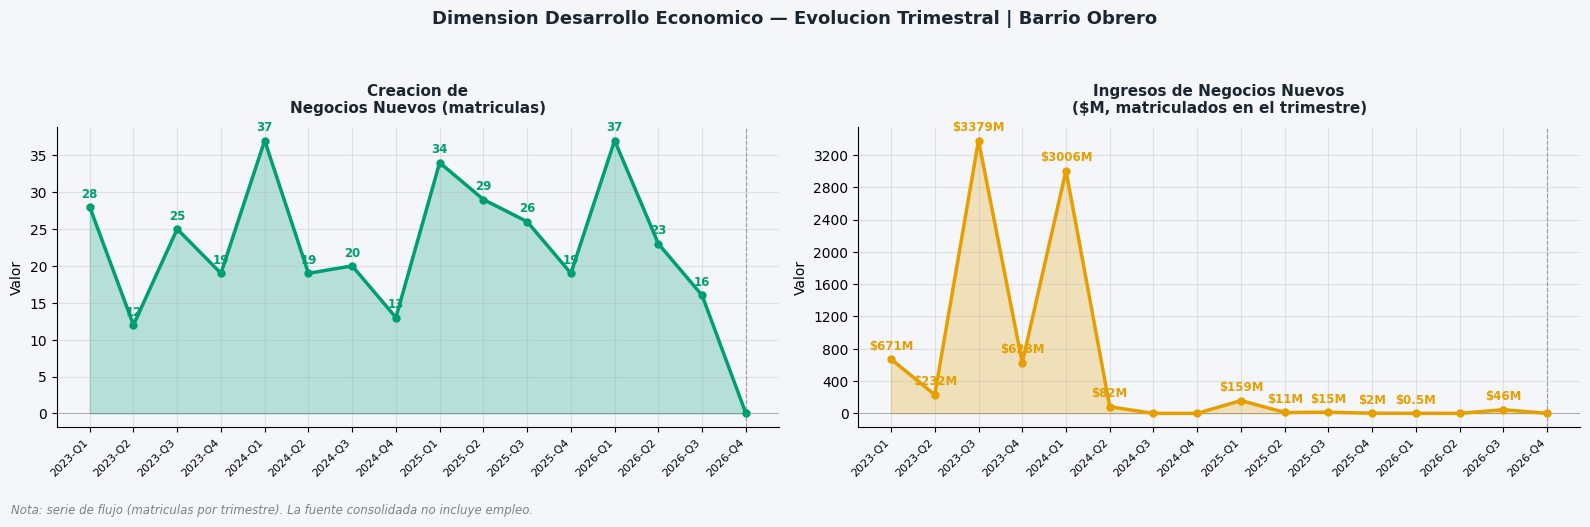

In [167]:
# ── DE: Evolucion Trimestral — matriculas e ingresos | Barrio Obrero ────────
# NO hay empleo en la fuente -> el panel de "personal" se reemplaza por ingresos.
_de_trim = df_de_trim.copy()
_de_trim = _de_trim.sort_values(['año', 'trimestre']).reset_index(drop=True)
_de_trim['ingresos_m'] = _de_trim['ingresos_nuevos'] / 1e6
_periodos = _de_trim['periodo'].tolist()
_x = np.arange(len(_periodos))
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), facecolor=BG)
fig.suptitle(
    'Dimension Desarrollo Economico — Evolucion Trimestral | Barrio Obrero',
    fontsize=13, fontweight='bold', color='#1B2631'
)
cfg_de = [
    (axes[0], 'negocios_nuevos', 'Creacion de\nNegocios Nuevos (matriculas)', OKI_VERDE,  lambda v: f'{int(v)}'),
    (axes[1], 'ingresos_m',      'Ingresos de Negocios Nuevos\n($M, matriculados en el trimestre)', OKI_NARANJA, lambda v: f'${v:.0f}M' if v >= 1 else f'${v:.1f}M'),
]
for ax, col, titulo, color, fmt_fn in cfg_de:
    vals = _de_trim[col].values.astype(float)
    valid = ~pd.isna(vals)
    ax.fill_between(_x, np.where(valid, vals, np.nan), alpha=0.25, color=color)
    ax.plot(_x, np.where(valid, vals, np.nan),
            color=color, linewidth=2.5, marker='o', markersize=5, zorder=3)
    for i, v in enumerate(vals):
        if pd.notna(v) and v > 0:
            ax.annotate(fmt_fn(v), (i, v), textcoords='offset points',
                        xytext=(0, 7), ha='center', fontsize=8.5, fontweight='bold', color=color)
    _validos = [i for i, v in enumerate(vals) if pd.notna(v)]
    if _validos:
        ax.axvline(max(_validos), color=OKI_GRIS, linewidth=0.8, linestyle='--', alpha=0.4)
    ax.set_xticks(_x)
    ax.set_xticklabels(_periodos, rotation=45, ha='right', fontsize=8)
    ax.set_title(titulo, fontsize=11, pad=10, fontweight='bold', color='#1B2631')
    ax.set_ylabel('Valor')
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.axhline(0, color=OKI_GRIS, linewidth=0.5, alpha=0.4)
    ax.set_facecolor(BG)
fig.text(0.01, 0.01,
         'Nota: serie de flujo (matriculas por trimestre). La fuente consolidada no incluye empleo.',
         fontsize=8.5, color='gray', style='italic')
plt.tight_layout(rect=[0, 0.05, 1, 0.93])
plt.savefig('itt_obrero_de_trim.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


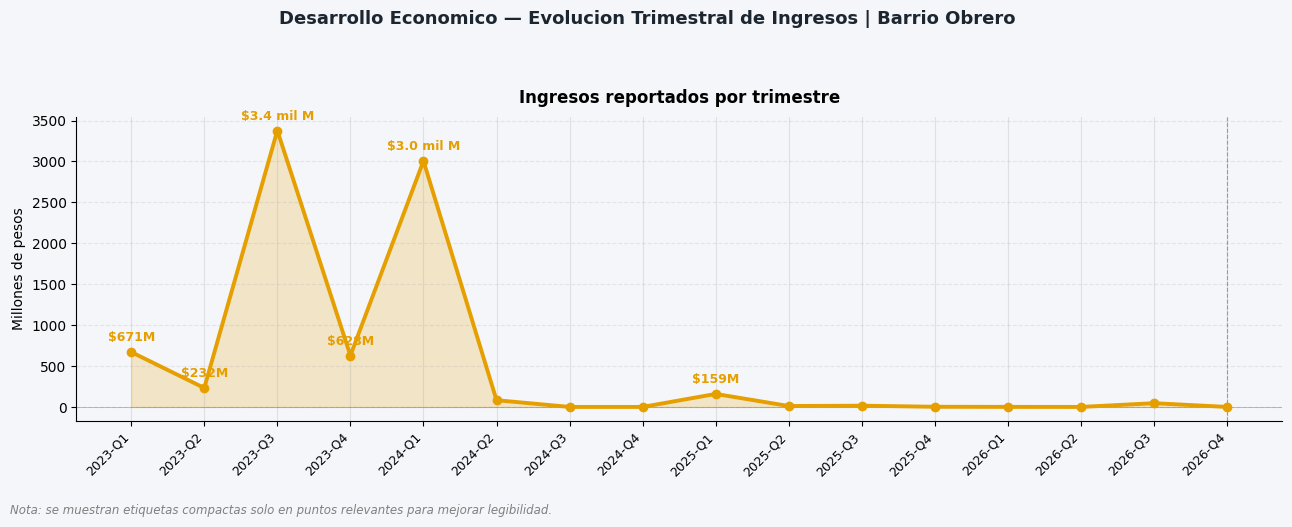

In [168]:
_ing = df_de_trim.copy()
_ing = _ing.sort_values(['año', 'trimestre']).reset_index(drop=True)
_ing['ingresos_m'] = _ing['ingresos_nuevos'] / 1e6

_periodos = _ing['periodo'].tolist()
_x = np.arange(len(_periodos))
_vals = _ing['ingresos_m'].values.astype(float)
_valid = ~pd.isna(_vals)

def fmt_compacto(v):
    if v >= 1000:
        return f'${v/1000:.1f} mil M'
    if v >= 100:
        return f'${v:.0f}M'
    if v >= 10:
        return f'${v:.1f}M'
    if v >= 1:
        return f'${v:.1f}M'
    return f'${v:.1f}M'

fig, ax = plt.subplots(figsize=(13, 5.2), facecolor=BG)
fig.suptitle(
    'Desarrollo Economico — Evolucion Trimestral de Ingresos | Barrio Obrero',
    fontsize=13, fontweight='bold', color='#1B2631'
)

ax.fill_between(_x, np.where(_valid, _vals, np.nan), alpha=0.20, color=OKI_NARANJA)
ax.plot(
    _x, np.where(_valid, _vals, np.nan),
    color=OKI_NARANJA, linewidth=2.8, marker='o', markersize=6, zorder=3
)

for i, v in enumerate(_vals):
    if not pd.notna(v) or v <= 0:
        continue

    es_max = v == np.nanmax(_vals)
    es_relevante = v >= 100
    es_ultimo = i == len(_vals) - 1

    if es_max or es_relevante or es_ultimo:
        ax.annotate(
            fmt_compacto(v), (i, v),
            textcoords='offset points', xytext=(0, 8),
            ha='center', fontsize=9, fontweight='bold', color=OKI_NARANJA
        )

_val73 = [i for i, v in enumerate(_vals) if pd.notna(v)]
if _val73:
    ax.axvline(max(_val73), color=OKI_GRIS, linewidth=0.8, linestyle='--', alpha=0.4)

ax.set_xticks(_x)
ax.set_xticklabels(_periodos, rotation=45, ha='right', fontsize=9)
ax.set_title('Ingresos reportados por trimestre', pad=10, fontweight='bold')
ax.set_ylabel('Millones de pesos')
ax.axhline(0, color=OKI_GRIS, linewidth=0.5, alpha=0.4)
ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.set_facecolor(BG)

fig.text(
    0.01, 0.01,
    'Nota: se muestran etiquetas compactas solo en puntos relevantes para mejorar legibilidad.',
    fontsize=8.5, color='gray', style='italic'
)

plt.tight_layout(rect=[0, 0.05, 1, 0.92])
plt.savefig('itt_obrero_ingresos_trim.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


In [169]:
# ── Celda DE-3B: verificacion del score oficial de Actividad Economica ──────
# Requiere df_de_scores (DE-3) y base ya actualizado.
print("Scores Desarrollo Economico por año — verificacion oficial ITT:")
cols_sc = [
    'año', 'tipo_dato', 'establecimientos_activos', 'ingresos_operacionales',
    'activo_total', 'negocios_con_ingreso', 'score_establecimientos',
    'score_ingresos', 'score_activo_total', 'score_des_eco'
]
print(df_de_scores[cols_sc].round(2).to_string(index=False))
print()
print("ITT actualizado — 5 dimensiones:")
cols_b = [
    'año', 'score_seguridad', 'score_movilidad', 'score_des_social',
    'score_entorno_u', 'score_des_eco', 'ITT', 'nivel'
]
print(base[cols_b].round(1).to_string(index=False))


Scores Desarrollo Economico por año — verificacion oficial ITT:
 año                       tipo_dato  establecimientos_activos  ingresos_operacionales  activo_total  negocios_con_ingreso  score_establecimientos  score_ingresos  score_activo_total  score_des_eco
2023 Real (stock activo consolidado)                     862.0            1.734567e+11  1.447477e+11                 218.0                   82.02            75.4                0.00          60.18
2024 Real (stock activo consolidado)                     939.0            1.747839e+11  1.481128e+11                 219.0                   89.34           100.0               99.70          93.72
2025 Real (stock activo consolidado)                    1016.0            1.706523e+11  1.475886e+11                 222.0                   96.67            22.8               84.32          72.69
2026 Real (stock activo consolidado)                    1051.0            1.694511e+11  1.481229e+11                 218.0                  100.

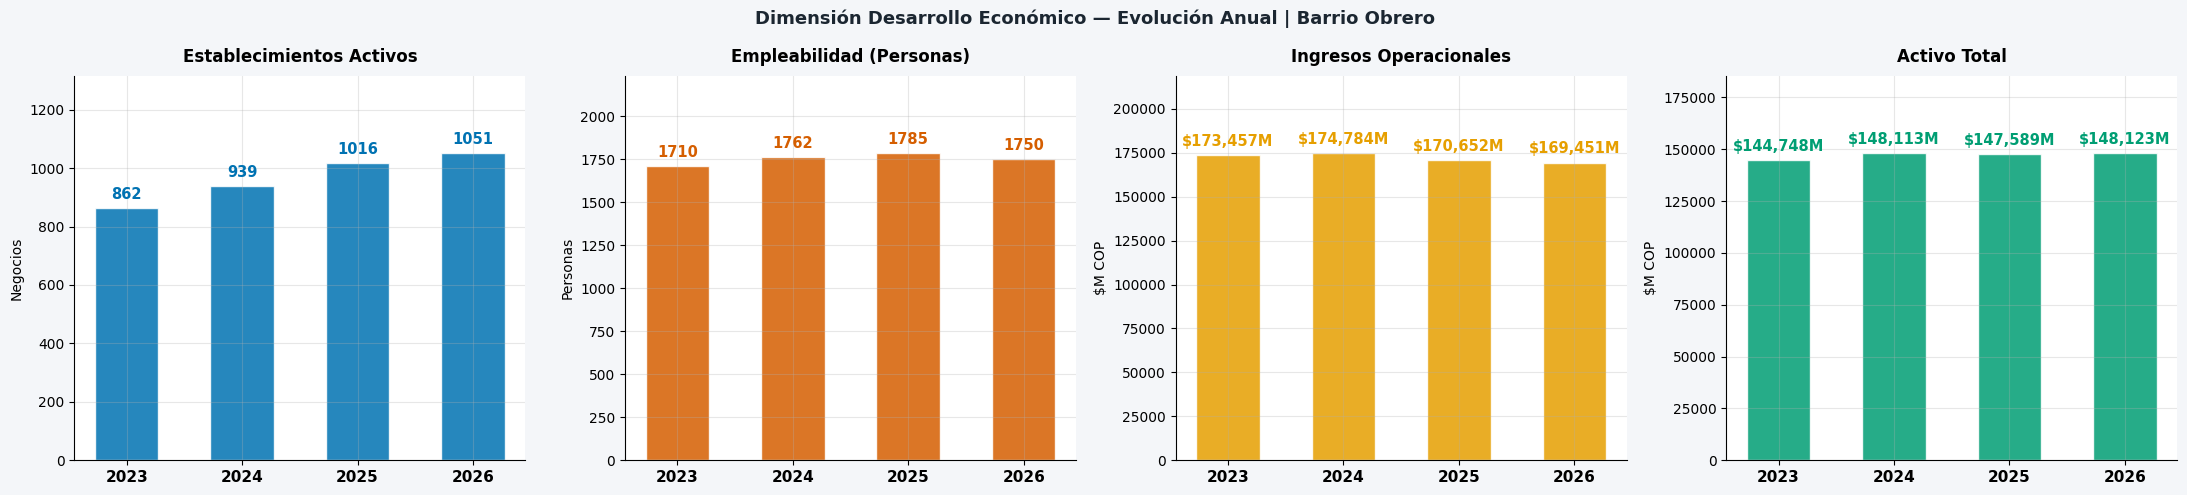

✓ DE evolución anual (stock activo) generada


In [170]:
# ── DE: Evolución Anual — barras (stock activo consolidado) ──────────────────
fig, axes = plt.subplots(1, 4, figsize=(22, 5), facecolor=BG)
fig.suptitle('Dimensión Desarrollo Económico — Evolución Anual | Barrio Obrero',
             fontsize=13, fontweight='bold', color='#1B2631')
_años = [2023, 2024, 2025, 2026]
df_e  = df_de_scores.set_index('año').reindex(_años)
x     = np.arange(len(_años))
W     = 0.55
cfg = [
    ('establecimientos_activos', 'Establecimientos Activos', OKI_AZUL,    'Negocios', None),
    ('empleo_personas',          'Empleabilidad (Personas)', OKI_BERMELL, 'Personas', None),
    ('ingresos_operacionales',   'Ingresos Operacionales',   OKI_NARANJA, 'Pesos',    1e6),
    ('activo_total',             'Activo Total',             OKI_VERDE,   'Pesos',    1e6),
]
for ax, (col, titulo, color, ylabel, divisor) in zip(axes, cfg):
    ax.set_facecolor('white')
    vals = df_e[col].values.astype(float) if col in df_e.columns else np.zeros(len(_años))
    display_vals = vals / divisor if divisor else vals
    bars = ax.bar(x, np.nan_to_num(display_vals, nan=0.0), color=color, alpha=0.85,
                  edgecolor='white', width=W)
    _mx = np.nanmax(display_vals) if np.any(~np.isnan(display_vals)) else 1
    for bar, v in zip(bars, display_vals):
        if not np.isnan(v) and v > 0:
            if divisor:
                label = f'${v/1e6:.0f} mil M' if v >= 1e6 else f'${v:,.0f}M'
            else:
                label = f'{v:.0f}'
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + _mx*0.02,
                    label, ha='center', va='bottom', fontsize=10.5, fontweight='bold', color=color)
    ax.set_xticks(x); ax.set_xticklabels([str(a) for a in _años], fontsize=11, fontweight='bold')
    ax.set_title(titulo, fontweight='bold', pad=10)
    ax.set_ylabel('$M COP' if divisor else ylabel)
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_ylim(0, _mx * 1.25 if _mx > 0 else 1)
plt.tight_layout()
_img_dir = IMG_DIR if 'IMG_DIR' in dir() else Path('.')
plt.savefig(_img_dir / 'itt_obrero_de_evolucion_anual.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('✓ DE evolución anual (stock activo) generada')


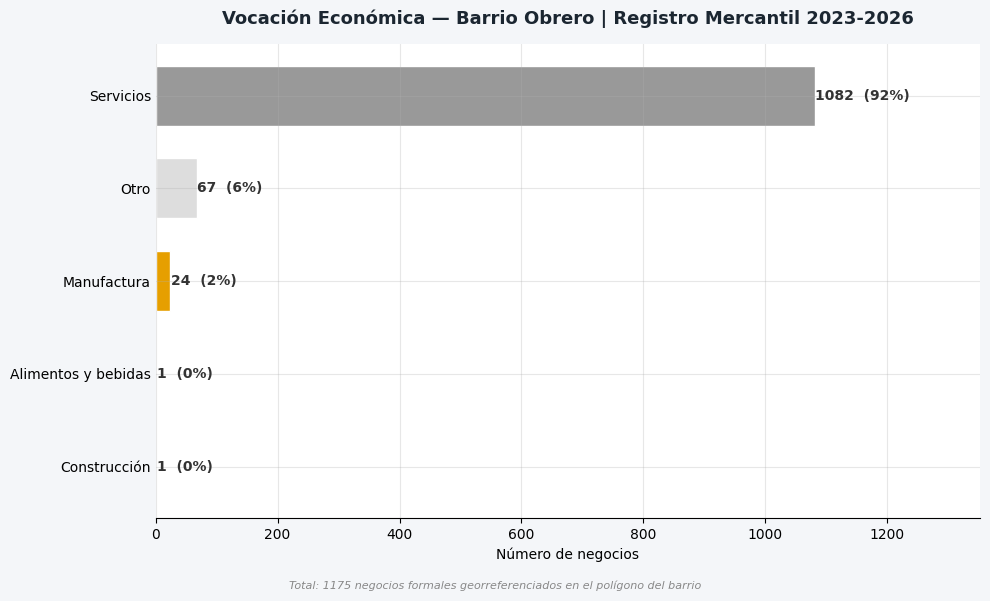

✓ Vocación económica CIIU generada


In [171]:
# ── CIIU — Vocación económica | Barrio Obrero (fuente consolidada) ───────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Mapeo CIIU 2 dígitos → macro-sector
SECTOR_MAP = {
    '45': 'Comercio automotriz', '46': 'Comercio al por mayor', '47': 'Comercio al por menor',
    '56': 'Alimentos y bebidas', '55': 'Alimentos y bebidas',
    '10': 'Manufactura', '13': 'Manufactura', '15': 'Manufactura', '16': 'Manufactura',
    '22': 'Manufactura', '24': 'Manufactura', '25': 'Manufactura', '31': 'Manufactura',
    '29': 'Mantenimiento y reparación', '33': 'Mantenimiento y reparación',
    '42': 'Construcción', '43': 'Construcción',
    '38': 'Servicios', '68': 'Servicios', '70': 'Servicios', '73': 'Servicios',
    '74': 'Servicios', '85': 'Servicios', '86': 'Servicios', '90': 'Servicios',
    '91': 'Servicios', '94': 'Servicios', '96': 'Servicios',
}
SECTOR_COLORS = {
    'Comercio al por menor': '#0072B2', 'Comercio automotriz': '#56B4E9',
    'Comercio al por mayor': '#009E73', 'Manufactura': '#E69F00',
    'Alimentos y bebidas': '#D55E00', 'Mantenimiento y reparación': '#CC79A7',
    'Construcción': '#8B6914', 'Servicios': '#999999', 'Otro': '#DDDDDD',
}
# codigo_ciiu viene como float en df_de -> a entero -> string de 2 dígitos iniciales
def _ciiu_sector(c):
    if pd.isna(c):
        return 'Otro'
    s = str(int(c))
    sec2 = s[:2] if len(s) >= 2 else s.zfill(2)
    return SECTOR_MAP.get(sec2, 'Otro')
df_ciiu = pd.DataFrame({'sector': df_de['codigo_ciiu'].apply(_ciiu_sector)})
dist_total = df_ciiu['sector'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, 6), facecolor=BG)
ax.set_facecolor('white')
colors_h = [SECTOR_COLORS.get(s, '#CCC') for s in dist_total.index]
bars = ax.barh(dist_total.index, dist_total.values, color=colors_h, edgecolor='white', height=0.65)
for bar, val in zip(bars, dist_total.values):
    pct = val / len(df_ciiu) * 100
    ax.text(val + 0.3, bar.get_y() + bar.get_height()/2, f'{val}  ({pct:.0f}%)',
            va='center', fontsize=10, fontweight='bold', color='#333333')
ax.set_title('Vocación Económica — Barrio Obrero | Registro Mercantil 2023-2026',
             fontsize=13, fontweight='bold', color='#1B2631', pad=14)
ax.set_xlabel('Número de negocios')
ax.set_xlim(0, dist_total.max() * 1.25)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)
fig.text(0.5, 0.01,
         f'Total: {len(df_ciiu)} negocios formales georreferenciados en el polígono del barrio',
         ha='center', fontsize=8, color='#888888', style='italic')
plt.tight_layout(rect=[0, 0.03, 1, 1])
_img_dir = IMG_DIR if 'IMG_DIR' in dir() else Path('.')
plt.savefig(_img_dir / 'itt_obrero_ciiu_vocacion.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('✓ Vocación económica CIIU generada')


In [172]:
print(type(base))
print(base.dtypes)
print(base[['año','score_educ_des','score_des_eco','ITT']].to_string())

<class 'pandas.core.frame.DataFrame'>
año                       int64
homicidios                int64
hurtos                    int64
siniestralidad            int64
lesionados                int64
mortales                  int64
vif                       int64
rinas                     int64
score_homicidios        float64
score_hurtos            float64
score_siniestralidad    float64
score_lesionados        float64
score_mortales          float64
score_vif               float64
score_rinas             float64
spa                       int64
score_spa               float64
score_seguridad         float64
score_movilidad         float64
score_cohesion          float64
score_entorno_u         float64
score_educ_des          float64
score_des_social        float64
score_des_eco           float64
ITT                     float64
nivel                    object
score_matricula         float64
score_desercion         float64
dtype: object
    año  score_educ_des  score_des_eco        ITT
0 

## Celda 15 — ITT Global y composicion por dimension


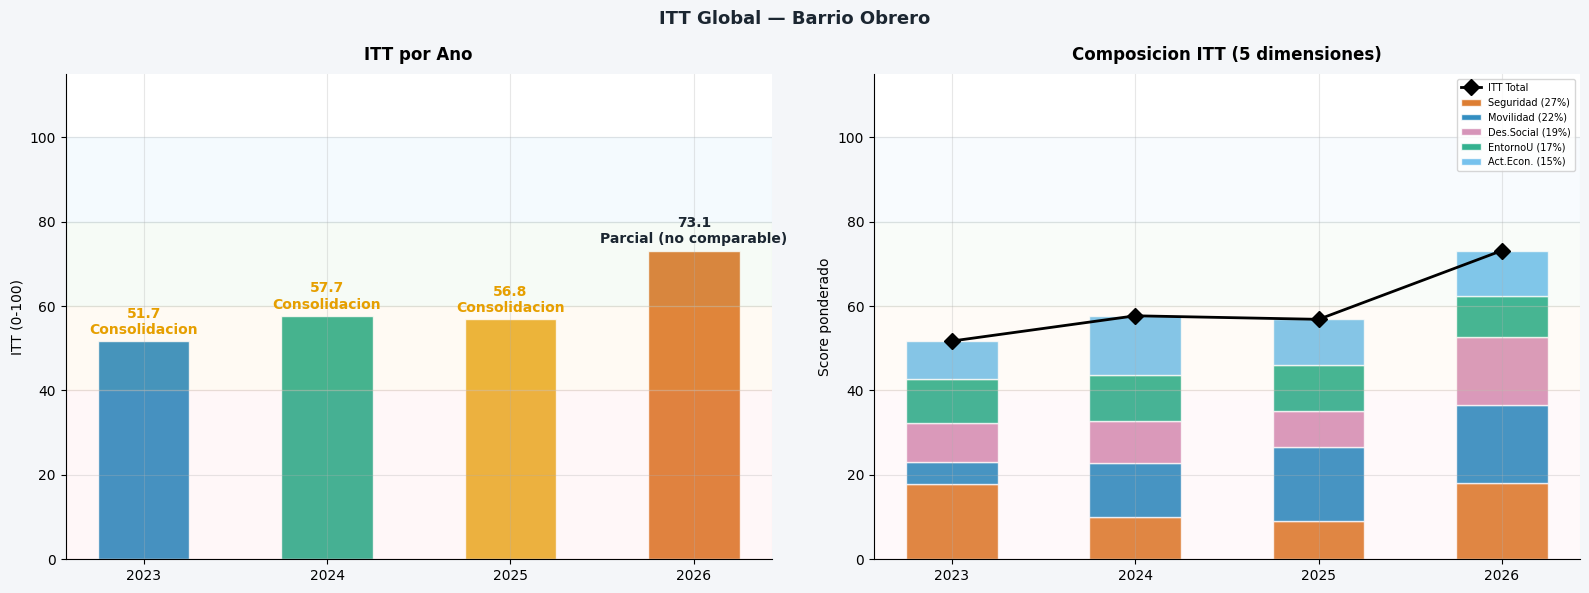

In [173]:
# ── ITT Global — Barrio Obrero ────────────────────────────────────────────────
if not isinstance(base, pd.DataFrame):
    raise RuntimeError(
        f"'base' es {type(base).__name__}. "
        "Alguna celda entre Normalizacion y esta sobreescribio la variable. "
        "Re-ejecuta SOLO la celda de Normalizacion+ITT y luego EU-2, ED-3 y DE-3."
    )

COLORES_ITT  = [OKI_AZUL, OKI_VERDE, OKI_NARANJA, OKI_BERMELL][:len(ANIOS)]
band_configs = [(0,40,'#FFCDD2','Activacion'),(40,60,'#FFE0B2','Consolidacion'),
                (60,80,'#C8E6C9','Transformacion'),(80,100,'#BBDEFB','Escala')]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor=BG)
fig.suptitle('ITT Global — Barrio Obrero', fontsize=13, fontweight='bold', color='#1B2631')

# Panel 1: barras ITT por año
ax1 = axes[0]
bars = ax1.bar(ANIOS, base['ITT'], color=COLORES_ITT, alpha=0.85,
               edgecolor='white', width=0.5)
for bar, val, nivel in zip(bars, base['ITT'], base['nivel']):
    ax1.text(bar.get_x()+bar.get_width()/2, val+1,
             f'{val:.1f}\n{nivel}', ha='center', va='bottom',
             fontsize=10, fontweight='bold',
             color=NIVEL_COLORS.get(nivel,'#1B2631'))
for y0,y1,c,l in band_configs:
    ax1.axhspan(y0, y1, alpha=0.15, color=c)
ax1.set_title('ITT por Ano', fontweight='bold', pad=10)
ax1.set_ylim(0, 115); ax1.set_ylabel('ITT (0-100)'); ax1.set_xticks(ANIOS)

# Panel 2: composicion 5 dimensiones
ax2 = axes[1]
dims   = ['score_seguridad','score_movilidad','score_des_social',
          'score_entorno_u','score_des_eco']
lbls   = ['Seguridad','Movilidad','Des.Social','EntornoU','Act.Econ.']
pesos  = [PESOS['Seguridad'],PESOS['Movilidad'],PESOS['DesSocial'],
          PESOS['EntornoU'],PESOS['DesEco']]
cols   = [OKI_BERMELL, OKI_AZUL, OKI_MORADO, OKI_VERDE, OKI_AZUL_C]

bottom = np.zeros(len(ANIOS))
for dim, lbl, peso, col in zip(dims, lbls, pesos, cols):
    if dim in base.columns:
        vals = base[dim].fillna(0).values * peso
        ax2.bar(ANIOS, vals, bottom=bottom,
                label=f'{lbl} ({peso:.0%})', color=col, alpha=0.8,
                edgecolor='white', width=0.5)
        bottom += vals

ax2.plot(ANIOS, base['ITT'], 'D-', color='black', linewidth=2,
         markersize=8, label='ITT Total', zorder=5)
for y0,y1,c,l in band_configs:
    ax2.axhspan(y0, y1, alpha=0.1, color=c)
ax2.set_title('Composicion ITT (5 dimensiones)', fontweight='bold', pad=10)
ax2.set_ylim(0, 115); ax2.set_ylabel('Score ponderado'); ax2.set_xticks(ANIOS)
ax2.legend(loc='upper right', fontsize=7)

plt.tight_layout()
plt.savefig('itt_obrero_global.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


## Celda 16 — Radar ITT: 5 dimensiones


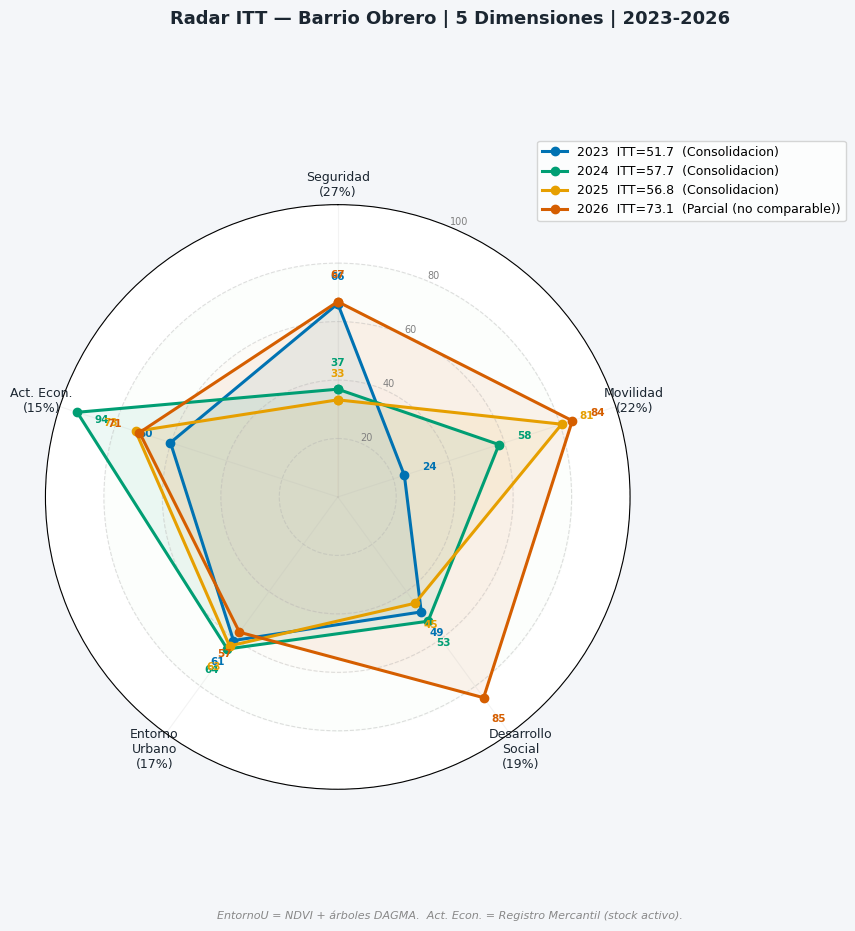

In [174]:
# ── Celda 16 — Radar ITT actualizado: 5 dimensiones | 2023-2026 ──────────────
DIMS_LBL = [
    'Seguridad\n(27%)', 'Movilidad\n(22%)', 'Desarrollo\nSocial\n(19%)',
    'Entorno\nUrbano\n(17%)', 'Act. Econ.\n(15%)'
]
DIMS_COL = ['score_seguridad','score_movilidad','score_des_social',
            'score_entorno_u','score_des_eco']
N_DIMS = len(DIMS_LBL)
angles = [i / N_DIMS * 2 * np.pi for i in range(N_DIMS)]
angles += angles[:1]   # cerrar polígono

# Okabe-Ito: 4 colores para 4 años
COLORES_R = {2023: OKI_AZUL, 2024: OKI_VERDE, 2025: OKI_NARANJA, 2026: OKI_BERMELL}

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True), facecolor=BG)
ax.set_facecolor('white')
fig.suptitle('Radar ITT — Barrio Obrero | 5 Dimensiones | 2023-2026',
             fontsize=13, fontweight='bold', color='#1B2631')

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(DIMS_LBL, fontsize=9, color='#1B2631')
ax.set_ylim(0, 100)
ax.set_yticks([20, 40, 60, 80, 100])
ax.set_yticklabels(['20', '40', '60', '80', '100'], fontsize=7, color='gray')
ax.yaxis.grid(True, linestyle='--', alpha=0.4)
ax.xaxis.grid(True, linestyle='-', alpha=0.15)

# Bandas de nivel (fondo)
for y, c in [(40,'#FFCDD2'), (60,'#FFE0B2'), (80,'#C8E6C9')]:
    ax.fill_between(np.linspace(0, 2*np.pi, 200), 0, y, alpha=0.04, color=c)

for año in ANIOS:
    row   = base[base['año'] == año].iloc[0]
    vals  = [row[c] for c in DIMS_COL]
    vals_c = vals + [vals[0]]
    color = COLORES_R[año]
    ls    = '-'

    ax.plot(angles, vals_c, linestyle=ls, marker='o', color=color,
            linewidth=2.2, markersize=6, zorder=3,
            label=f'{año}  ITT={row["ITT"]:.1f}  ({row["nivel"]})')
    ax.fill(angles, vals_c, alpha=0.07, color=color)

    # Valor en cada vértice
    for ang, val in zip(angles[:-1], vals):
        offset = 9 if val < 90 else -9
        ax.text(ang, val + offset, f'{val:.0f}',
                ha='center', va='center', fontsize=7.5,
                color=color, fontweight='bold')

ax.legend(loc='upper right', bbox_to_anchor=(1.38, 1.12), fontsize=9, frameon=True)

fig.text(0.5, -0.03,
    'EntornoU = NDVI + árboles DAGMA.  Act. Econ. = Registro Mercantil (stock activo).',
    ha='center', fontsize=8, color='#888888', style='italic')

plt.tight_layout()
plt.savefig('itt_obrero_radar.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()



## Evolución Temporal ITT Global

Serie trimestral construida desde `corr_trim` con refs ajustados a trimestre (annual / 4).
Entorno Urbano y Educación son anuales → línea plana dentro de cada año por diseño.


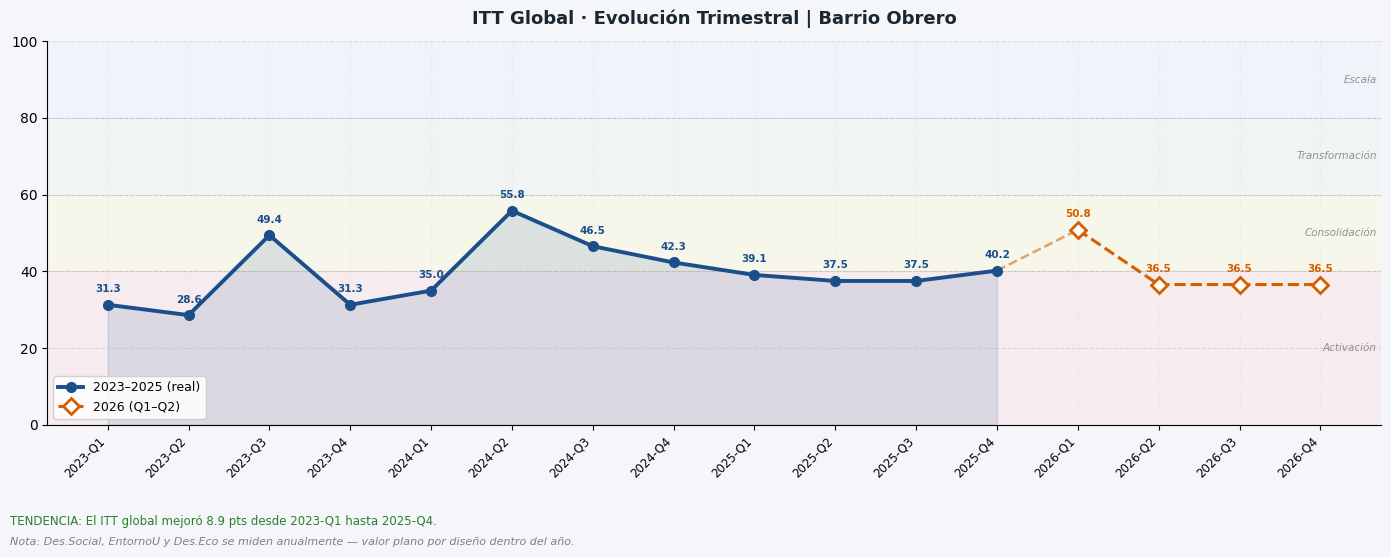

In [175]:
# ── Evolución Trimestral ITT Global — Barrio Obrero (5 dimensiones) ───────────
REFS_Q = {
    'homicidios':     (0,     1.25,  True),
    'hurtos':         (2.5,  15.0,   True),
    'siniestralidad': (0.25,  3.75,  True),
    'lesionados':     (0.25,  3.0,   True),
    'mortales':       (0,     0.75,  True),
    'vif':            (0.25,  3.75,  True),
    'rinas':          (0,     2.5,   True),
}

rows_q = []
for _, r in corr_trim.iterrows():
    anio = int(r['año'])
    trim = int(r['trimestre'])

    def qs(col):
        v = r[col]
        if pd.isna(v): return np.nan
        rmin, rmax, inv = REFS_Q[col]
        return score_ref(v, rmin, rmax, inv)

    seg_vals = [x for x in [qs('homicidios'), qs('hurtos')] if not pd.isna(x)]
    mov_vals = [x for x in [qs('siniestralidad'), qs('lesionados'), qs('mortales')] if not pd.isna(x)]
    sc_seg = np.mean(seg_vals) if seg_vals else np.nan
    sc_mov = np.mean(mov_vals) if mov_vals else np.nan

    brow   = base[base['año'] == anio]
    sc_ent = float(brow['score_entorno_u'].iloc[0]) if not brow.empty else np.nan
    sc_soc = float(brow['score_des_social'].iloc[0]) if not brow.empty else np.nan
    sc_de  = float(brow['score_des_eco'].iloc[0])   if not brow.empty else np.nan

    itt_q = (
        PESOS['Seguridad'] * (sc_seg if not pd.isna(sc_seg) else 0) +
        PESOS['Movilidad'] * (sc_mov if not pd.isna(sc_mov) else 0) +
        PESOS['DesSocial'] * (sc_soc if not pd.isna(sc_soc) else 0) +
        PESOS['EntornoU']  * (sc_ent if not pd.isna(sc_ent) else 0) +
        PESOS['DesEco']    * (sc_de  if not pd.isna(sc_de)  else 0)
    )
    rows_q.append({
        'periodo': r['periodo'], 'año': anio, 'trimestre': trim,
        'ITT': itt_q, 'parcial': anio == 2026   # ← bandera nueva
    })

df_evol = pd.DataFrame(rows_q)

# ── Figura ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5), facecolor=BG)
ax.set_facecolor(BG)

x_idx    = list(range(len(df_evol)))
n_per    = len(df_evol)
itt_vals = df_evol['ITT'].values

BANDAS = [
    (0,  40,  '#FFCDD2', 'Activación'),
    (40, 60,  '#FFF9C4', 'Consolidación'),
    (60, 80,  '#E8F5E9', 'Transformación'),
    (80, 100, '#E3F2FD', 'Escala'),
]
for y0, y1, color, lbl in BANDAS:
    ax.axhspan(y0, y1, alpha=0.25, color=color, zorder=0)
    ax.text(n_per - 0.3, (y0 + y1) / 2, lbl,
            fontsize=7.5, color='gray', ha='right', va='center',
            style='italic', alpha=0.85)

for y in [40, 60, 80]:
    ax.axhline(y, color='gray', linewidth=0.6, linestyle=':', alpha=0.5)

# ── Serie histórica 2023-2025 ─────────────────────────────────────────────────
mask_hist = df_evol['parcial'] == False
mask_2026 = df_evol['parcial'] == True
x_hist    = [i for i, m in enumerate(mask_hist) if m]
x_2026    = [i for i, m in enumerate(mask_2026) if m]
v_hist    = df_evol.loc[mask_hist, 'ITT'].values
v_2026    = df_evol.loc[mask_2026, 'ITT'].values

ax.plot(x_hist, v_hist, '-o', linewidth=2.8, color='#1B4F8A',
        markersize=7, zorder=5, label='2023–2025 (real)')
ax.fill_between(x_hist, 0, v_hist, alpha=0.12, color='#1B4F8A')

# ── Serie 2026 parcial ────────────────────────────────────────────────────────
if len(x_2026) > 0:
    ax.plot([x_hist[-1], x_2026[0]], [v_hist[-1], v_2026[0]],
            color='#D55E00', linewidth=1.8, linestyle='--', alpha=0.55, zorder=4)
    ax.plot(x_2026, v_2026, '--D', linewidth=2.2, color='#D55E00',
            markersize=8, markerfacecolor='white', markeredgewidth=2,
            zorder=5, label='2026 (Q1–Q2)')

# ── Anotaciones de valor ──────────────────────────────────────────────────────
for xi, val, es_parc in zip(x_idx, itt_vals, df_evol['parcial']):
    c_ann  = '#D55E00' if es_parc else '#1B4F8A'
    sufijo = ''
    ax.annotate(f'{val:.1f}{sufijo}', xy=(xi, val), xytext=(0, 9),
                textcoords='offset points', ha='center', fontsize=7.5,
                color=c_ann, fontweight='bold')

ax.legend(fontsize=9, loc='lower left', framealpha=0.85)
ax.set_xticks(x_idx)
ax.set_xticklabels(df_evol['periodo'].tolist(), rotation=45, ha='right', fontsize=8.5)
ax.set_ylim(0, 100)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.grid(axis='y', linestyle='--', alpha=0.35)
ax.grid(axis='x', linestyle=':', alpha=0.15)
ax.set_title('ITT Global · Evolución Trimestral | Barrio Obrero',
             fontsize=13, fontweight='bold', color='#1B2631', pad=12)

val_ini = df_evol[df_evol['año'] == 2023].iloc[0]['ITT']
row_ult = df_evol[(df_evol['año'] == 2025) & (df_evol['trimestre'] == 4)]
val_fin = row_ult.iloc[0]['ITT'] if not row_ult.empty else v_hist[-1]
delta   = val_fin - val_ini
dir_txt = 'mejoró' if delta > 0 else 'retrocedió'
delta_c = '#2E7D32' if delta > 0 else '#C62828'

fig.text(0.01, -0.06,
         f'TENDENCIA: El ITT global {dir_txt} {abs(delta):.1f} pts desde 2023-Q1 hasta 2025-Q4.',
         fontsize=8.5, color=delta_c, transform=fig.transFigure)
fig.text(0.01, -0.10,
         'Nota: Des.Social, EntornoU y Des.Eco se miden anualmente — valor plano por diseño dentro del año.',
         fontsize=8, color='gray', style='italic', transform=fig.transFigure)

plt.tight_layout()
plt.savefig('itt_obrero_evolucion_global.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


Seg 2026: 66.8*  |  Mov 2026: 84.4*  |  DS 2026: 84.9*


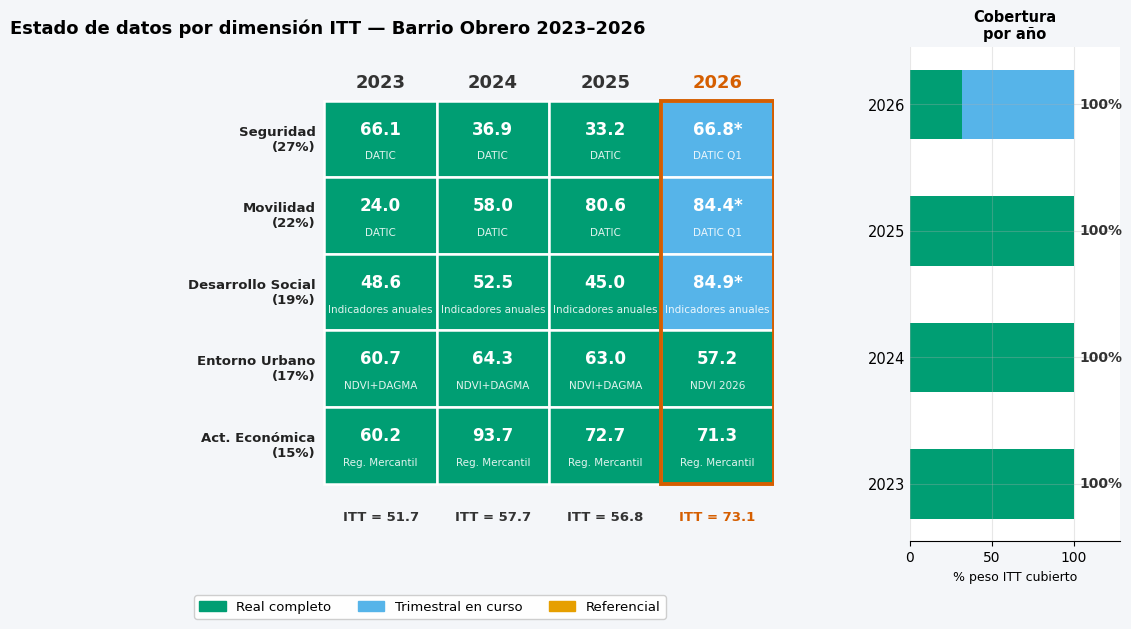

Guardado en: /content/itt_cobertura_datos_2026.png


In [176]:
# ══════════════════════════════════════════════════════════════════════════════
# Celda: Estado de datos 2023–2026 por dimensión ITT
# ══════════════════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import numpy as np
from pathlib import Path

OKI_VERDE   = '#009E73'
OKI_AZUL_C  = '#56B4E9'
OKI_NARANJA = '#E69F00'

# ── Scores parciales 2026 desde corr_trim ────────────────────────────────────
def _score_parcial(col, src):
    try:
        sub = base[base['año'] == 2026][col].dropna()
        if len(sub) == 0:
            return '—', src
        return f'{float(sub.iloc[0]):.1f}*', src
    except Exception:
        return '—', src

seg_val, seg_src = _score_parcial('score_seguridad', 'DATIC Q1')
mov_val, mov_src = _score_parcial('score_movilidad', 'DATIC Q1')
soc_val, soc_src = _score_parcial('score_des_social', 'Indicadores anuales')
print(f"Seg 2026: {seg_val}  |  Mov 2026: {mov_val}  |  DS 2026: {soc_val}")

# ── Definición ────────────────────────────────────────────────────────────────
DIMS_INFO = [
    ('Seguridad',          '27%', 0.27),
    ('Movilidad',          '22%', 0.22),
    ('Desarrollo Social',  '19%', 0.19),
    ('Entorno Urbano',     '17%', 0.17),
    ('Act. Económica',     '15%', 0.15),
]
ANIOS = [2023, 2024, 2025, 2026]

# TABLA[dim][año] = (estado, score_txt, fuente_txt)
# estado: 3=Real completo  2=Parcial (en curso)  1=Provisional
def _score_fmt(col, anio):
    brow = base[base['año'] == anio]
    if brow.empty or col not in brow.columns or pd.isna(brow[col].iloc[0]):
        return '—'
    return f"{float(brow[col].iloc[0]):.1f}"

TABLA = [
    # Seguridad
    [(3,_score_fmt('score_seguridad',2023),'DATIC'),(3,_score_fmt('score_seguridad',2024),'DATIC'),(3,_score_fmt('score_seguridad',2025),'DATIC'),(2, seg_val, seg_src)],
    # Movilidad
    [(3,_score_fmt('score_movilidad',2023),'DATIC'),(3,_score_fmt('score_movilidad',2024),'DATIC'),(3,_score_fmt('score_movilidad',2025),'DATIC'),(2, mov_val, mov_src)],
    # Desarrollo Social
    [(3,_score_fmt('score_des_social',2023),'Indicadores anuales'),(3,_score_fmt('score_des_social',2024),'Indicadores anuales'),(3,_score_fmt('score_des_social',2025),'Indicadores anuales'),(2, soc_val, soc_src)],
    # Entorno Urbano
    [(3,_score_fmt('score_entorno_u',2023),'NDVI+DAGMA'),(3,_score_fmt('score_entorno_u',2024),'NDVI+DAGMA'),(3,_score_fmt('score_entorno_u',2025),'NDVI+DAGMA'),(3,_score_fmt('score_entorno_u',2026),'NDVI 2026')],
    # Actividad Económica
    [(3,_score_fmt('score_des_eco',2023),'Reg. Mercantil'),(3,_score_fmt('score_des_eco',2024),'Reg. Mercantil'),(3,_score_fmt('score_des_eco',2025),'Reg. Mercantil'),(3,_score_fmt('score_des_eco',2026),'Reg. Mercantil')],
]
ITT_ANUAL = {
    a: (f"{float(base.loc[base['año'] == a, 'ITT'].iloc[0]):.1f}" if (not base[base['año'] == a].empty and not pd.isna(base.loc[base['año'] == a, 'ITT'].iloc[0])) else None)
    for a in ANIOS
}

C_MAP = {3: OKI_VERDE, 2: OKI_AZUL_C, 1: OKI_NARANJA}
NDIM = len(DIMS_INFO)
NANI = len(ANIOS)

fig = plt.figure(figsize=(15, 6.5))
gs  = gridspec.GridSpec(1, 2, width_ratios=[4, 1.1], wspace=0.28,
                         left=0.22, right=0.96, top=0.90, bottom=0.14)
ax  = fig.add_subplot(gs[0])
axb = fig.add_subplot(gs[1])

# ── Celdas del grid ───────────────────────────────────────────────────────────
for i in range(NDIM):
    row_y = NDIM - 1 - i
    for j, anio in enumerate(ANIOS):
        estado, score, fuente = TABLA[i][j]
        ax.add_patch(plt.Rectangle(
            (j, row_y), 1, 1,
            linewidth=1.8, edgecolor='white',
            facecolor=C_MAP[estado], zorder=1
        ))
        ax.text(j+0.5, row_y+0.63, score,
                ha='center', va='center', fontsize=12,
                fontweight='bold', color='white', zorder=2)
        ax.text(j+0.5, row_y+0.28, fuente,
                ha='center', va='center', fontsize=7.5,
                color='white', alpha=0.88, zorder=2)

# ── Etiquetas dimensiones ─────────────────────────────────────────────────────
for i, (dname, peso_s, _) in enumerate(DIMS_INFO):
    ax.text(-0.08, NDIM-1-i+0.5, f'{dname}\n({peso_s})',
            ha='right', va='center', fontsize=9.5,
            fontweight='bold', color='#222222')

# ── Etiquetas años ────────────────────────────────────────────────────────────
for j, anio in enumerate(ANIOS):
    c = '#D55E00' if anio == 2026 else '#333333'
    ax.text(j+0.5, NDIM+0.12, str(anio),
            ha='center', va='bottom', fontsize=13,
            color=c, fontweight='bold')

# (nota de 2026 parcial retirada de la vista; la cobertura queda en la lógica interna)

# ── ITT score debajo del grid ─────────────────────────────────────────────────
for j, anio in enumerate(ANIOS):
    c   = '#D55E00' if anio == 2026 else '#333333'
    val = ITT_ANUAL.get(anio)
    lbl = f'ITT = {val}' if val else 'ITT = en curso'
    ax.text(j+0.5, -0.35, lbl,
            ha='center', va='top', fontsize=9.5, color=c,
            fontweight='bold' if val else 'normal',
            style='normal' if val else 'italic')

# ── Borde columna 2026 ────────────────────────────────────────────────────────
ax.add_patch(plt.Rectangle(
    (3, 0), 1, NDIM,
    linewidth=2.8, edgecolor='#D55E00', facecolor='none', zorder=4
))

ax.set_xlim(-2.8, NANI)
ax.set_ylim(-0.75, NDIM + 0.70)
ax.axis('off')
ax.set_title('Estado de datos por dimensión ITT — Barrio Obrero 2023–2026',
             fontsize=13, fontweight='bold', pad=10, loc='left', x=0.0)

# ── Barra apilada: cobertura del peso ITT por año ────────────────────────────
w_real = []; w_parcial = []; w_provis = []
for j in range(NANI):
    r = p = pv = 0.0
    for i, (_, _, peso) in enumerate(DIMS_INFO):
        e = TABLA[i][j][0]
        if e == 3:   r  += peso
        elif e == 2: p  += peso
        else:        pv += peso
    w_real.append(r * 100)
    w_parcial.append(p * 100)
    w_provis.append(pv * 100)

y_pos = np.arange(NANI)
axb.barh(y_pos, w_real,    color=OKI_VERDE,   height=0.55)
axb.barh(y_pos, w_parcial, color=OKI_AZUL_C,  height=0.55, left=w_real)
axb.barh(y_pos, w_provis,  color=OKI_NARANJA, height=0.55,
         left=[r+p for r, p in zip(w_real, w_parcial)])

for j in range(NANI):
    cobertura = w_real[j] + w_parcial[j]
    axb.text(103, j, f'{cobertura:.0f}%',
             va='center', fontsize=10, fontweight='bold', color='#333333')

axb.set_yticks(y_pos)
axb.set_yticklabels([str(a) for a in ANIOS], fontsize=10.5)
axb.set_xlim(0, 128)
axb.set_xlabel('% peso ITT cubierto', fontsize=9)
axb.set_title('Cobertura\npor año', fontsize=10.5, fontweight='bold')
axb.tick_params(axis='y', length=0)
axb.spines[['top', 'right', 'left']].set_visible(False)

# ── Leyenda ───────────────────────────────────────────────────────────────────
patches = [
    mpatches.Patch(color=OKI_VERDE,   label='Real completo'),
    mpatches.Patch(color=OKI_AZUL_C,  label='Trimestral en curso'),
    mpatches.Patch(color=OKI_NARANJA, label='Referencial'),
]
fig.legend(handles=patches, loc='lower center', ncol=3,
           fontsize=9.5, frameon=True, framealpha=0.95,
           bbox_to_anchor=(0.5, 0.01))

# ── Guardar ───────────────────────────────────────────────────────────────────
_img_dir = IMG_DIR if 'IMG_DIR' in dir() else Path('/content')
plt.savefig(_img_dir / 'itt_cobertura_datos_2026.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Guardado en: {_img_dir / 'itt_cobertura_datos_2026.png'}")


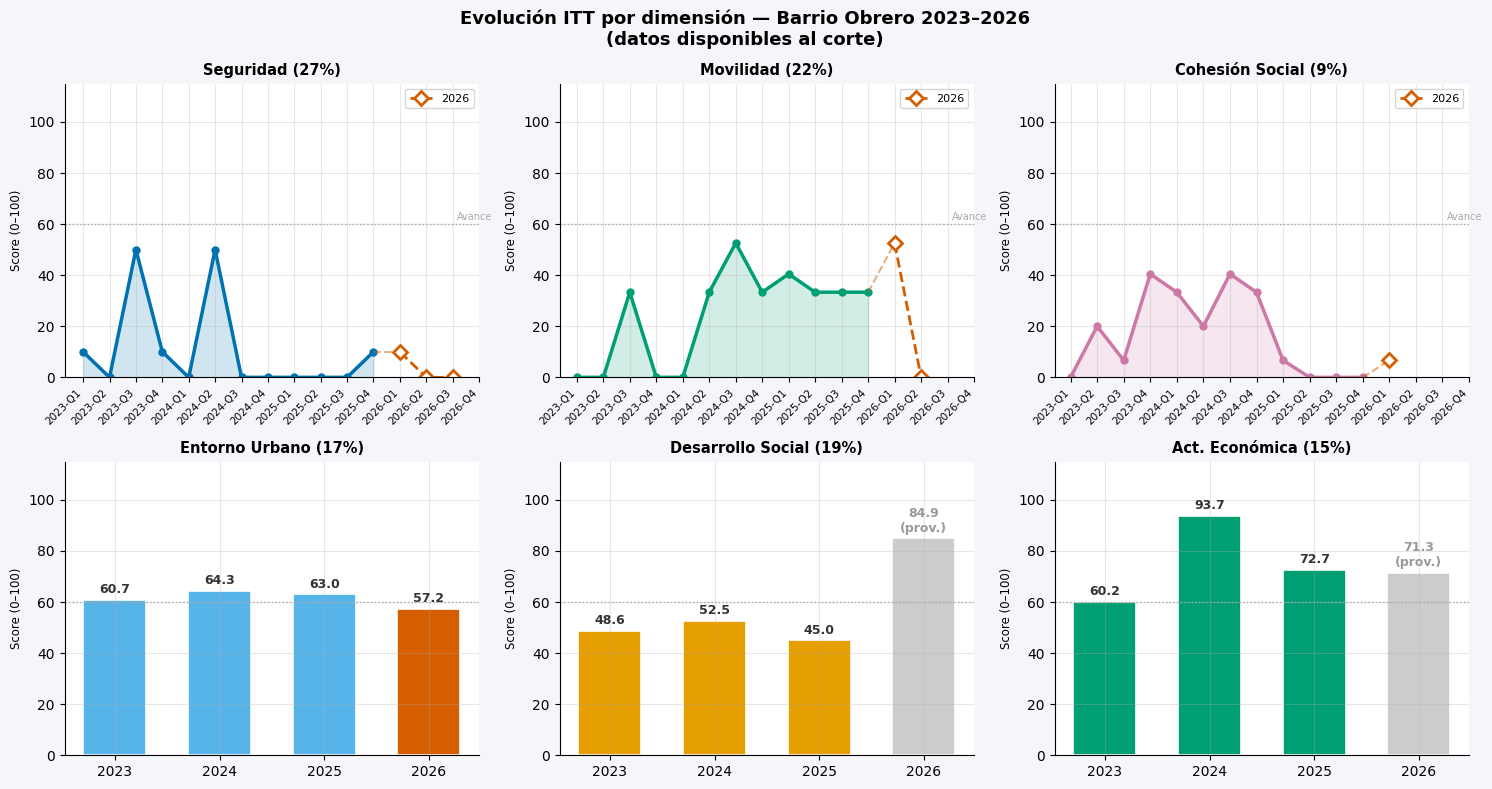

Guardado: itt_dimensiones_evolucion_2026.png


In [177]:
# ══════════════════════════════════════════════════════════════════════════════
# Celda: Evolución por dimensión 2023–2026 (datos disponibles al corte)
# ══════════════════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

OKI_AZUL    = '#0072B2'
OKI_VERDE   = '#009E73'
OKI_NARANJA = '#E69F00'
OKI_BERMELL = '#D55E00'
OKI_MORADO  = '#CC79A7'
OKI_AZUL_C  = '#56B4E9'

def _sr(v, rmin, rmax, inv=False):
    if pd.isna(v): return np.nan
    raw = np.clip((v - rmin) / (rmax - rmin) * 100, 0, 100)
    return 100 - raw if inv else raw

# ── Scores trimestrales desde corr_trim ───────────────────────────────────────
SPA_TRIM = {
    (2023,1):6,  (2023,2):1,  (2023,3):2,  (2023,4):0,
    (2024,1):0,  (2024,2):1,  (2024,3):0,  (2024,4):0,
    (2025,1):2,  (2025,2):17, (2025,3):6,  (2025,4):4,
    (2026,1):2,
}

df = corr_trim.copy()
df['sc_hom'] = df['homicidios'].apply(lambda v: _sr(v, 0,    5/4,  True))
df['sc_hur'] = df['hurtos'].apply(    lambda v: _sr(v, 10/4, 60/4, True))
df['sc_sin'] = df['siniestralidad'].apply(lambda v: _sr(v, 1/4, 15/4, True))
df['sc_les'] = df['lesionados'].apply(    lambda v: _sr(v, 1/4, 12/4, True))
df['sc_mor'] = df['mortales'].apply(      lambda v: _sr(v, 0,   3/4,  True))
df['sc_vif'] = df['vif'].apply(  lambda v: _sr(v, 1/4, 15/4, True))
df['sc_rin'] = df['rinas'].apply(lambda v: _sr(v, 0,   10/4, True))
df['sc_spa'] = df.apply(
    lambda r: _sr(SPA_TRIM.get((r['año'], r['trimestre']), np.nan), 0, 10/4, True), axis=1)

df['score_seg_q'] = (df['sc_hom'] + df['sc_hur']) / 2
df['score_mov_q'] = (df['sc_sin'] + df['sc_les'] + df['sc_mor']) / 3
df['score_coh_q'] = (df['sc_vif'] + df['sc_rin'] + df['sc_spa']) / 3

# ── Figura 2×3 ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Evolución ITT por dimensión — Barrio Obrero 2023–2026\n(datos disponibles al corte)',
             fontsize=13, fontweight='bold')

ANIOS = [2023, 2024, 2025, 2026]

# ── Fila 1: dimensiones trimestrales ─────────────────────────────────────────
cfg_q = [
    (axes[0,0], 'score_seg_q', 'Seguridad (27%)',      OKI_AZUL),
    (axes[0,1], 'score_mov_q', 'Movilidad (22%)',       OKI_VERDE),
    (axes[0,2], 'score_coh_q', 'Cohesión Social (9%)',  OKI_MORADO),
]
for ax, col, titulo, color in cfg_q:
    periodos = df['periodo'].tolist()
    vals     = df[col].values.astype(float)
    x        = np.arange(len(periodos))
    is_2026  = df['año'].values == 2026

    x_h, v_h = x[~is_2026], vals[~is_2026]
    x_6, v_6 = x[is_2026],  vals[is_2026]

    ax.fill_between(x_h, np.where(~np.isnan(v_h), v_h, np.nan), alpha=0.18, color=color)
    ax.plot(x_h, np.where(~np.isnan(v_h), v_h, np.nan),
            color=color, linewidth=2.5, marker='o', markersize=5)

    valid_6 = ~np.isnan(v_6)
    if valid_6.any():
        ax.plot([x_h[-1], x_6[0]], [v_h[-1], v_6[0]],
                color=OKI_BERMELL, linewidth=1.5, linestyle='--', alpha=0.5)
        ax.plot(x_6[valid_6], v_6[valid_6],
                color=OKI_BERMELL, linewidth=2, linestyle='--',
                marker='D', markersize=7,
                markerfacecolor='white', markeredgewidth=2, label='2026')

    ax.axhline(60, color='#AAAAAA', linestyle=':', linewidth=1)
    ax.text(len(periodos) - 0.5, 61.5, 'Avance', fontsize=7,
            color='#AAAAAA', ha='right')
    ax.set_ylim(0, 115)
    ax.set_xticks(x)
    ax.set_xticklabels(periodos, rotation=45, ha='right', fontsize=7.5)
    ax.set_title(titulo, fontsize=10.5, fontweight='bold')
    ax.set_ylabel('Score (0–100)', fontsize=8.5)
    ax.spines[['top', 'right']].set_visible(False)
    if valid_6.any():
        ax.legend(fontsize=8, framealpha=0.8)

# ── Fila 2: dimensiones anuales ───────────────────────────────────────────────
base_idx = base.set_index('año')

# es_real_2026: True = dato real en 2026 / False = provisional
cfg_a = [
    (axes[1,0], 'score_entorno_u',   'Entorno Urbano (17%)',   OKI_AZUL_C,  True),
    (axes[1,1], 'score_des_social',  'Desarrollo Social (19%)', OKI_NARANJA, False),
    (axes[1,2], 'score_des_eco',     'Act. Económica (15%)',   OKI_VERDE,   False),
]
for ax, col, titulo, color, es_real in cfg_a:
    vals = [float(base_idx.loc[a, col])
            if a in base_idx.index and not pd.isna(base_idx.loc[a, col])
            else np.nan for a in ANIOS]

    colores = [OKI_BERMELL if (a == 2026 and es_real) else
               '#CCCCCC'   if (a == 2026 and not es_real) else
               color for a in ANIOS]

    bars = ax.bar(range(4), vals, color=colores, width=0.6,
                  edgecolor='white', linewidth=1.2)

    for i, (bar, v) in enumerate(zip(bars, vals)):
        if not np.isnan(v):
            es_prov = ANIOS[i] == 2026 and not es_real
            ax.text(bar.get_x() + bar.get_width()/2, v + 1.5,
                    f'{v:.1f}' + ('\n(prov.)' if es_prov else ''),
                    ha='center', va='bottom', fontsize=9,
                    fontweight='bold',
                    color='#999999' if es_prov else '#333333')

    # (nota 'sin dato 2026' retirada de la vista)
    ax.axhline(60, color='#AAAAAA', linestyle=':', linewidth=1)
    ax.set_ylim(0, 115)
    ax.set_xticks(range(4))
    ax.set_xticklabels([str(a) for a in ANIOS], fontsize=10)
    ax.set_title(titulo, fontsize=10.5, fontweight='bold')
    ax.set_ylabel('Score (0–100)', fontsize=8.5)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
_img_dir = IMG_DIR if 'IMG_DIR' in dir() else Path('.')
plt.savefig(_img_dir / 'itt_dimensiones_evolucion_2026.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Guardado: {_img_dir / 'itt_dimensiones_evolucion_2026.png'}")


In [178]:
# ── Métricas Clave — Dashboard ITT Barrio Obrero ──────────────────────────────
def safe_pct(new, old):
    if old == 0: return 0.0
    return (new - old) / old * 100

def delta_lbl(pct, inv=True):
    if abs(pct) < 1: return '→ Sin cambio', 'gray'
    mejora = (pct < 0) if inv else (pct > 0)
    sym = '↑' if pct > 0 else '↓'
    return f'{sym} {abs(pct):.1f}%', ('#2E7D32' if mejora else '#C62828')

año_base = ANIOS[0]   # 2023 — línea base
año_ref  = 2025       # último año completo
año_ult  = ANIOS[-1]  # 2026

d_base = base[base['año'] == año_base].iloc[0]
d_ref  = base[base['año'] == año_ref].iloc[0]
d_ult  = base[base['año'] == año_ult].iloc[0]

# (titulo, columna, color, inverso, es_score_0-100, es_provisional)
CARDS = [
    ('ITT Global',         'ITT',              '#1B4F8A',   False, True,  False),
    ('Seguridad',          'score_seguridad',  OKI_BERMELL, False, True,  False),
    ('Movilidad',          'score_movilidad',  OKI_VERDE,   False, True,  False),
    ('Desarrollo Social',  'score_des_social', OKI_MORADO,  False, True,  False),
    ('Entorno Urbano',     'score_entorno_u',  OKI_AZUL_C,  False, True,  False),
    ('Act. Económica',     'score_des_eco',    OKI_VERDE,   False, True,  True),
    ('Homicidios',         'homicidios',      '#E53935',   True,  False, False),
    ('Hurtos',             'hurtos',          '#FB8C00',   True,  False, False),
]

fig = plt.figure(figsize=(18, 9), facecolor=BG)
fig.suptitle(f'Métricas Clave ITT — Barrio Obrero | {año_base}–{año_ult}',
             fontsize=14, fontweight='bold', color='#1B2631', y=0.99)

for i, (titulo, col, color, inv, es_score, es_prov) in enumerate(CARDS):
    ax = fig.add_subplot(3, 3, i + 1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')

    is_itt   = (col == 'ITT')
    bg_col   = '#EAF3FB' if is_itt else 'white'
    edge_col = color if is_itt else '#DEE2E6'
    edge_w   = 2.5   if is_itt else 1.2

    # Fondo card
    ax.add_patch(mpatches.FancyBboxPatch(
        (0.03, 0.03), 0.94, 0.94,
        boxstyle='round,pad=0.02',
        linewidth=edge_w, edgecolor=edge_col, facecolor=bg_col))

    # Banda de color izquierda
    ax.add_patch(mpatches.FancyBboxPatch(
        (0.03, 0.03), 0.055, 0.94,
        boxstyle='round,pad=0.01',
        linewidth=0, facecolor=color, alpha=0.9))

    v_base = float(d_base[col])
    v_ref  = float(d_ref[col])
    v_ult  = float(d_ult[col])

    # Título
    ax.text(0.56, 0.88, titulo,
            ha='center', va='center', fontsize=9.5,
            color='#444444', fontweight='bold')

    # Valor principal
    fmt = f'{v_ult:.1f}' if es_score else str(int(round(v_ult)))
    ax.text(0.56, 0.64, fmt,
            ha='center', va='center', fontsize=22,
            fontweight='bold', color=color)

    # Badge nivel ITT
    if is_itt and 'nivel' in d_ult.index:
        nivel  = str(d_ult['nivel'])
        ncolor = NIVEL_COLORS.get(nivel, '#888888')
        ax.text(0.56, 0.46, nivel.upper(),
                ha='center', va='center', fontsize=8.5,
                fontweight='bold', color=ncolor,
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white',
                          edgecolor=ncolor, linewidth=1.5))

    # Mini barra 0–100 (solo scores)
    if es_score:
        bx0, by, bw, bh = 0.14, 0.35, 0.72, 0.055
        ax.add_patch(mpatches.Rectangle(
            (bx0, by), bw, bh, facecolor='#EEEEEE', linewidth=0))
        fill_w = np.clip(v_ult / 100, 0, 1) * bw
        ax.add_patch(mpatches.Rectangle(
            (bx0, by), fill_w, bh, facecolor=color, linewidth=0, alpha=0.75))
        # Marca en 60 (umbral Transformación)
        ax.add_patch(mpatches.Rectangle(
            (bx0 + 0.60 * bw, by - 0.012), 0.004, bh + 0.024,
            facecolor='#888888', linewidth=0, alpha=0.55))

    # Comparaciones
    pct1 = safe_pct(v_ult, v_ref)
    lbl1, col1 = delta_lbl(pct1, inv)
    ax.text(0.56, 0.24, f'{año_ult} vs {año_ref}: {lbl1}',
            ha='center', fontsize=8, color=col1, fontweight='bold')

    pct2 = safe_pct(v_ult, v_base)
    lbl2, col2 = delta_lbl(pct2, inv)
    ax.text(0.56, 0.13, f'vs {año_base}: {lbl2}',
            ha='center', fontsize=7.5, color=col2)

    if es_prov:

plt.tight_layout(rect=[0, 0, 1, 0.97])
from pathlib import Path
_img_dir = IMG_DIR if 'IMG_DIR' in dir() else Path('/content')
plt.savefig(_img_dir / 'itt_obrero_metricas_clave.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print(f"Guardado: {_img_dir / 'itt_obrero_metricas_clave.png'}")


IndentationError: expected an indented block after 'if' statement on line 106 (707170824.py, line 108)

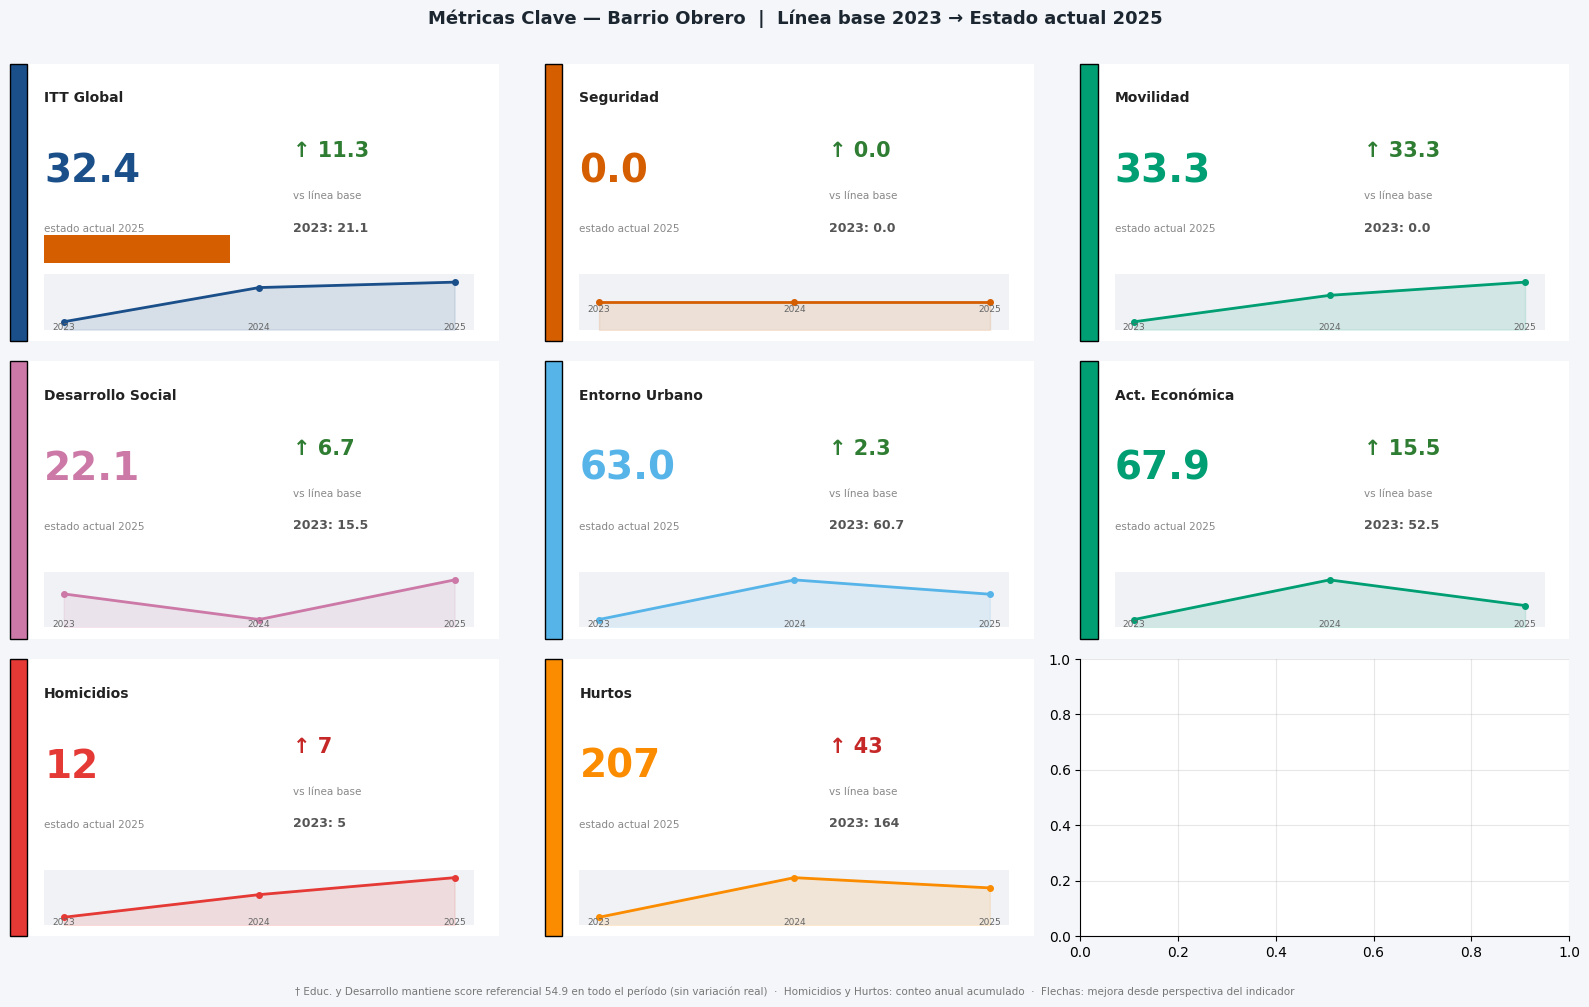

✓ Métricas Clave 2023–2025 generadas


In [ ]:
# ── Métricas Clave · Línea base 2023 → Estado actual 2025 ──────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

_img_dir = IMG_DIR if 'IMG_DIR' in dir() else Path('/content')

# scores anuales (solo 2023-2025)
df_base = base[base['año'].isin([2023, 2024, 2025])].set_index('año')

# indicadores crudos anuales desde corr_trim
raw_anual = (corr_trim[corr_trim['año'].isin([2023, 2024, 2025])]
             .groupby('año')[['homicidios', 'hurtos']].sum())

# (título, columna, color, fuente_raw, es_inverso, es_provisional)
CARDS = [
    ('ITT Global',         'ITT',              '#1B4F8A', False, False, False),
    ('Seguridad',          'score_seguridad',  '#D55E00', False, False, False),
    ('Movilidad',          'score_movilidad',  '#009E73', False, False, False),
    ('Desarrollo Social',  'score_des_social', '#CC79A7', False, False, False),
    ('Entorno Urbano',     'score_entorno_u',  '#56B4E9', False, False, False),
    ('Act. Económica',     'score_des_eco',    '#009E73', False, False, False),
    ('Homicidios',         'homicidios',      '#E53935', True,  True,  False),
    ('Hurtos',             'hurtos',          '#FB8C00', True,  True,  False),
]

fig, axes = plt.subplots(3, 3, figsize=(16, 10))
fig.patch.set_facecolor('#F4F6F9')

for ax, (title, col, color, is_raw, es_inverso, es_prov) in zip(axes.flatten(), CARDS):
    ax.set_facecolor('white')
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_xticks([]); ax.set_yticks([])

    src = raw_anual if is_raw else df_base
    try:
        v23 = float(src.loc[2023, col])
        v24 = float(src.loc[2024, col])
        v25 = float(src.loc[2025, col])
    except (KeyError, TypeError):
        ax.text(0.5, 0.5, 'Sin datos', transform=ax.transAxes,
                ha='center', va='center', fontsize=10, color='#999')
        continue

    delta   = v25 - v23
    mejora  = (delta < 0) if es_inverso else (delta >= 0)
    arrow   = '↑' if delta >= 0 else '↓'
    d_color = '#2E7D32' if mejora else '#C62828'
    fmt     = '.0f' if is_raw else '.1f'

    # banda de color izquierda
    ax.add_patch(mpatches.FancyBboxPatch(
        (0.0, 0.0), 0.035, 1.0, boxstyle='square,pad=0',
        transform=ax.transAxes, facecolor=color, zorder=3, clip_on=False))

    # título
    ax.text(0.07, 0.90, title, transform=ax.transAxes,
            fontsize=10, fontweight='bold', va='top', color='#222222')

    # valor principal 2025
    ax.text(0.07, 0.68, f'{v25:{fmt}}', transform=ax.transAxes,
            fontsize=28, fontweight='bold', va='top', color=color)
    ax.text(0.07, 0.42, 'estado actual 2025', transform=ax.transAxes,
            fontsize=7.5, va='top', color='#888888')

    # delta vs línea base
    ax.text(0.58, 0.72, f'{arrow} {abs(delta):{fmt}}',
            transform=ax.transAxes, fontsize=15, fontweight='bold',
            va='top', color=d_color)
    ax.text(0.58, 0.54, f'vs línea base', transform=ax.transAxes,
            fontsize=7.5, va='top', color='#888888')
    ax.text(0.58, 0.43, f'2023: {v23:{fmt}}', transform=ax.transAxes,
            fontsize=9, va='top', color='#555555', fontweight='bold')

    # nivel badge (solo ITT Global)
    if col == 'ITT':
        nivel = clasificar(v25)
        nc = NIVEL_COLORS.get(nivel, '#888888')
        badge = ax.inset_axes([0.07, 0.28, 0.38, 0.10])
        badge.set_facecolor(nc); badge.set_alpha(0.15)
        for s in badge.spines.values(): s.set_visible(False)
        badge.set_xticks([]); badge.set_yticks([])
        ax.text(0.265, 0.315, nivel, transform=ax.transAxes,
                ha='center', va='center', fontsize=8.5,
                fontweight='bold', color=nc)

    # badge provisional
    if es_prov:

    # sparkline 2023 → 2024 → 2025
    sp_ax = ax.inset_axes([0.07, 0.04, 0.88, 0.20])
    sp_ax.set_facecolor('#F0F2F5')
    for s in sp_ax.spines.values(): s.set_visible(False)
    sp_ax.set_xticks([]); sp_ax.set_yticks([])

    vals = [v23, v24, v25]
    ylo  = min(vals); yhi = max(vals)
    pad  = (yhi - ylo) * 0.2 if yhi > ylo else 1.0
    sp_ax.set_ylim(ylo - pad, yhi + pad)

    sp_ax.plot([0, 1, 2], vals, color=color, lw=2, marker='o', ms=4, zorder=3)
    sp_ax.fill_between([0, 1, 2], vals, ylo - pad, alpha=0.12, color=color)
    for xi, yr in zip([0, 1, 2], ['2023', '2024', '2025']):
        sp_ax.text(xi, ylo - pad * 0.1, yr,
                   ha='center', va='top', fontsize=6.5, color='#666666')

fig.suptitle(
    'Métricas Clave — Barrio Obrero  |  Línea base 2023 → Estado actual 2025',
    fontsize=13, fontweight='bold', y=0.99, color='#1B2631')



plt.tight_layout(rect=[0, 0.025, 1, 0.985])
plt.savefig(_img_dir / 'metricas_clave_linea_base.png',
            dpi=150, bbox_inches='tight', facecolor='#F4F6F9')
plt.show()
print("✓ Métricas Clave 2023–2025 generadas")


## Celda 17 — Exportar a Excel


In [ ]:
# ── Exportar consolidación ITT — 5 dimensiones ───────────────────────────────
import os, openpyxl
from openpyxl.styles import PatternFill, Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from pathlib import Path

OUT_DIR = REPO / "outputs" / "itt_barrio_obrero"
OUT_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_PATH = OUT_DIR / "ITT_Barrio_Obrero_Consolidado.xlsx"

# ── Hoja 1: ITT Resumen Anual ─────────────────────────────────────────────────
cols_anual = [
    'año',
    'score_seguridad','score_movilidad','score_des_social',
    'score_entorno_u','score_des_eco',
    'ITT','nivel'
]
cols_anual   = [c for c in cols_anual if c in base.columns]
df_itt_anual = base[cols_anual].copy().round(2)
df_itt_anual['nota_estado'] = df_itt_anual['año'].apply(
    lambda a: 'Parcial Q1-Q2 | DesSocial y DesEco referenciales' if a == 2026 else 'Real'
)

# ── Hoja 2: ITT Trimestral ────────────────────────────────────────────────────
if 'df_evol' in dir():
    _df_evol = df_evol.copy()
    if 'parcial' not in _df_evol.columns:
        _df_evol['parcial'] = _df_evol['año'] == 2026
    df_itt_trim = _df_evol.round(2)
else:
    df_itt_trim = pd.DataFrame({'nota': ['Ejecutar celda de Evolucion Trimestral primero']})

# ── Hoja 3: Seguridad ─────────────────────────────────────────────────────────
_seg_raw = corr_trim.groupby('año')[['homicidios','hurtos']].sum().reset_index()
_seg_sc  = base[['año','score_seguridad']].copy()
df_seg   = _seg_raw.merge(_seg_sc, on='año', how='left')
df_seg['score_homicidios'] = df_seg['homicidios'].apply(
    lambda v: round(score_ref(v, *REFS['homicidios'][:3]), 1))
df_seg['score_hurtos'] = df_seg['hurtos'].apply(
    lambda v: round(score_ref(v, *REFS['hurtos'][:3]), 1))
df_seg['nota_estado'] = df_seg['año'].apply(
    lambda a: 'Parcial Q1-Q2' if a == 2026 else 'Real')
df_seg = df_seg[['año','homicidios','hurtos',
                  'score_homicidios','score_hurtos',
                  'score_seguridad','nota_estado']].round(2)

# ── Hoja 4: Movilidad ─────────────────────────────────────────────────────────
_mov_raw = corr_trim.groupby('año')[['siniestralidad','lesionados','mortales']].sum().reset_index()
_mov_sc  = base[['año','score_movilidad']].copy()
df_mov   = _mov_raw.merge(_mov_sc, on='año', how='left')
df_mov['score_siniestralidad'] = df_mov['siniestralidad'].apply(
    lambda v: round(score_ref(v, *REFS['siniestralidad'][:3]), 1))
df_mov['score_lesionados'] = df_mov['lesionados'].apply(
    lambda v: round(score_ref(v, *REFS['lesionados'][:3]), 1))
df_mov['score_mortales'] = df_mov['mortales'].apply(
    lambda v: round(score_ref(v, *REFS['mortales'][:3]), 1))
df_mov['nota_estado'] = df_mov['año'].apply(
    lambda a: 'Parcial Q1-Q2' if a == 2026 else 'Real')
df_mov = df_mov[['año','siniestralidad','lesionados','mortales',
                  'score_siniestralidad','score_lesionados','score_mortales',
                  'score_movilidad','nota_estado']].round(2)

# ── Hoja 5: Cohesion Social ───────────────────────────────────────────────────
# VIF y riñas: corr_trim | SPA: base (viene de comparendos, no de corr_trim)
_coh_raw = corr_trim.groupby('año')[['vif','rinas']].sum().reset_index()
_coh_spa = base[['año'] + [c for c in ['spa','score_spa','score_cohesion'] if c in base.columns]].copy()
df_coh   = _coh_raw.merge(_coh_spa, on='año', how='left')
df_coh['score_vif']   = df_coh['vif'].apply(
    lambda v: round(score_ref(v, *REFS['vif'][:3]), 1))
df_coh['score_rinas'] = df_coh['rinas'].apply(
    lambda v: round(score_ref(v, *REFS['rinas'][:3]), 1))
df_coh['nota_estado'] = df_coh['año'].apply(
    lambda a: 'Parcial Q1-Q2' if a == 2026 else 'Real')
_coh_cols = ['año','vif','rinas']
if 'spa' in df_coh.columns:       _coh_cols += ['spa']
_coh_cols += ['score_vif','score_rinas']
if 'score_spa' in df_coh.columns: _coh_cols += ['score_spa']
_coh_cols += ['score_cohesion','nota_estado']
df_coh = df_coh[_coh_cols].round(2)

# ── Hoja 6: Entorno Urbano ────────────────────────────────────────────────────
filas_eu = []
for año in ANIOS:
    st   = ndvi_stats.get(año, {})
    brow = base[base['año'] == año]
    filas_eu.append({
        'año':                     año,
        'ndvi_mean':               round(st.get('ndvi_mean', np.nan), 4),
        'pct_verde_%':             round(st.get('pct_verde',  np.nan), 1),
        'area_verde_m2':           round(st.get('verde_m2',   np.nan), 0),
        'densidad_arboles_arb_ha': round(globals().get('dens_arboles_ha', np.nan), 1),
        'score_entorno_u':         round(float(brow['score_entorno_u'].iloc[0]), 2) if not brow.empty else np.nan,
        'nota_estado':             'Real (NDVI anual + DAGMA)',
    })
df_eu = pd.DataFrame(filas_eu)

# ── Hoja 7: Educacion ─────────────────────────────────────────────────────────
filas_educ = []
for año in AÑOS_EDUC:
    try:    m_f = float(matricula_simat.get(año, np.nan))
    except: m_f = np.nan
    try:    d_f = float(desertores_educ.get(año, np.nan))
    except: d_f = np.nan
    try:    r_f = float(repitentes_simat.get(año, np.nan))
    except: r_f = np.nan
    tasa_des = round(d_f/m_f*100, 2) if (not np.isnan(d_f) and not np.isnan(m_f) and m_f > 0) else np.nan
    tasa_rep = round(r_f/m_f*100, 2) if (not np.isnan(r_f) and not np.isnan(m_f) and m_f > 0) else np.nan
    brow = base[base['año'] == año]
    sc   = round(float(brow['score_educ_des'].iloc[0]), 2) if not brow.empty else np.nan
    filas_educ.append({
        'año': año, 'matricula': m_f, 'desertores': d_f, 'repitentes': r_f,
        'tasa_desercion_%': tasa_des, 'tasa_repitencia_%': tasa_rep,
        'score_educ_des': sc,
        'observacion': '',
        'nota_estado': 'Real (SIMAT + SIMPADE)' if not np.isnan(sc) else 'Sin datos — SIMAT requerido',
    })
# Fila 2026 INFORMATIVA (corte marzo SIMAT): matricula/repitentes del consolidado.
# Desercion NaN (SIMPADE 2026 no existe, anio no cerrado). NO entra al ITT anual.
try:
    import json as _json
    _cons_edu = _json.load(open(REPO / "data" / "itt_barrio_obrero" / "6_Educacion" / "educacion_BO_2023_2026_consolidado.json", encoding="utf-8"))
    _m26 = _cons_edu["matricula"].get("2026")
    _r26 = _cons_edu["repitentes"].get("2026")
    if _m26:
        _trep26 = round(_r26 / _m26 * 100, 2) if _r26 else np.nan
        filas_educ.append({
            'año': 2026, 'matricula': float(_m26), 'desertores': np.nan, 'repitentes': float(_r26),
            'tasa_desercion_%': np.nan, 'tasa_repitencia_%': _trep26, 'score_educ_des': np.nan,
            'observacion': 'Corte marzo 2026 - informativo, NO entra al ITT (anio no cerrado, sin desercion SIMPADE)',
            'nota_estado': 'Parcial marzo 2026',
        })
except Exception as _e:
    print(f"[aviso] no se pudo agregar fila educacion 2026: {type(_e).__name__}")
df_educ = pd.DataFrame(filas_educ).round(2)

# ── Hoja 8: Desarrollo Economico ─────────────────────────────────────────────
if 'df_de_scores' in dir():
    df_de_export = df_de_scores.copy().round(2)
elif 'df_de_anual' in dir():
    df_de_export = df_de_anual.copy().round(2)
else:
    df_de_export = pd.DataFrame({'nota': ['Ejecutar celdas DE primero']})
if 'año' in df_de_export.columns:
    def _nota_de_stock(a):
        if a == 2026:
            return 'Real (stock activo consolidado; 2026 parcial, no comparable)'
        return 'Real (stock activo consolidado)'
    df_de_export['nota_estado'] = df_de_export['año'].apply(_nota_de_stock)

# ── Hoja 9: Indicadores Trimestrales (raw) ───────────────────────────────────
df_trim_export = corr_trim.copy()

# ── Armar hojas ───────────────────────────────────────────────────────────────
sheets = {
    'ITT_Resumen':              df_itt_anual,
    'ITT_Trimestral':           df_itt_trim,
    'Seguridad':                df_seg,
    'Movilidad':                df_mov,
    'Cohesion_Social':          df_coh,
    'Entorno_Urbano':           df_eu,
    'Educacion':                df_educ,
    'Desarrollo_Economico':     df_de_export,
    'Indicadores_Trimestrales': df_trim_export,
}

# ── Escribir Excel ────────────────────────────────────────────────────────────
with pd.ExcelWriter(str(EXPORT_PATH), engine='openpyxl') as writer:
    for sheet_name, df in sheets.items():
        # 'nota_estado' es una columna de uso interno; no se exporta al Excel final.
        df = df.drop(columns=[c for c in ['nota_estado', 'parcial'] if c in df.columns])
        df.to_excel(writer, sheet_name=sheet_name, index=False)

    wb = writer.book
    header_fill = PatternFill('solid', fgColor='1B4F8A')
    header_font = Font(color='FFFFFF', bold=True)
    provis_fill = PatternFill('solid', fgColor='FFF3CD')
    thin        = Side(style='thin', color='CCCCCC')
    border      = Border(left=thin, right=thin, top=thin, bottom=thin)

    for ws in wb.worksheets:
        for cell in ws[1]:
            cell.fill      = header_fill
            cell.font      = header_font
            cell.alignment = Alignment(horizontal='center', wrap_text=True)
        for col in ws.columns:
            max_len = max((len(str(c.value)) for c in col if c.value), default=8)
            ws.column_dimensions[get_column_letter(col[0].column)].width = min(max_len + 3, 35)
        ws.freeze_panes = 'A2'
        col_names = [cell.value for cell in ws[1]]
        año_col   = col_names.index('año') + 1 if 'año' in col_names else None
        for row in ws.iter_rows(min_row=2):
            es_2026 = (año_col and row[año_col - 1].value == 2026)
            for cell in row:
                cell.border    = border
                cell.alignment = Alignment(horizontal='center')
                if es_2026:
                    cell.fill = provis_fill

print(f'Excel guardado: {EXPORT_PATH}')
print(f'Hojas: {", ".join(sheets.keys())}')

try:
    from google.colab import files
    files.download(str(EXPORT_PATH))
    print('Descarga iniciada.')
except ImportError:
    print('Entorno local — archivo en outputs/itt_barrio_obrero/')


Excel guardado: /content/itt_repos_cali/outputs/itt_barrio_obrero/ITT_Barrio_Obrero_Consolidado.xlsx
Hojas: ITT_Resumen, ITT_Trimestral, Seguridad, Movilidad, Cohesion_Social, Entorno_Urbano, Educacion, Desarrollo_Economico, Indicadores_Trimestrales


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descarga iniciada.


In [ ]:
import base64
from IPython.display import HTML

ruta = '/content/itt_repos_cali/outputs/itt_barrio_obrero/ITT_Barrio_Obrero_Consolidado.xlsx'
with open(ruta, 'rb') as f:
    b64 = base64.b64encode(f.read()).decode()

mime = 'application/vnd.openxmlformats-officedocument.spreadsheetml.sheet'
HTML(f'<a href="data:{mime};base64,{b64}" download="ITT_Barrio_Obrero_Consolidado.xlsx">'
     '<b>Haz click aqui para descargar el Excel</b></a>')